# Deep Learning – Practical 02

## Adult Income Prediction Using Artificial Neural Networks

### Objective
Develop, train, evaluate, and optimize Artificial Neural Network (ANN) models to predict whether an individual's annual income exceeds $50,000 using the Adult Income Dataset.

### Project Details
- Dataset: Adult Income Dataset
- Problem Type: Binary Classification
- Model: Multi-Layer Perceptron (MLP)
- Framework: TensorFlow / Keras
- Evaluation Metrics: Accuracy, Precision, Recall, F1-Score and ROC-AUC

### Experimental Tasks
1. Data Loading, Cleaning and Exploratory Data Analysis
2. MLP Architecture – Baseline ANN
3. Activation Functions Comparison
4. Weight Initialization Techniques
5. Loss Functions Comparison
6. Batch Normalization
7. Optimizers – Convergence and Final Comparison

In [20]:
# =============================================================================
# DEEP LEARNING PRACTICAL 02
# ADULT INCOME PREDICTION USING ARTIFICIAL NEURAL NETWORKS
# =============================================================================


# 1. CORE PYTHON LIBRARIES

import os
import gc
import random
import warnings
import zipfile

from pathlib import Path


# 2. DATA MANIPULATION

import numpy as np
import pandas as pd


# 3. DATA VISUALIZATION

import matplotlib.pyplot as plt
import seaborn as sns


# 4. MACHINE LEARNING

import sklearn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)


# 5. DEEP LEARNING

import tensorflow as tf

from tensorflow import keras

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (
    Input,
    Dense,
    Activation,
    BatchNormalization
)

from tensorflow.keras.initializers import (
    GlorotUniform,
    GlorotNormal,
    HeUniform,
    HeNormal,
    Zeros
)

from tensorflow.keras.metrics import (
    Precision,
    Recall
)

from tensorflow.keras.optimizers import (
    SGD,
    RMSprop,
    Adam
)

from tensorflow.keras.losses import (
    BinaryCrossentropy,
    MeanSquaredError
)


# 6. JUPYTER DISPLAY

from IPython.display import display, Markdown


# 7. WARNING CONFIGURATION

warnings.filterwarnings("ignore")


# 8. REPRODUCIBILITY

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


# 9. VISUALIZATION STYLE

sns.set_theme(
    style="whitegrid",
    context="notebook",
    palette="deep"
)

plt.rcParams.update({
    "figure.figsize": (10, 6),
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False
})


# 10. PROJECT DIRECTORIES

PROJECT_DIR = Path.cwd()

DATA_DIR = PROJECT_DIR / "data"
PLOTS_DIR = PROJECT_DIR / "plots"

DATA_DIR.mkdir(exist_ok=True)
PLOTS_DIR.mkdir(exist_ok=True)


# 11. ENVIRONMENT INFORMATION

print("=" * 65)
print("DEEP LEARNING PRACTICAL 02")
print("ENVIRONMENT INITIALIZATION")
print("=" * 65)

print(f"NumPy Version       : {np.__version__}")
print(f"Pandas Version      : {pd.__version__}")
print(f"Matplotlib Version  : {plt.matplotlib.__version__}")
print(f"Seaborn Version     : {sns.__version__}")
print(f"Scikit-learn        : {sklearn.__version__}")
print(f"TensorFlow Version  : {tf.__version__}")

print("-" * 65)

print(f"Project Directory  : {PROJECT_DIR}")
print(f"Data Directory     : {DATA_DIR}")
print(f"Plots Directory    : {PLOTS_DIR}")

print("-" * 65)

print(f"Random Seed        : {SEED}")
print("Visualization      : Configured")
print("Reproducibility    : Configured")

print("=" * 65)
print("ALL LIBRARIES IMPORTED SUCCESSFULLY!")
print("=" * 65)

DEEP LEARNING PRACTICAL 02
ENVIRONMENT INITIALIZATION
NumPy Version       : 2.3.2
Pandas Version      : 2.3.1
Matplotlib Version  : 3.10.0
Seaborn Version     : 0.13.2
Scikit-learn        : 1.8.0
TensorFlow Version  : 2.21.0
-----------------------------------------------------------------
Project Directory  : C:\Users\urenp
Data Directory     : C:\Users\urenp\data
Plots Directory    : C:\Users\urenp\plots
-----------------------------------------------------------------
Random Seed        : 42
Visualization      : Configured
Reproducibility    : Configured
ALL LIBRARIES IMPORTED SUCCESSFULLY!


# TASK 1: Data Loading, Cleaning & Exploratory Data Analysis

## 1.1 Dataset Loading and Initial Inspection
Load the Adult Income Dataset and inspect its structure, dimensions, data types and statistical properties.

## 1.2 Missing Value Detection and Treatment
Identify missing values represented by '?' and remove rows containing missing values.

## 1.3 Redundant Column Removal
Remove fnlwgt and education because they are not required for this experiment.

## 1.4 Target Variable Encoding
Encode income into binary categories:
- <=50K = 0
- >50K = 1

Analyze the class distribution and identify class imbalance.

## 1.5 Exploratory Data Analysis
Create four visualizations:
1. Age distribution by income.
2. Weekly working hours boxplot.
3. Education level countplot.
4. Numerical correlation heatmap.

## 1.6 Feature Encoding, Scaling and Train-Test Split
- Apply One-Hot Encoding to categorical features.
- Apply StandardScaler to numerical features.
- Split the dataset into 80% training and 20% testing.
- Use random_state=42 and stratification.


TASK 1.1: DATASET LOADING AND INITIAL INSPECTION

Dataset Name    : Adult Income Dataset
Dataset File    : adult.csv
Total Records   : 48,842
Total Columns   : 15
Memory Usage    : 26.47 MB

--- FIRST FIVE RECORDS ---


,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K



--- DATASET DIMENSIONS ---
(48842, 15)

--- DATASET INFORMATION ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   age              48842 non-null  int64 
 1   workclass        48842 non-null  object
 2   fnlwgt           48842 non-null  int64 
 3   education        48842 non-null  object
 4   educational-num  48842 non-null  int64 
 5   marital-status   48842 non-null  object
 6   occupation       48842 non-null  object
 7   relationship     48842 non-null  object
 8   race             48842 non-null  object
 9   gender           48842 non-null  object
 10  capital-gain     48842 non-null  int64 
 11  capital-loss     48842 non-null  int64 
 12  hours-per-week   48842 non-null  int64 
 13  native-country   48842 non-null  object
 14  income           48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB

--- ST

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,48842.0,NaN,NaN,NaN,38.643585,13.71051,17.0,28.0,37.0,48.0,90.0
workclass,48842,9,Private,33906,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fnlwgt,48842.0,NaN,NaN,NaN,189664.134597,105604.025423,12285.0,117550.5,178144.5,237642.0,1490400.0
education,48842,16,HS-grad,15784,NaN,NaN,NaN,NaN,NaN,NaN,NaN
educational-num,48842.0,NaN,NaN,NaN,10.078089,2.570973,1.0,9.0,10.0,12.0,16.0
marital-status,48842,7,Married-civ-spouse,22379,NaN,NaN,NaN,NaN,NaN,NaN,NaN
occupation,48842,15,Prof-specialty,6172,NaN,NaN,NaN,NaN,NaN,NaN,NaN
relationship,48842,6,Husband,19716,NaN,NaN,NaN,NaN,NaN,NaN,NaN
race,48842,5,White,41762,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,48842,2,Male,32650,NaN,NaN,NaN,NaN,NaN,NaN,NaN



--- COLUMN NAMES ---
01. age
02. workclass
03. fnlwgt
04. education
05. educational-num
06. marital-status
07. occupation
08. relationship
09. race
10. gender
11. capital-gain
12. capital-loss
13. hours-per-week
14. native-country
15. income

TASK 1.2: MISSING VALUE DETECTION AND TREATMENT

--- MISSING VALUE ANALYSIS ---


,Missing Count,Missing Percentage
occupation,2809,5.751198
workclass,2799,5.730724
native-country,857,1.754637
fnlwgt,0,0.000000
education,0,0.000000
educational-num,0,0.000000
age,0,0.000000
marital-status,0,0.000000
relationship,0,0.000000
gender,0,0.000000



Total Missing Values : 6,465
Affected Rows        : 3,620

--- CLEANED DATASET SUMMARY ---
Original Records  : 48,842
Removed Records   : 3,620
Remaining Records : 45,222
Remaining Columns : 15
Remaining NaN     : 0

TASK 1.3: REDUNDANT FEATURE REMOVAL

--- REMOVED FEATURES ---
Removed: fnlwgt
Removed: education

--- UPDATED DATASET PREVIEW ---


,age,workclass,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,34,Private,6,Never-married,Other-service,Not-in-family,White,Male,0,0,30,United-States,<=50K



Updated Dataset Shape : (45222, 13)
Independent Features  : 12
Target Feature        : 1

TASK 1.4: TARGET VARIABLE ENCODING AND CLASS DISTRIBUTION

--- INCOME CLASS DISTRIBUTION ---


,Income Category,Encoded Value,Records,Percentage
0,<=50K,0,34014,75.215603
1,>50K,1,11208,24.784397


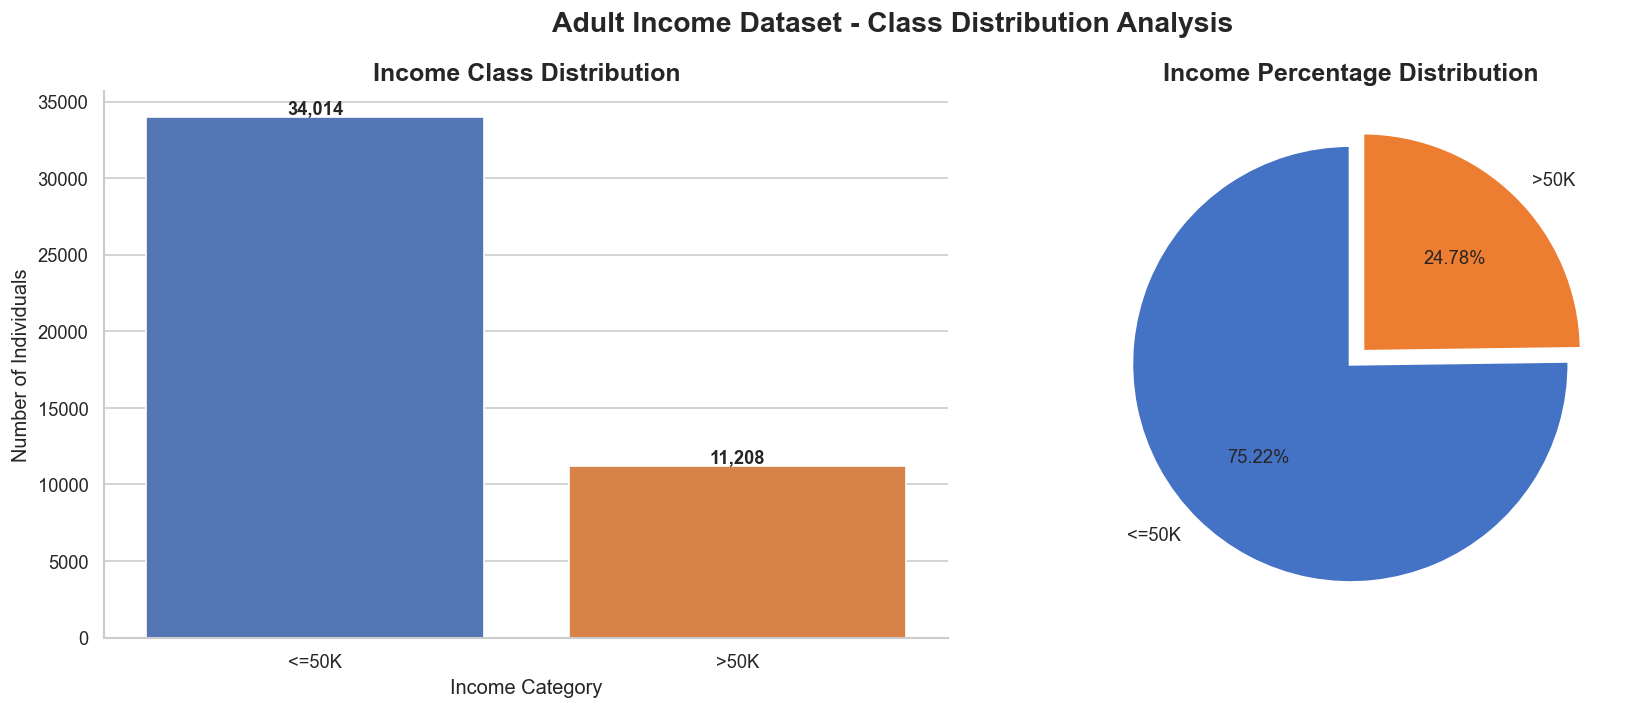


TASK 1.5: EXPLORATORY DATA ANALYSIS (EDA)

EDA 1: AGE DISTRIBUTION BY INCOME


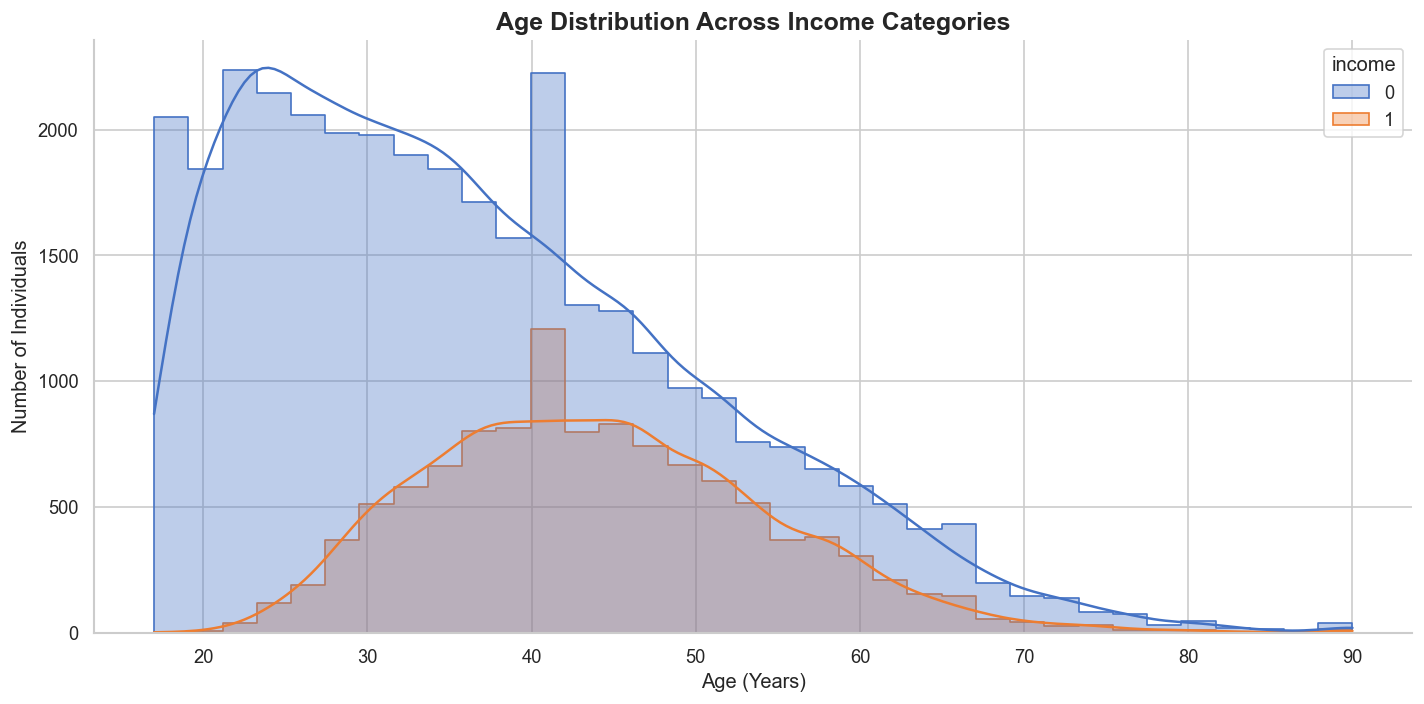


EDA 2: WEEKLY WORKING HOURS BOXPLOT


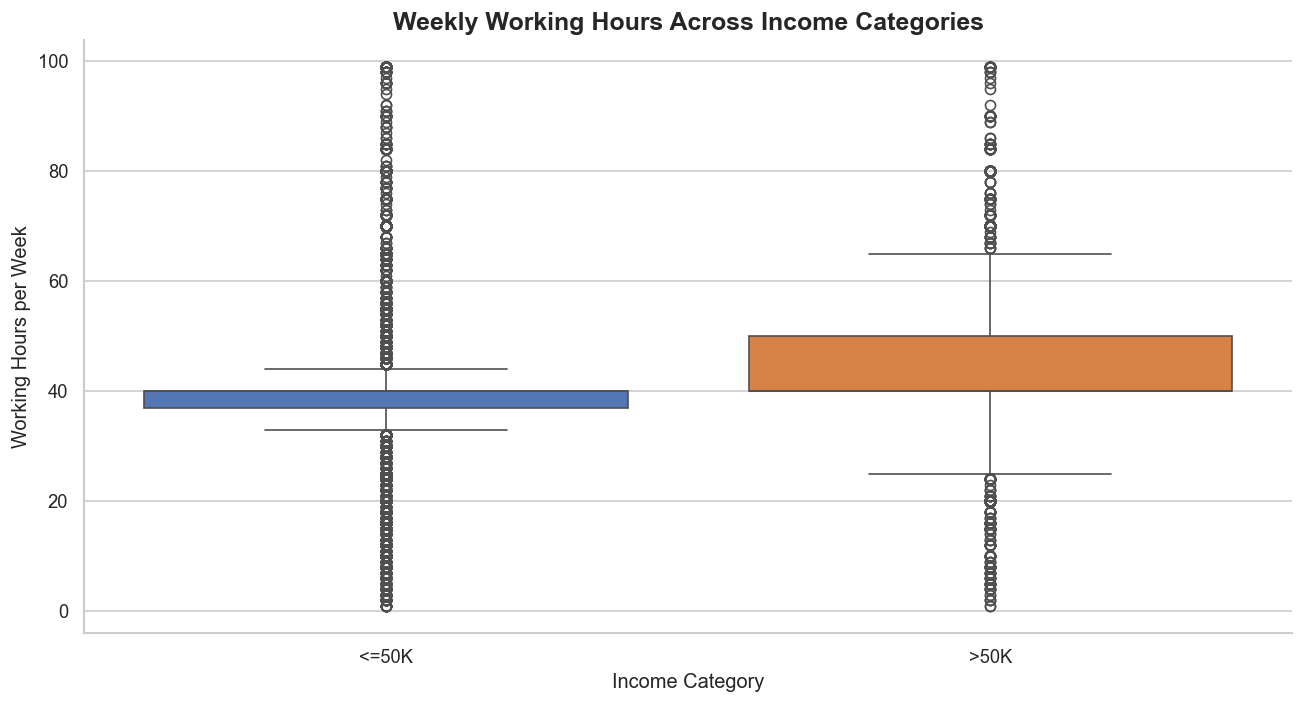


EDA 3: EDUCATION LEVEL COUNTPLOT


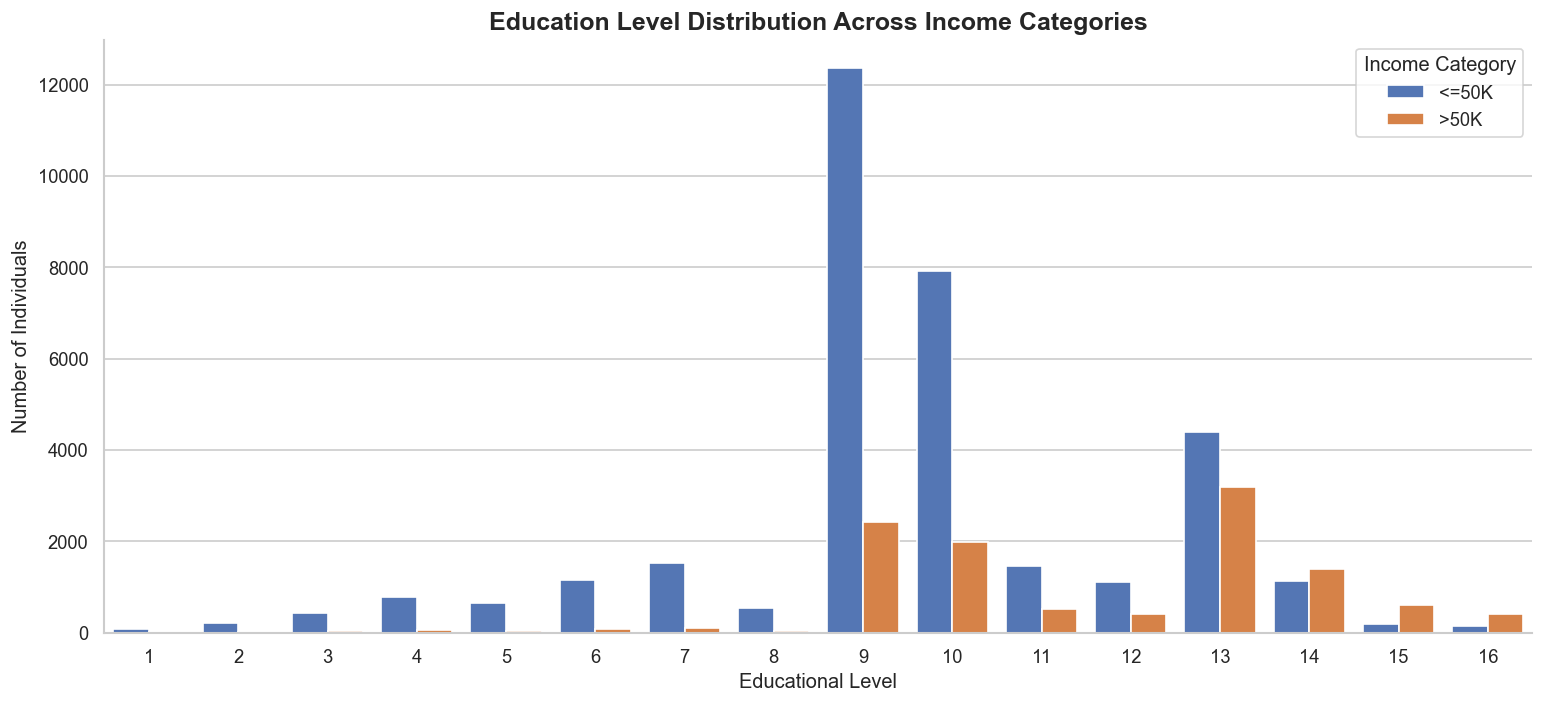


EDA 4: NUMERICAL CORRELATION HEATMAP


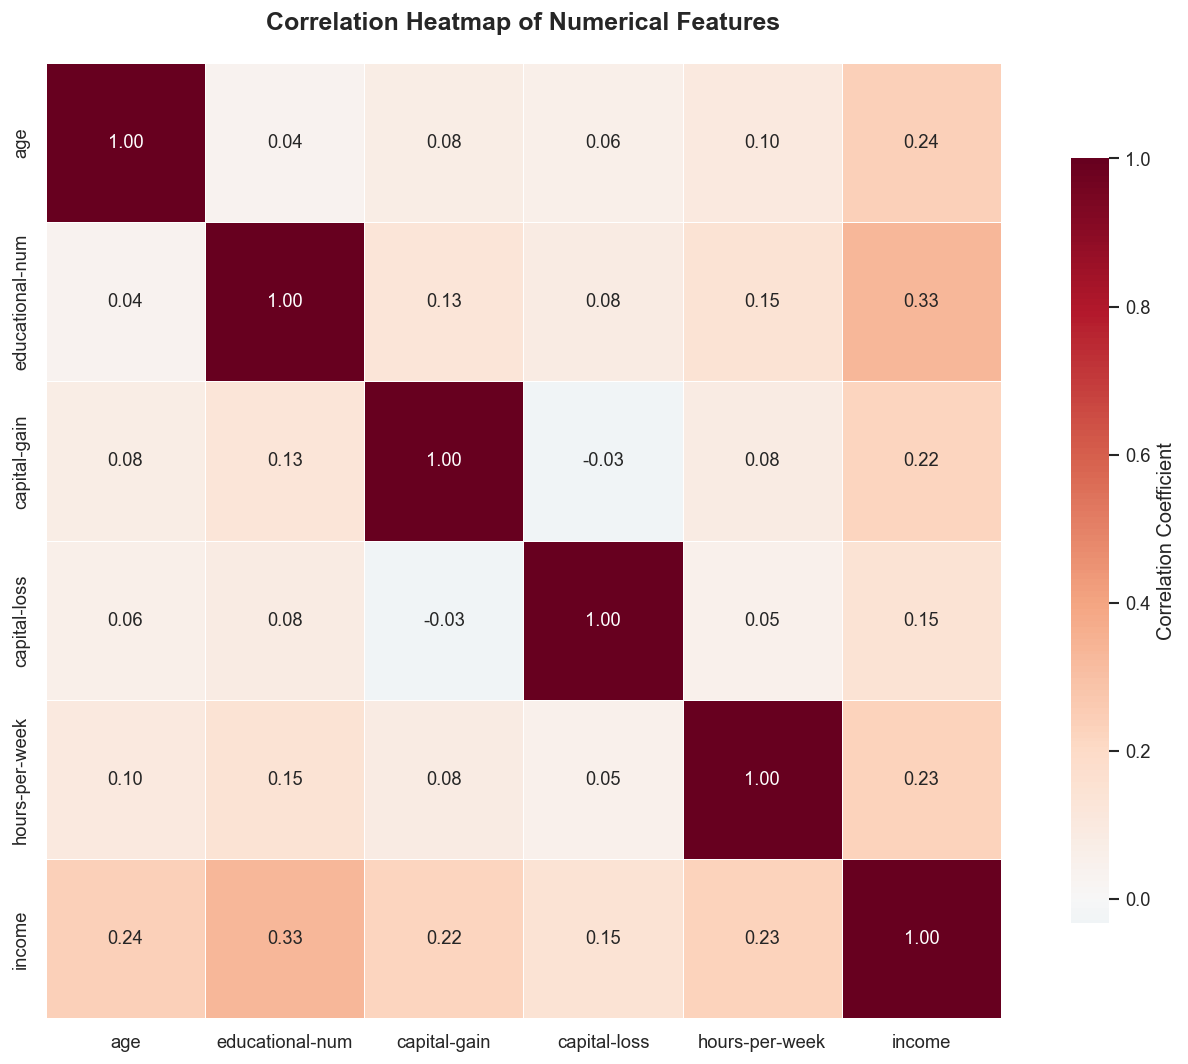


TASK 1.6: FEATURE ENCODING, STANDARDIZATION AND TRAIN-TEST SPLIT

Numerical Features:
['age', 'educational-num', 'capital-gain', 'capital-loss', 'hours-per-week']

Categorical Features:
['workclass', 'marital-status', 'occupation', 'relationship', 'race', 'gender', 'native-country']

--- TRAIN-TEST SPLIT ---
Total Records    : 45,222
Training Records : 36,177
Testing Records  : 9,045

--- ONE-HOT ENCODING ---
Training Features : 80
Testing Features  : 80

--- STANDARD SCALING ---
Standardized: age
Standardized: educational-num
Standardized: capital-gain
Standardized: capital-loss
Standardized: hours-per-week

FINAL PREPROCESSED DATASET SUMMARY
Cleaned Dataset Shape : (45222, 13)
Training Feature Shape: (36177, 80)
Testing Feature Shape : (9045, 80)
Training Target Shape : (36177,)
Testing Target Shape  : (9045,)

Input Dimensions      : 80
Training Data Type    : float32
Testing Data Type     : float32
Training NaN Values   : 0
Testing NaN Values    : 0
Target Classes        : [0. 1.]

In [11]:
# =============================================================================
# TASK 1: DATA LOADING, CLEANING & EXPLORATORY DATA ANALYSIS
# PROJECT: ADULT INCOME PREDICTION USING ANN
# =============================================================================


# =============================================================================
# TASK 1.1: DATASET LOADING AND INITIAL INSPECTION
# =============================================================================

print("\n" + "=" * 85)
print("TASK 1.1: DATASET LOADING AND INITIAL INSPECTION")
print("=" * 85)

# Locate uploaded ZIP file
ZIP_FILE_PATH = Path.cwd() / "adult.csv.zip"

if not ZIP_FILE_PATH.exists():
    ZIP_FILE_PATH = Path("/mnt/data/adult.csv.zip")

if not ZIP_FILE_PATH.exists():
    raise FileNotFoundError("adult.csv.zip not found.")

# Create project directories
PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
PLOTS_DIR = PROJECT_DIR / "plots"

DATA_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

# Extract CSV from ZIP
with zipfile.ZipFile(ZIP_FILE_PATH, "r") as zip_ref:

    csv_files = [
        file for file in zip_ref.namelist()
        if file.lower().endswith(".csv")
    ]

    if not csv_files:
        raise FileNotFoundError("No CSV file found inside ZIP archive.")

    dataset_file = csv_files[0]

    zip_ref.extract(dataset_file, DATA_DIR)

    DATASET_PATH = DATA_DIR / dataset_file

# Load dataset
df_raw = pd.read_csv(DATASET_PATH)

# Display dataset details
print(f"\nDataset Name    : Adult Income Dataset")
print(f"Dataset File    : {DATASET_PATH.name}")
print(f"Total Records   : {df_raw.shape[0]:,}")
print(f"Total Columns   : {df_raw.shape[1]}")
print(f"Memory Usage    : {df_raw.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

print("\n--- FIRST FIVE RECORDS ---")
display(df_raw.head())

print("\n--- DATASET DIMENSIONS ---")
print(df_raw.shape)

print("\n--- DATASET INFORMATION ---")
df_raw.info()

print("\n--- STATISTICAL SUMMARY ---")
display(df_raw.describe(include="all").T)

print("\n--- COLUMN NAMES ---")
for index, column in enumerate(df_raw.columns, start=1):
    print(f"{index:02d}. {column}")


# =============================================================================
# TASK 1.2: MISSING VALUE DETECTION AND TREATMENT
# =============================================================================

print("\n" + "=" * 85)
print("TASK 1.2: MISSING VALUE DETECTION AND TREATMENT")
print("=" * 85)

# Create working copy
df_clean = df_raw.copy()

# Remove unnecessary whitespace
categorical_columns = df_clean.select_dtypes(
    include=["object"]
).columns

for column in categorical_columns:
    df_clean[column] = df_clean[column].str.strip()

# Replace '?' with NaN
df_clean.replace("?", np.nan, inplace=True)

# Generate missing-value summary
missing_summary = pd.DataFrame({
    "Missing Count": df_clean.isnull().sum(),
    "Missing Percentage": (
        df_clean.isnull().sum() / len(df_clean)
    ) * 100
})

missing_summary = missing_summary.sort_values(
    by="Missing Count",
    ascending=False
)

print("\n--- MISSING VALUE ANALYSIS ---")
display(missing_summary)

total_missing = df_clean.isnull().sum().sum()
rows_with_missing = df_clean.isnull().any(axis=1).sum()

print(f"\nTotal Missing Values : {total_missing:,}")
print(f"Affected Rows        : {rows_with_missing:,}")

# Remove rows containing missing values
df_clean.dropna(inplace=True)
df_clean.reset_index(drop=True, inplace=True)

print("\n--- CLEANED DATASET SUMMARY ---")

print(f"Original Records  : {len(df_raw):,}")
print(f"Removed Records   : {len(df_raw) - len(df_clean):,}")
print(f"Remaining Records : {len(df_clean):,}")
print(f"Remaining Columns : {df_clean.shape[1]}")
print(f"Remaining NaN     : {df_clean.isnull().sum().sum()}")


# =============================================================================
# TASK 1.3: REDUNDANT FEATURE REMOVAL
# =============================================================================

print("\n" + "=" * 85)
print("TASK 1.3: REDUNDANT FEATURE REMOVAL")
print("=" * 85)

# Columns specified for removal
columns_to_drop = [
    "fnlwgt",
    "education"
]

# Validate columns
missing_columns = [
    column for column in columns_to_drop
    if column not in df_clean.columns
]

if missing_columns:
    raise KeyError(f"Columns not found: {missing_columns}")

# Remove redundant features
df_clean.drop(
    columns=columns_to_drop,
    inplace=True
)

print("\n--- REMOVED FEATURES ---")

for column in columns_to_drop:
    print(f"Removed: {column}")

print("\n--- UPDATED DATASET PREVIEW ---")
display(df_clean.head())

print(f"\nUpdated Dataset Shape : {df_clean.shape}")
print(f"Independent Features  : {df_clean.shape[1] - 1}")
print("Target Feature        : 1")


# =============================================================================
# TASK 1.4: TARGET VARIABLE ENCODING AND CLASS DISTRIBUTION
# =============================================================================

print("\n" + "=" * 85)
print("TASK 1.4: TARGET VARIABLE ENCODING AND CLASS DISTRIBUTION")
print("=" * 85)

# Encode income categories
income_mapping = {
    "<=50K": 0,
    ">50K": 1
}

unexpected_classes = (
    set(df_clean["income"].unique()) - set(income_mapping)
)

if unexpected_classes:
    raise ValueError(f"Unexpected classes: {unexpected_classes}")

df_clean["income"] = df_clean["income"].map(income_mapping)

# Calculate class distribution
class_counts = df_clean["income"].value_counts().sort_index()

class_percentages = (
    df_clean["income"].value_counts(normalize=True).sort_index() * 100
)

class_summary = pd.DataFrame({
    "Income Category": ["<=50K", ">50K"],
    "Encoded Value": [0, 1],
    "Records": class_counts.values,
    "Percentage": class_percentages.values
})

print("\n--- INCOME CLASS DISTRIBUTION ---")
display(class_summary)

# Visualize income distribution
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

income_labels = ["<=50K", ">50K"]
income_colors = ["#4472C4", "#ED7D31"]

sns.barplot(
    x=income_labels,
    y=class_counts.values,
    hue=income_labels,
    palette=income_colors,
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Income Class Distribution", fontweight="bold")
axes[0].set_xlabel("Income Category")
axes[0].set_ylabel("Number of Individuals")

for index, value in enumerate(class_counts.values):
    axes[0].text(
        index,
        value + 150,
        f"{value:,}",
        ha="center",
        fontweight="bold"
    )

axes[1].pie(
    class_counts.values,
    labels=income_labels,
    autopct="%1.2f%%",
    startangle=90,
    colors=income_colors,
    explode=(0, 0.08),
    wedgeprops={"edgecolor": "white", "linewidth": 2}
)

axes[1].set_title("Income Percentage Distribution", fontweight="bold")

fig.suptitle(
    "Adult Income Dataset - Class Distribution Analysis",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "01_income_class_distribution.png",
    bbox_inches="tight"
)

plt.show()


# =============================================================================
# TASK 1.5: EXPLORATORY DATA ANALYSIS (EDA)
# =============================================================================

print("\n" + "=" * 85)
print("TASK 1.5: EXPLORATORY DATA ANALYSIS (EDA)")
print("=" * 85)

EDA_PALETTE = {
    0: "#4472C4",
    1: "#ED7D31"
}


# -----------------------------------------------------------------------------
# EDA 1: AGE DISTRIBUTION BY INCOME
# -----------------------------------------------------------------------------

print("\nEDA 1: AGE DISTRIBUTION BY INCOME")

plt.figure(figsize=(12, 6))

sns.histplot(
    data=df_clean,
    x="age",
    hue="income",
    bins=35,
    kde=True,
    palette=EDA_PALETTE,
    element="step",
    common_norm=False,
    alpha=0.35
)

plt.title(
    "Age Distribution Across Income Categories",
    fontweight="bold"
)

plt.xlabel("Age (Years)")
plt.ylabel("Number of Individuals")

plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "02_age_distribution.png",
    bbox_inches="tight"
)

plt.show()


# -----------------------------------------------------------------------------
# EDA 2: WEEKLY WORKING HOURS BOXPLOT
# -----------------------------------------------------------------------------

print("\nEDA 2: WEEKLY WORKING HOURS BOXPLOT")

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df_clean,
    x="income",
    y="hours-per-week",
    hue="income",
    palette=EDA_PALETTE,
    legend=False
)

plt.title(
    "Weekly Working Hours Across Income Categories",
    fontweight="bold"
)

plt.xlabel("Income Category")
plt.ylabel("Working Hours per Week")

plt.xticks(
    ticks=[0, 1],
    labels=["<=50K", ">50K"]
)

plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "03_working_hours_boxplot.png",
    bbox_inches="tight"
)

plt.show()


# -----------------------------------------------------------------------------
# EDA 3: EDUCATION LEVEL COUNTPLOT
# -----------------------------------------------------------------------------

print("\nEDA 3: EDUCATION LEVEL COUNTPLOT")

plt.figure(figsize=(13, 6))

sns.countplot(
    data=df_clean,
    x="educational-num",
    hue="income",
    palette=EDA_PALETTE
)

plt.title(
    "Education Level Distribution Across Income Categories",
    fontweight="bold"
)

plt.xlabel("Educational Level")
plt.ylabel("Number of Individuals")

plt.legend(
    title="Income Category",
    labels=["<=50K", ">50K"]
)

plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "04_education_distribution.png",
    bbox_inches="tight"
)

plt.show()


# -----------------------------------------------------------------------------
# EDA 4: NUMERICAL CORRELATION HEATMAP
# -----------------------------------------------------------------------------

print("\nEDA 4: NUMERICAL CORRELATION HEATMAP")

numerical_data = df_clean.select_dtypes(include=["number"])

correlation_matrix = numerical_data.corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    linewidths=0.5,
    square=True,
    cbar_kws={
        "shrink": 0.8,
        "label": "Correlation Coefficient"
    }
)

plt.title(
    "Correlation Heatmap of Numerical Features",
    fontweight="bold",
    pad=20
)

plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "05_correlation_heatmap.png",
    bbox_inches="tight"
)

plt.show()


# =============================================================================
# TASK 1.6: FEATURE ENCODING, STANDARDIZATION AND TRAIN-TEST SPLIT
# =============================================================================

print("\n" + "=" * 85)
print("TASK 1.6: FEATURE ENCODING, STANDARDIZATION AND TRAIN-TEST SPLIT")
print("=" * 85)

# Separate independent and dependent variables
X = df_clean.drop(columns=["income"])
y = df_clean["income"]

# Define numerical features
NUMERICAL_FEATURES = [
    "age",
    "educational-num",
    "capital-gain",
    "capital-loss",
    "hours-per-week"
]

# Identify categorical features
CATEGORICAL_FEATURES = [
    column for column in X.columns
    if column not in NUMERICAL_FEATURES
]

print("\nNumerical Features:")
print(NUMERICAL_FEATURES)

print("\nCategorical Features:")
print(CATEGORICAL_FEATURES)


# -----------------------------------------------------------------------------
# STRATIFIED TRAIN-TEST SPLIT
# -----------------------------------------------------------------------------

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

X_train_raw = X_train_raw.reset_index(drop=True)
X_test_raw = X_test_raw.reset_index(drop=True)

y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

print("\n--- TRAIN-TEST SPLIT ---")

print(f"Total Records    : {len(X):,}")
print(f"Training Records : {len(X_train_raw):,}")
print(f"Testing Records  : {len(X_test_raw):,}")


# -----------------------------------------------------------------------------
# ONE-HOT ENCODING
# -----------------------------------------------------------------------------

X_train_encoded = pd.get_dummies(
    X_train_raw,
    columns=CATEGORICAL_FEATURES,
    drop_first=True,
    dtype=int
)

X_test_encoded = pd.get_dummies(
    X_test_raw,
    columns=CATEGORICAL_FEATURES,
    drop_first=True,
    dtype=int
)

# Align test columns with training columns
X_test_encoded = X_test_encoded.reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)

print("\n--- ONE-HOT ENCODING ---")

print(f"Training Features : {X_train_encoded.shape[1]}")
print(f"Testing Features  : {X_test_encoded.shape[1]}")


# -----------------------------------------------------------------------------
# STANDARD SCALING
# -----------------------------------------------------------------------------

scaler = StandardScaler()

X_train_encoded.loc[:, NUMERICAL_FEATURES] = scaler.fit_transform(
    X_train_encoded[NUMERICAL_FEATURES]
)

X_test_encoded.loc[:, NUMERICAL_FEATURES] = scaler.transform(
    X_test_encoded[NUMERICAL_FEATURES]
)

print("\n--- STANDARD SCALING ---")

for feature in NUMERICAL_FEATURES:
    print(f"Standardized: {feature}")


# -----------------------------------------------------------------------------
# CONVERT DATA INTO NUMPY ARRAYS
# -----------------------------------------------------------------------------

X_train = X_train_encoded.to_numpy(dtype=np.float32)
X_test = X_test_encoded.to_numpy(dtype=np.float32)

y_train = y_train.to_numpy(dtype=np.float32)
y_test = y_test.to_numpy(dtype=np.float32)


# -----------------------------------------------------------------------------
# FINAL PREPROCESSING VALIDATION
# -----------------------------------------------------------------------------

print("\n" + "=" * 85)
print("FINAL PREPROCESSED DATASET SUMMARY")
print("=" * 85)

print(f"Cleaned Dataset Shape : {df_clean.shape}")
print(f"Training Feature Shape: {X_train.shape}")
print(f"Testing Feature Shape : {X_test.shape}")
print(f"Training Target Shape : {y_train.shape}")
print(f"Testing Target Shape  : {y_test.shape}")

print(f"\nInput Dimensions      : {X_train.shape[1]}")

print(f"Training Data Type    : {X_train.dtype}")
print(f"Testing Data Type     : {X_test.dtype}")

print(f"Training NaN Values   : {np.isnan(X_train).sum()}")
print(f"Testing NaN Values    : {np.isnan(X_test).sum()}")

print(f"Target Classes        : {np.unique(y_train)}")


# -----------------------------------------------------------------------------
# SAVE PROCESSED DATASET
# -----------------------------------------------------------------------------

np.savez_compressed(
    DATA_DIR / "processed_adult_income.npz",
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test
)

pd.Series(
    X_train_encoded.columns,
    name="Feature"
).to_csv(
    DATA_DIR / "feature_names.csv",
    index=False
)


# =============================================================================
# TASK 1 COMPLETION REPORT
# =============================================================================

print("\n" + "=" * 85)
print("TASK 1: COMPLETED SUCCESSFULLY")
print("=" * 85)

completed_tasks = [
    "Task 1.1: Dataset Loading and Initial Inspection",
    "Task 1.2: Missing Value Detection and Treatment",
    "Task 1.3: Redundant Feature Removal",
    "Task 1.4: Target Variable Encoding and Class Distribution",
    "Task 1.5: Exploratory Data Analysis (EDA)",
    "Task 1.6: Feature Encoding, Standardization and Train-Test Split"
]

for task in completed_tasks:
    print(f"[COMPLETED] {task}")

print("\nGenerated Visualizations:")

for plot_file in sorted(PLOTS_DIR.glob("*.png")):
    print(f" - {plot_file.name}")

print("\nProcessed Dataset Saved Successfully.")

print("=" * 85)

# TASK 2: MLP ARCHITECTURE – BASELINE ANN

## Objective
Develop and train a baseline Artificial Neural Network using
Multi-Layer Perceptron architecture to predict whether an
individual's annual income exceeds $50,000.

## Model Architecture
- Input Layer: 80 features
- Hidden Layer 1: 128 neurons with ReLU activation
- Hidden Layer 2: 64 neurons with ReLU activation
- Output Layer: 1 neuron with Sigmoid activation

## Training Configuration
- Optimizer: Adam
- Loss Function: Binary Crossentropy
- Epochs: 60
- Batch Size: 64
- Validation Split: 10%

## Evaluation Metrics
- Accuracy
- Precision
- Recall
- F1-Score
- ROC-AUC
- Confusion Matrix


TASK 2.1: DATASET AND MODEL CONFIGURATION

Training Samples       : 36,177
Testing Samples        : 9,045
Input Features         : 80
Hidden Layer Structure : [128, 64]
Epochs                 : 60
Batch Size             : 64
Validation Split       : 0.1
Learning Rate          : 0.001

Dataset verification completed successfully.

TASK 2.2: BUILD REUSABLE ANN MODEL FUNCTION
Reusable ANN architecture function created successfully.

TASK 2.3: BUILD BASELINE ANN MODEL

--- BASELINE ANN MODEL SUMMARY ---


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                      │ (None, 128)                 │          10,368 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_2 (Activation)            │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_3 (Activation)            │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 18,689 (73.00 KB)

 Trainable params: 18,689 (73.00 KB)

 Non-trainable params: 0 (0.00 B)


Total Model Parameters: 18,689

TASK 2.4: TRAIN BASELINE ANN MODEL
Epoch 1/60
509/509 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.8431 - loss: 0.3374 - precision: 0.7309 - recall: 0.5807 - val_accuracy: 0.8483 - val_loss: 0.3206 - val_precision: 0.7370 - val_recall: 0.6011
Epoch 2/60
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8531 - loss: 0.3144 - precision: 0.7421 - recall: 0.6246 - val_accuracy: 0.8502 - val_loss: 0.3197 - val_precision: 0.7462 - val_recall: 0.5978
Epoch 3/60
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8548 - loss: 0.3107 - precision: 0.7458 - recall: 0.6288 - val_accuracy: 0.8485 - val_loss: 0.3194 - val_precision: 0.7447 - val_recall: 0.5899
Epoch 4/60
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8562 - loss: 0.3080 - precision: 0.7490 - recall: 0.6318 - val_accuracy: 0.8510 - val_loss: 0.3191 - val_precision: 0.7493 - val_recall: 0.5978
Epoch 5/60
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8571 - loss: 0.3055 - prec

,Evaluation Metric,Score
0,Accuracy,0.8304
1,Precision,0.6871
2,Recall,0.5798
3,F1-Score,0.6289
4,ROC-AUC,0.8789



TASK 2.6: CONFUSION MATRIX AND CLASSIFICATION REPORT


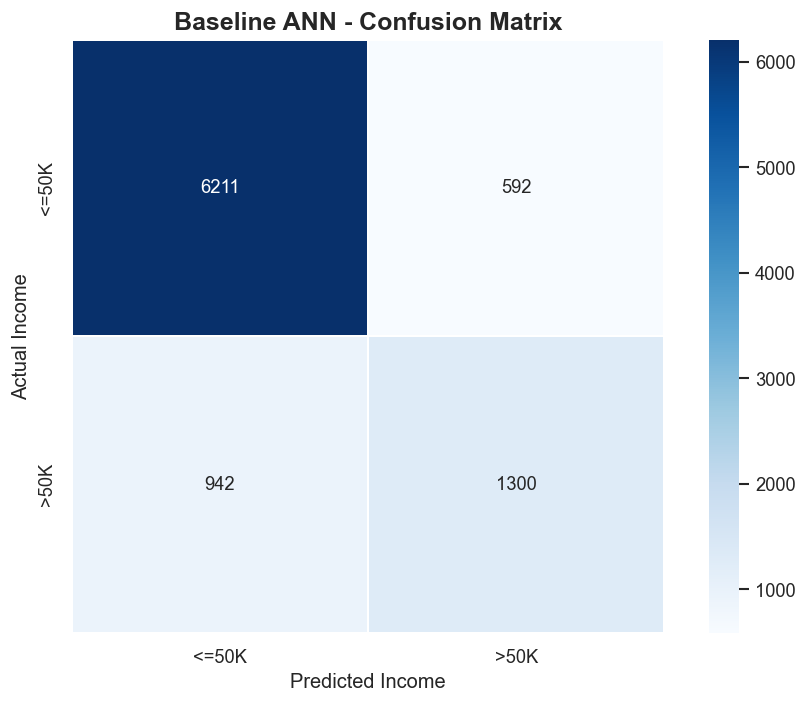


--- DETAILED CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

       <=50K       0.87      0.91      0.89      6803
        >50K       0.69      0.58      0.63      2242

    accuracy                           0.83      9045
   macro avg       0.78      0.75      0.76      9045
weighted avg       0.82      0.83      0.83      9045


TASK 2.7: TRAINING AND VALIDATION PERFORMANCE


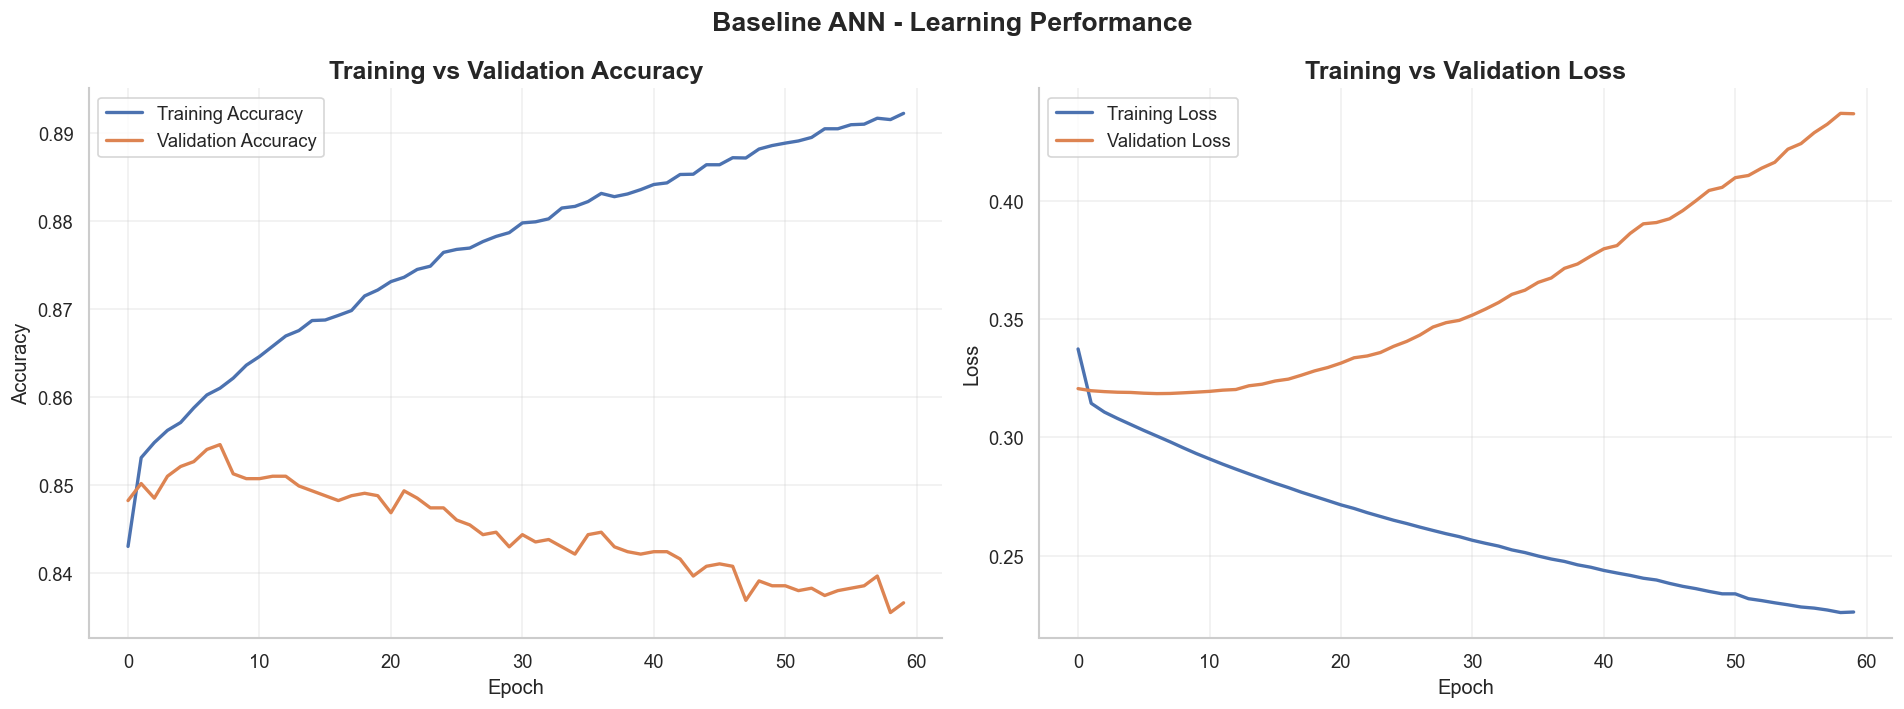


TASK 2.8: MAJORITY CLASS BASELINE COMPARISON

--- MAJORITY CLASS VS ANN BASELINE ---


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Majority Class Baseline,0.7521,0.0000,0.0000,0.0000,0.5000
1,ANN Baseline,0.8304,0.6871,0.5798,0.6289,0.8789



TASK 2.9: STRATIFIED TRAINING AND VALIDATION DATASET

Dataset Dimensions
--------------------------------------------------
Original Training Samples : 36,177
Actual Training Samples   : 32,559
Validation Samples        : 3,618
Testing Samples           : 9,045
Input Features            : 80

Income Class Distribution


,Training,Validation,Testing
Income Class,,,
<=50K,75.22%,75.21%,75.21%
>50K,24.78%,24.79%,24.79%



Stratified dataset creation completed successfully.

TASK 2.10: EARLY STOPPING EXPERIMENT

Early Stopping Model Architecture


Model: "sequential"

... (5 outputs left out)

,Evaluation Metric,Score
0,Test Loss,0.3175
1,Accuracy,0.8505
2,Precision,0.7636
3,Recall,0.5749
4,F1-Score,0.6560
5,ROC-AUC,0.9101



TASK 2.10.2: BASELINE VS EARLY STOPPING COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Baseline ANN,0.8304,0.6871,0.5798,0.6289,0.8789
1,Early Stopping ANN,0.8505,0.7636,0.5749,0.6560,0.9101



TASK 2.11: EARLY STOPPING PERFORMANCE VISUALIZATION


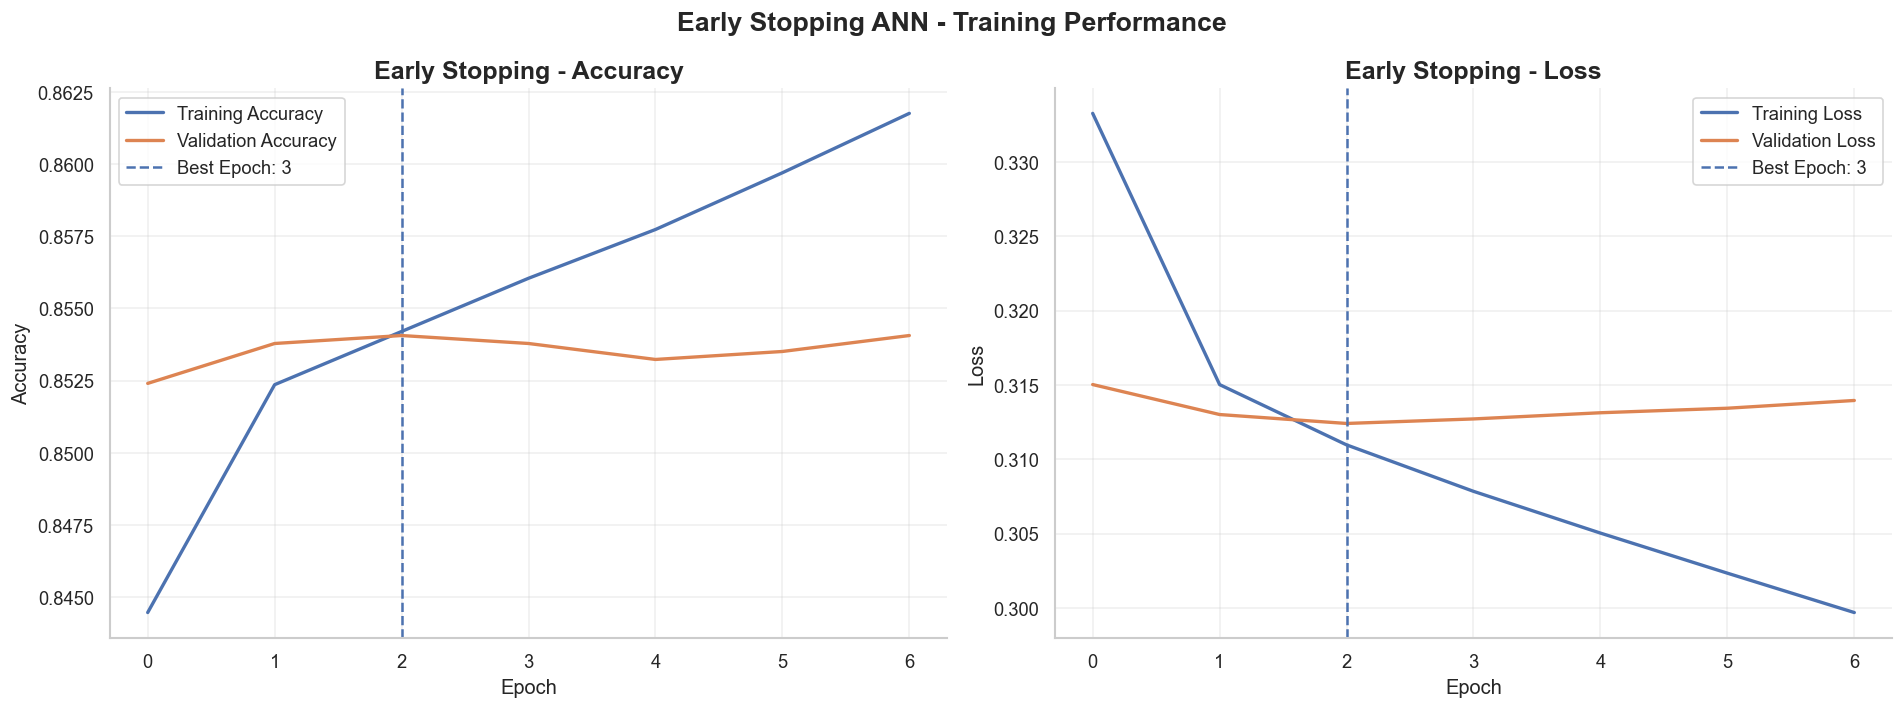


TASK 2.12: SAVE FINAL TASK 2 RESULTS
Validation dataset saved successfully.

Saved Files:
- baseline_ann_model.keras
- early_stopping_ann_model.keras
- baseline_vs_early_stopping.csv
- early_stopping_metrics.csv
- validation_split_indices.csv
- 08_early_stopping_analysis.png

TASK 2: ALL EXPERIMENTS COMPLETED

TASK 2: BASELINE ANN COMPLETION REPORT

Model Architecture:
Input Layer       : 80 Features
Hidden Layer 1    : 128 Neurons - ReLU
Hidden Layer 2    : 64 Neurons - ReLU
Output Layer      : 1 Neuron - Sigmoid

Training Configuration:
Optimizer         : Adam
Loss Function     : Binary Crossentropy
Epochs            : 60
Batch Size        : 64
Learning Rate     : 0.001

Final Test Performance:
Accuracy          : 0.8304
Precision         : 0.6871
Recall            : 0.5798
F1-Score          : 0.6289
ROC-AUC           : 0.8789

Baseline Model Saved Successfully.

Generated Visualizations:
 - 06_baseline_confusion_matrix.png
 - 07_baseline_training_performance.png

TASK 2: COMPLETED

In [5]:
# =============================================================================
# TASK 2: MLP ARCHITECTURE - BASELINE ANN
# PROJECT: ADULT INCOME PREDICTION USING ANN
# =============================================================================


# =============================================================================
# TASK 2.1: DATASET AND MODEL CONFIGURATION
# =============================================================================

print("\n" + "=" * 85)
print("TASK 2.1: DATASET AND MODEL CONFIGURATION")
print("=" * 85)

# Verify Task 1 preprocessing results
assert X_train.ndim == 2, "Training data must be two-dimensional."
assert X_test.ndim == 2, "Testing data must be two-dimensional."
assert X_train.shape[1] == X_test.shape[1], "Feature dimensions do not match."
assert len(X_train) == len(y_train), "Training features and labels mismatch."
assert len(X_test) == len(y_test), "Testing features and labels mismatch."
assert np.isfinite(X_train).all(), "Training data contains invalid values."
assert np.isfinite(X_test).all(), "Testing data contains invalid values."

INPUT_DIM = X_train.shape[1]

HIDDEN_UNITS = [128, 64]
HIDDEN_ACTIVATION = "relu"
OUTPUT_ACTIVATION = "sigmoid"

EPOCHS = 60
BATCH_SIZE = 64
VALIDATION_SPLIT = 0.10
LEARNING_RATE = 0.001

print(f"\nTraining Samples       : {X_train.shape[0]:,}")
print(f"Testing Samples        : {X_test.shape[0]:,}")
print(f"Input Features         : {INPUT_DIM}")
print(f"Hidden Layer Structure : {HIDDEN_UNITS}")
print(f"Epochs                 : {EPOCHS}")
print(f"Batch Size             : {BATCH_SIZE}")
print(f"Validation Split       : {VALIDATION_SPLIT}")
print(f"Learning Rate          : {LEARNING_RATE}")

print("\nDataset verification completed successfully.")


# =============================================================================
# TASK 2.2: BUILD REUSABLE ANN MODEL FUNCTION
# =============================================================================

print("\n" + "=" * 85)
print("TASK 2.2: BUILD REUSABLE ANN MODEL FUNCTION")
print("=" * 85)


def build_ann(
    input_dim,
    hidden_units=(128, 64),
    activation="relu",
    initializer="glorot_uniform",
    use_batch_norm=False,
    batch_norm_position="before_activation",
    optimizer=None,
    loss="binary_crossentropy"
):

    """
    Build a configurable Multi-Layer Perceptron for binary classification.

    Parameters:
        input_dim             : Number of input features.
        hidden_units          : Number of neurons in hidden layers.
        activation            : Hidden layer activation function.
        initializer           : Weight initialization technique.
        use_batch_norm        : Whether to use Batch Normalization.
        batch_norm_position   : Batch Normalization placement.
        optimizer             : Keras optimizer.
        loss                  : Loss function.

    Returns:
        Compiled Keras Sequential model.
    """

    model = Sequential()

    model.add(Input(shape=(input_dim,)))

    for units in hidden_units:

        model.add(
            Dense(
                units,
                kernel_initializer=initializer,
                use_bias=not use_batch_norm
            )
        )

        if use_batch_norm and batch_norm_position == "before_activation":
            model.add(BatchNormalization())

        model.add(Activation(activation))

        if use_batch_norm and batch_norm_position == "after_activation":
            model.add(BatchNormalization())

    model.add(
        Dense(
            1,
            activation=OUTPUT_ACTIVATION,
            kernel_initializer="glorot_uniform"
        )
    )

    if optimizer is None:
        optimizer = Adam(learning_rate=LEARNING_RATE)

    model.compile(
        optimizer=optimizer,
        loss=loss,
        metrics=[
            "accuracy",
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall")
        ]
    )

    return model


print("Reusable ANN architecture function created successfully.")


# =============================================================================
# TASK 2.3: BUILD BASELINE ANN MODEL
# =============================================================================

print("\n" + "=" * 85)
print("TASK 2.3: BUILD BASELINE ANN MODEL")
print("=" * 85)

# Set reproducible random seed
tf.random.set_seed(SEED)

# Create baseline model
baseline_model = build_ann(
    input_dim=INPUT_DIM,
    hidden_units=HIDDEN_UNITS,
    activation="relu",
    initializer="glorot_uniform",
    use_batch_norm=False,
    optimizer=Adam(learning_rate=LEARNING_RATE),
    loss="binary_crossentropy"
)

print("\n--- BASELINE ANN MODEL SUMMARY ---")

baseline_model.summary()

# Calculate total trainable parameters
total_parameters = baseline_model.count_params()

print(f"\nTotal Model Parameters: {total_parameters:,}")


# =============================================================================
# TASK 2.4: TRAIN BASELINE ANN MODEL
# =============================================================================

print("\n" + "=" * 85)
print("TASK 2.4: TRAIN BASELINE ANN MODEL")
print("=" * 85)

# Train the baseline ANN
baseline_history = baseline_model.fit(
    X_train,
    y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=VALIDATION_SPLIT,
    shuffle=True,
    verbose=1
)

print("\nBaseline ANN training completed successfully.")

print(f"Total Epochs Trained: {len(baseline_history.history['loss'])}")


# =============================================================================
# TASK 2.5: EVALUATE BASELINE ANN MODEL
# =============================================================================

print("\n" + "=" * 85)
print("TASK 2.5: EVALUATE BASELINE ANN MODEL")
print("=" * 85)

# Evaluate the model on unseen testing data
test_results = baseline_model.evaluate(
    X_test,
    y_test,
    verbose=0,
    return_dict=True
)

print("\n--- TESTING LOSS AND KERAS METRICS ---")

for metric, value in test_results.items():
    print(f"{metric.upper():20s}: {value:.4f}")


# Generate predicted probabilities
y_probability = baseline_model.predict(
    X_test,
    verbose=0
).ravel()

# Convert probabilities into binary predictions
CLASSIFICATION_THRESHOLD = 0.50

y_prediction = (
    y_probability >= CLASSIFICATION_THRESHOLD
).astype(int)

# Calculate evaluation metrics
baseline_accuracy = accuracy_score(y_test, y_prediction)

baseline_precision = precision_score(
    y_test,
    y_prediction,
    zero_division=0
)

baseline_recall = recall_score(
    y_test,
    y_prediction,
    zero_division=0
)

baseline_f1 = f1_score(
    y_test,
    y_prediction,
    zero_division=0
)

baseline_roc_auc = roc_auc_score(
    y_test,
    y_probability
)

# Display evaluation results
baseline_results = pd.DataFrame({
    "Evaluation Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],
    "Score": [
        baseline_accuracy,
        baseline_precision,
        baseline_recall,
        baseline_f1,
        baseline_roc_auc
    ]
})

print("\n--- BASELINE ANN PERFORMANCE ---")
display(baseline_results.style.format({"Score": "{:.4f}"}))


# =============================================================================
# TASK 2.6: CONFUSION MATRIX AND CLASSIFICATION REPORT
# =============================================================================

print("\n" + "=" * 85)
print("TASK 2.6: CONFUSION MATRIX AND CLASSIFICATION REPORT")
print("=" * 85)

# Generate confusion matrix
baseline_cm = confusion_matrix(
    y_test,
    y_prediction,
    labels=[0, 1]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    baseline_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=1,
    square=True,
    xticklabels=["<=50K", ">50K"],
    yticklabels=["<=50K", ">50K"]
)

plt.title(
    "Baseline ANN - Confusion Matrix",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Predicted Income")
plt.ylabel("Actual Income")

plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "06_baseline_confusion_matrix.png",
    bbox_inches="tight"
)

plt.show()


# Classification report
print("\n--- DETAILED CLASSIFICATION REPORT ---")

print(
    classification_report(
        y_test,
        y_prediction,
        labels=[0, 1],
        target_names=["<=50K", ">50K"],
        zero_division=0
    )
)


# =============================================================================
# TASK 2.7: TRAINING AND VALIDATION PERFORMANCE VISUALIZATION
# =============================================================================

print("\n" + "=" * 85)
print("TASK 2.7: TRAINING AND VALIDATION PERFORMANCE")
print("=" * 85)

history = baseline_history.history

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Accuracy graph
axes[0].plot(
    history["accuracy"],
    label="Training Accuracy",
    linewidth=2
)

axes[0].plot(
    history["val_accuracy"],
    label="Validation Accuracy",
    linewidth=2
)

axes[0].set_title(
    "Training vs Validation Accuracy",
    fontweight="bold"
)

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")

axes[0].legend()
axes[0].grid(alpha=0.3)


# Loss graph
axes[1].plot(
    history["loss"],
    label="Training Loss",
    linewidth=2
)

axes[1].plot(
    history["val_loss"],
    label="Validation Loss",
    linewidth=2
)

axes[1].set_title(
    "Training vs Validation Loss",
    fontweight="bold"
)

axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")

axes[1].legend()
axes[1].grid(alpha=0.3)

fig.suptitle(
    "Baseline ANN - Learning Performance",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "07_baseline_training_performance.png",
    bbox_inches="tight"
)

plt.show()


# =============================================================================
# TASK 2.8: MAJORITY CLASS BASELINE COMPARISON
# =============================================================================

print("\n" + "=" * 85)
print("TASK 2.8: MAJORITY CLASS BASELINE COMPARISON")
print("=" * 85)

# Predict the majority class for every test sample
majority_class = int(
    pd.Series(y_train).mode().iloc[0]
)

majority_predictions = np.full(
    shape=len(y_test),
    fill_value=majority_class
)

majority_accuracy = accuracy_score(
    y_test,
    majority_predictions
)

majority_f1 = f1_score(
    y_test,
    majority_predictions,
    zero_division=0
)

comparison_results = pd.DataFrame({
    "Model": [
        "Majority Class Baseline",
        "ANN Baseline"
    ],
    "Accuracy": [
        majority_accuracy,
        baseline_accuracy
    ],
    "Precision": [
        precision_score(y_test, majority_predictions, zero_division=0),
        baseline_precision
    ],
    "Recall": [
        recall_score(y_test, majority_predictions, zero_division=0),
        baseline_recall
    ],
    "F1-Score": [
        majority_f1,
        baseline_f1
    ],
    "ROC-AUC": [
        0.50,
        baseline_roc_auc
    ]
})

print("\n--- MAJORITY CLASS VS ANN BASELINE ---")

display(
    comparison_results.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)

# =============================================================================
# TASK 2.9: STRATIFIED TRAINING AND VALIDATION DATASET
# =============================================================================

print("\n" + "=" * 85)
print("TASK 2.9: STRATIFIED TRAINING AND VALIDATION DATASET")
print("=" * 85)

# Create a fixed stratified validation dataset
X_train_exp, X_val_exp, y_train_exp, y_val_exp = train_test_split(
    X_train,
    y_train,
    test_size=0.10,
    random_state=SEED,
    stratify=y_train
)

# Verify dimensions
assert X_train_exp.shape[1] == X_val_exp.shape[1]
assert len(X_train_exp) == len(y_train_exp)
assert len(X_val_exp) == len(y_val_exp)

print("\nDataset Dimensions")
print("-" * 50)

print(f"Original Training Samples : {len(X_train):,}")
print(f"Actual Training Samples   : {len(X_train_exp):,}")
print(f"Validation Samples        : {len(X_val_exp):,}")
print(f"Testing Samples           : {len(X_test):,}")
print(f"Input Features            : {X_train_exp.shape[1]}")

# Compare class proportions
distribution = pd.DataFrame({
    "Training": pd.Series(y_train_exp).value_counts(normalize=True),
    "Validation": pd.Series(y_val_exp).value_counts(normalize=True),
    "Testing": pd.Series(y_test).value_counts(normalize=True)
}).fillna(0)

distribution.index = ["<=50K", ">50K"]
distribution.index.name = "Income Class"

print("\nIncome Class Distribution")
display(distribution.style.format("{:.2%}"))

# Verify that all datasets contain both classes
assert len(np.unique(y_train_exp)) == 2
assert len(np.unique(y_val_exp)) == 2
assert len(np.unique(y_test)) == 2

print("\nStratified dataset creation completed successfully.")


# =============================================================================
# TASK 2.10: EARLY STOPPING EXPERIMENT
# =============================================================================

print("\n" + "=" * 85)
print("TASK 2.10: EARLY STOPPING EXPERIMENT")
print("=" * 85)

# Reset random seed for reproducibility
tf.keras.backend.clear_session()
tf.random.set_seed(SEED)

# Build a fresh ANN model
early_stopping_model = build_ann(
    input_dim=INPUT_DIM,
    hidden_units=HIDDEN_UNITS,
    activation="relu",
    initializer="glorot_uniform",
    use_batch_norm=False,
    optimizer=Adam(learning_rate=LEARNING_RATE),
    loss="binary_crossentropy"
)

print("\nEarly Stopping Model Architecture")
early_stopping_model.summary()

# Configure Early Stopping
early_stopping_callback = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    min_delta=0.001,
    restore_best_weights=True,
    verbose=1
)

# Train the model
early_stopping_history = early_stopping_model.fit(
    X_train_exp,
    y_train_exp,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val_exp, y_val_exp),
    shuffle=True,
    callbacks=[early_stopping_callback],
    verbose=1
)

# Determine the best epoch
early_history = early_stopping_history.history

early_best_epoch = int(
    np.argmin(early_history["val_loss"]) + 1
)

print("\nEarly Stopping Training Summary")
print("-" * 50)

print(f"Maximum Epochs       : {EPOCHS}")
print(f"Actual Epochs Trained: {len(early_history['loss'])}")
print(f"Best Validation Epoch: {early_best_epoch}")
print(f"Minimum Validation Loss: {min(early_history['val_loss']):.4f}")


# =============================================================================
# TASK 2.10.1: EVALUATE EARLY STOPPING MODEL
# =============================================================================

print("\n" + "=" * 85)
print("TASK 2.10.1: EVALUATE EARLY STOPPING MODEL")
print("=" * 85)

# Evaluate on independent test data
early_test_results = early_stopping_model.evaluate(
    X_test,
    y_test,
    verbose=0,
    return_dict=True
)

# Generate test probabilities
early_probability = early_stopping_model.predict(
    X_test,
    verbose=0
).ravel()

# Convert probabilities into binary predictions
early_prediction = (
    early_probability >= CLASSIFICATION_THRESHOLD
).astype(int)

# Calculate evaluation metrics
early_accuracy = accuracy_score(
    y_test,
    early_prediction
)

early_precision = precision_score(
    y_test,
    early_prediction,
    zero_division=0
)

early_recall = recall_score(
    y_test,
    early_prediction,
    zero_division=0
)

early_f1 = f1_score(
    y_test,
    early_prediction,
    zero_division=0
)

early_roc_auc = roc_auc_score(
    y_test,
    early_probability
)

early_results = pd.DataFrame({
    "Evaluation Metric": [
        "Test Loss",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],
    "Score": [
        early_test_results["loss"],
        early_accuracy,
        early_precision,
        early_recall,
        early_f1,
        early_roc_auc
    ]
})

print("\nEarly Stopping ANN Test Performance")

display(
    early_results.style.format({
        "Score": "{:.4f}"
    })
)


# =============================================================================
# TASK 2.10.2: BASELINE VS EARLY STOPPING COMPARISON
# =============================================================================

print("\n" + "=" * 85)
print("TASK 2.10.2: BASELINE VS EARLY STOPPING COMPARISON")
print("=" * 85)

early_comparison = pd.DataFrame({
    "Model": [
        "Baseline ANN",
        "Early Stopping ANN"
    ],
    "Accuracy": [
        baseline_accuracy,
        early_accuracy
    ],
    "Precision": [
        baseline_precision,
        early_precision
    ],
    "Recall": [
        baseline_recall,
        early_recall
    ],
    "F1-Score": [
        baseline_f1,
        early_f1
    ],
    "ROC-AUC": [
        baseline_roc_auc,
        early_roc_auc
    ]
})

display(
    early_comparison.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)


# =============================================================================
# TASK 2.11: EARLY STOPPING VISUALIZATION
# =============================================================================

print("\n" + "=" * 85)
print("TASK 2.11: EARLY STOPPING PERFORMANCE VISUALIZATION")
print("=" * 85)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Training and validation accuracy
axes[0].plot(
    early_history["accuracy"],
    label="Training Accuracy",
    linewidth=2
)

axes[0].plot(
    early_history["val_accuracy"],
    label="Validation Accuracy",
    linewidth=2
)

axes[0].axvline(
    early_best_epoch - 1,
    linestyle="--",
    label=f"Best Epoch: {early_best_epoch}"
)

axes[0].set_title("Early Stopping - Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Training and validation loss
axes[1].plot(
    early_history["loss"],
    label="Training Loss",
    linewidth=2
)

axes[1].plot(
    early_history["val_loss"],
    label="Validation Loss",
    linewidth=2
)

axes[1].axvline(
    early_best_epoch - 1,
    linestyle="--",
    label=f"Best Epoch: {early_best_epoch}"
)

axes[1].set_title("Early Stopping - Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

fig.suptitle(
    "Early Stopping ANN - Training Performance",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "08_early_stopping_analysis.png",
    bbox_inches="tight"
)

plt.show()


# =============================================================================
# TASK 2.12: SAVE FINAL TASK 2 RESULTS
# =============================================================================

print("\n" + "=" * 85)
print("TASK 2.12: SAVE FINAL TASK 2 RESULTS")
print("=" * 85)

# Save models
baseline_model.save(
    DATA_DIR / "baseline_ann_model.keras"
)

early_stopping_model.save(
    DATA_DIR / "early_stopping_ann_model.keras"
)

# Save comparison results
early_comparison.to_csv(
    DATA_DIR / "baseline_vs_early_stopping.csv",
    index=False
)

early_results.to_csv(
    DATA_DIR / "early_stopping_metrics.csv",
    index=False
)

# Save validation dataset separately for future reference

np.savez_compressed(
    DATA_DIR / "validation_dataset.npz",
    X_train_exp=X_train_exp,
    X_val_exp=X_val_exp,
    y_train_exp=np.asarray(y_train_exp),
    y_val_exp=np.asarray(y_val_exp)
)

print("Validation dataset saved successfully.")

print("\nSaved Files:")
print("- baseline_ann_model.keras")
print("- early_stopping_ann_model.keras")
print("- baseline_vs_early_stopping.csv")
print("- early_stopping_metrics.csv")
print("- validation_split_indices.csv")
print("- 08_early_stopping_analysis.png")

print("\n" + "=" * 85)
print("TASK 2: ALL EXPERIMENTS COMPLETED")
print("=" * 85)

# =============================================================================
# TASK 2: BASELINE MODEL COMPLETION REPORT
# =============================================================================

print("\n" + "=" * 85)
print("TASK 2: BASELINE ANN COMPLETION REPORT")
print("=" * 85)

print("\nModel Architecture:")
print("Input Layer       : 80 Features")
print("Hidden Layer 1    : 128 Neurons - ReLU")
print("Hidden Layer 2    : 64 Neurons - ReLU")
print("Output Layer      : 1 Neuron - Sigmoid")

print("\nTraining Configuration:")
print(f"Optimizer         : Adam")
print(f"Loss Function     : Binary Crossentropy")
print(f"Epochs            : {len(history['loss'])}")
print(f"Batch Size        : {BATCH_SIZE}")
print(f"Learning Rate     : {LEARNING_RATE}")

print("\nFinal Test Performance:")
print(f"Accuracy          : {baseline_accuracy:.4f}")
print(f"Precision         : {baseline_precision:.4f}")
print(f"Recall            : {baseline_recall:.4f}")
print(f"F1-Score          : {baseline_f1:.4f}")
print(f"ROC-AUC           : {baseline_roc_auc:.4f}")

print("\nBaseline Model Saved Successfully.")

baseline_model.save(
    DATA_DIR / "baseline_ann_model.keras"
)

print("\nGenerated Visualizations:")

for plot_name in [
    "06_baseline_confusion_matrix.png",
    "07_baseline_training_performance.png"
]:
    print(f" - {plot_name}")

print("\n" + "=" * 85)
print("TASK 2: COMPLETED SUCCESSFULLY")
print("=" * 85)

# TASK 3: COMPARISON OF ACTIVATION FUNCTIONS

## Objective

To investigate and compare the performance of different activation functions in an Artificial Neural Network for Adult Income Prediction.

The experiment evaluates ReLU, Tanh, Sigmoid and ELU activation functions using an identical Multi-Layer Perceptron architecture and training configuration.

The comparison focuses on training accuracy, validation accuracy, training loss, validation loss, precision, recall, F1-score and ROC-AUC.

Additionally, the experiment examines the percentage of inactive ReLU neurons and the gradient behaviour of the Sigmoid activation function.

The purpose is to identify how activation functions influence learning efficiency, convergence behaviour and classification performance.

TASK 3: ACTIVATION FUNCTION COMPARISON

Experimental Configuration
------------------------------------------------------------
Input Features       : 80
Hidden Layers        : [128, 64]
Epochs               : 50
Batch Size           : 64
Optimizer            : Adam
Learning Rate        : 0.001
Loss Function        : Binary Crossentropy
Output Activation    : Sigmoid
Training Samples     : 32,559
Validation Samples   : 3,618
Activation Functions : ['relu', 'tanh', 'sigmoid', 'elu']

TRAINING RELU ACTIVATION MODEL
Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.8423 - loss: 0.3381 - precision: 0.7240 - recall: 0.5876 - val_accuracy: 0.8543 - val_loss: 0.3140 - val_precision: 0.7598 - val_recall: 0.6031
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.8536 - loss: 0.3154 - precision: 0.7395 - recall: 0.6320 - val_accuracy: 0.8530 - val_loss: 0.3126 - val_precision: 0.7656 - val_recall: 0.5864
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accurac

,Activation,Validation Accuracy,Precision,Recall,F1-Score,ROC-AUC,Best Validation Accuracy,Minimum Validation Loss,Best Accuracy Epoch,Best Loss Epoch
0,ELU,0.8521,0.7631,0.5853,0.6625,0.9059,0.8568,0.3125,21,17
1,SIGMOID,0.8541,0.7860,0.5652,0.6576,0.9144,0.8557,0.3105,14,50
2,TANH,0.8466,0.7408,0.5864,0.6546,0.9045,0.8579,0.3098,8,9
3,RELU,0.8386,0.7239,0.5641,0.6341,0.8862,0.8554,0.3117,4,4



TASK 3.4: ACCURACY COMPARISON


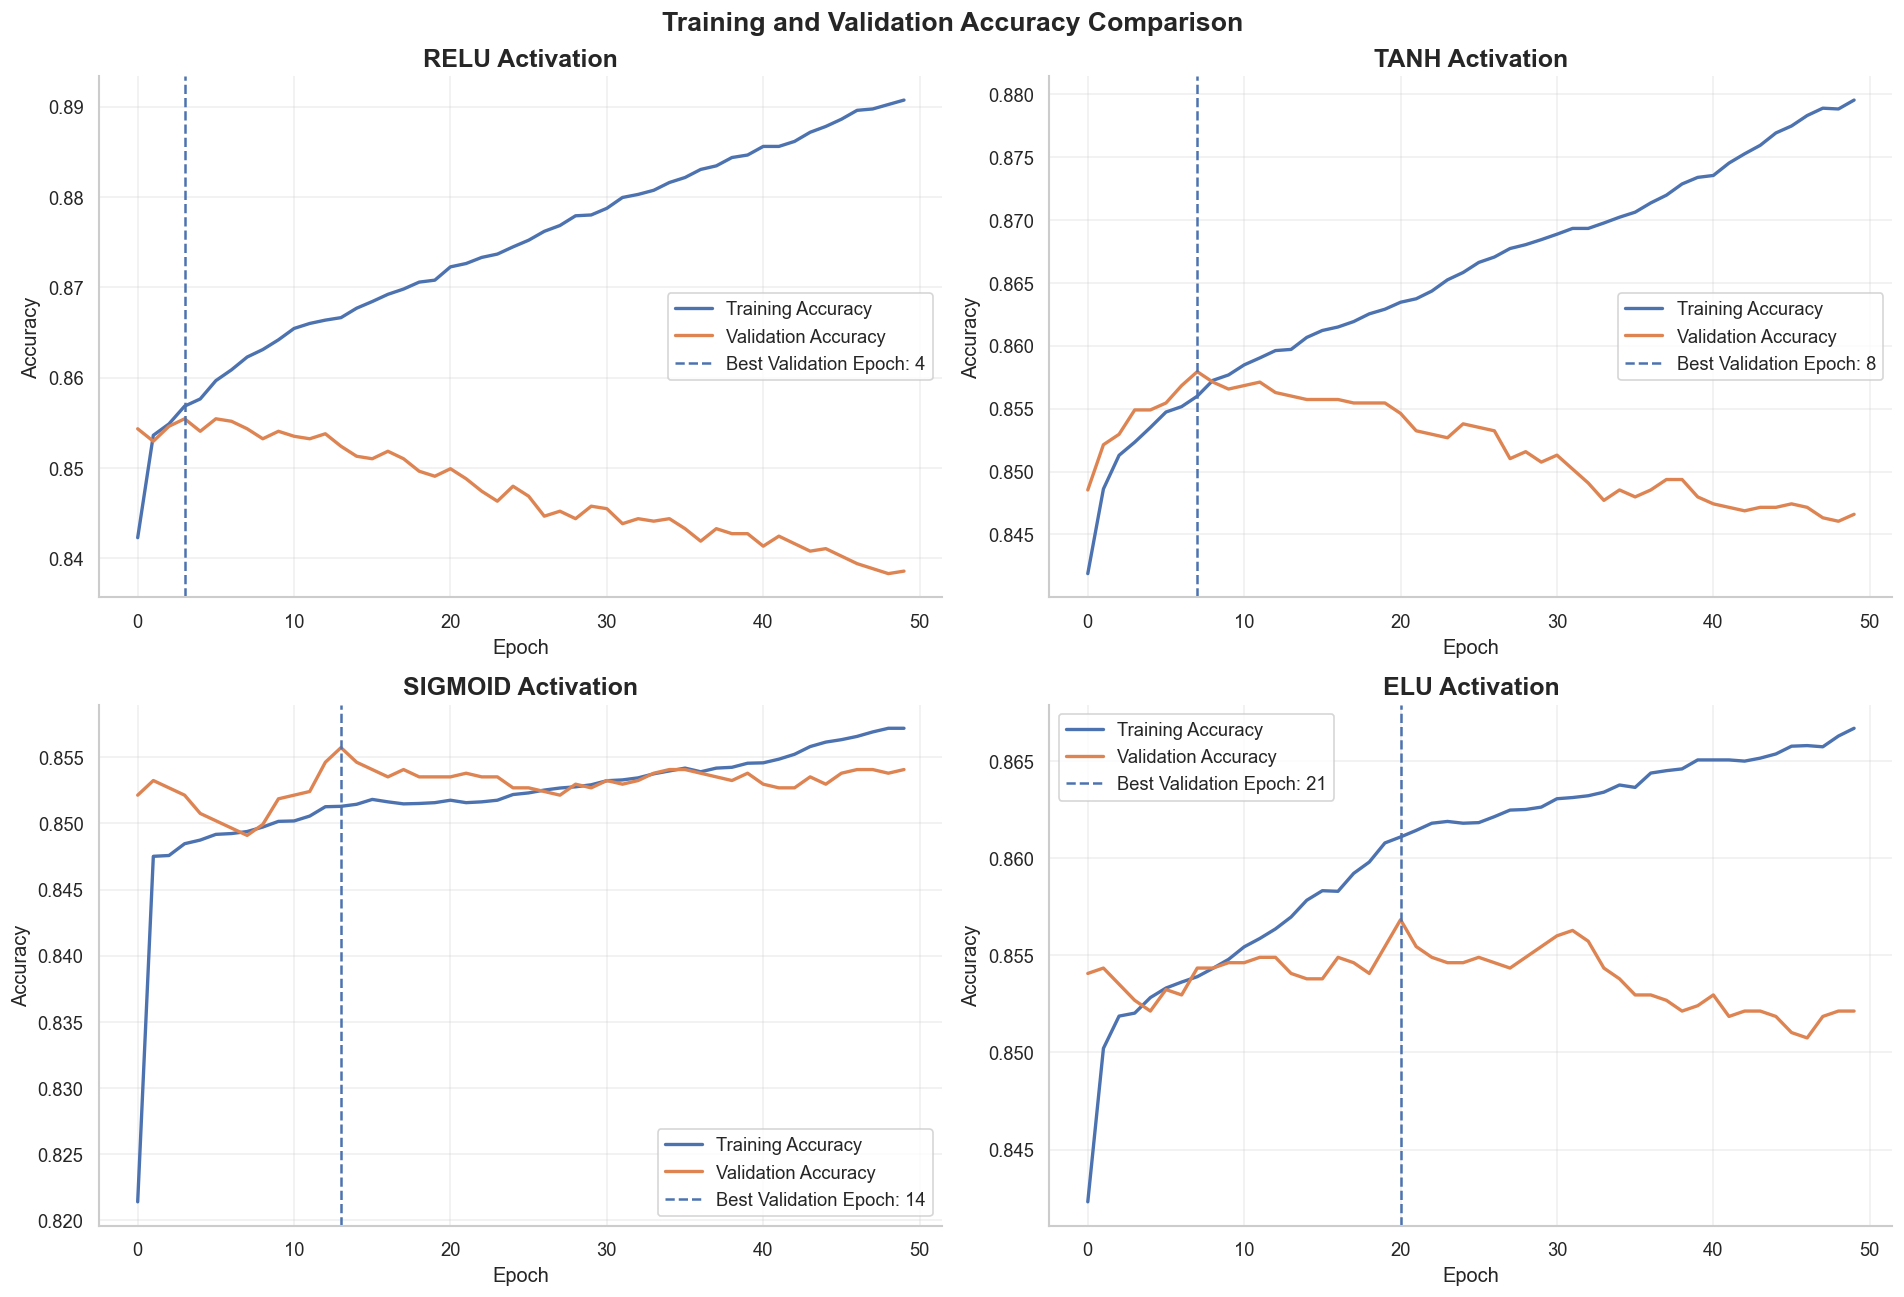


TASK 3.5: LOSS COMPARISON


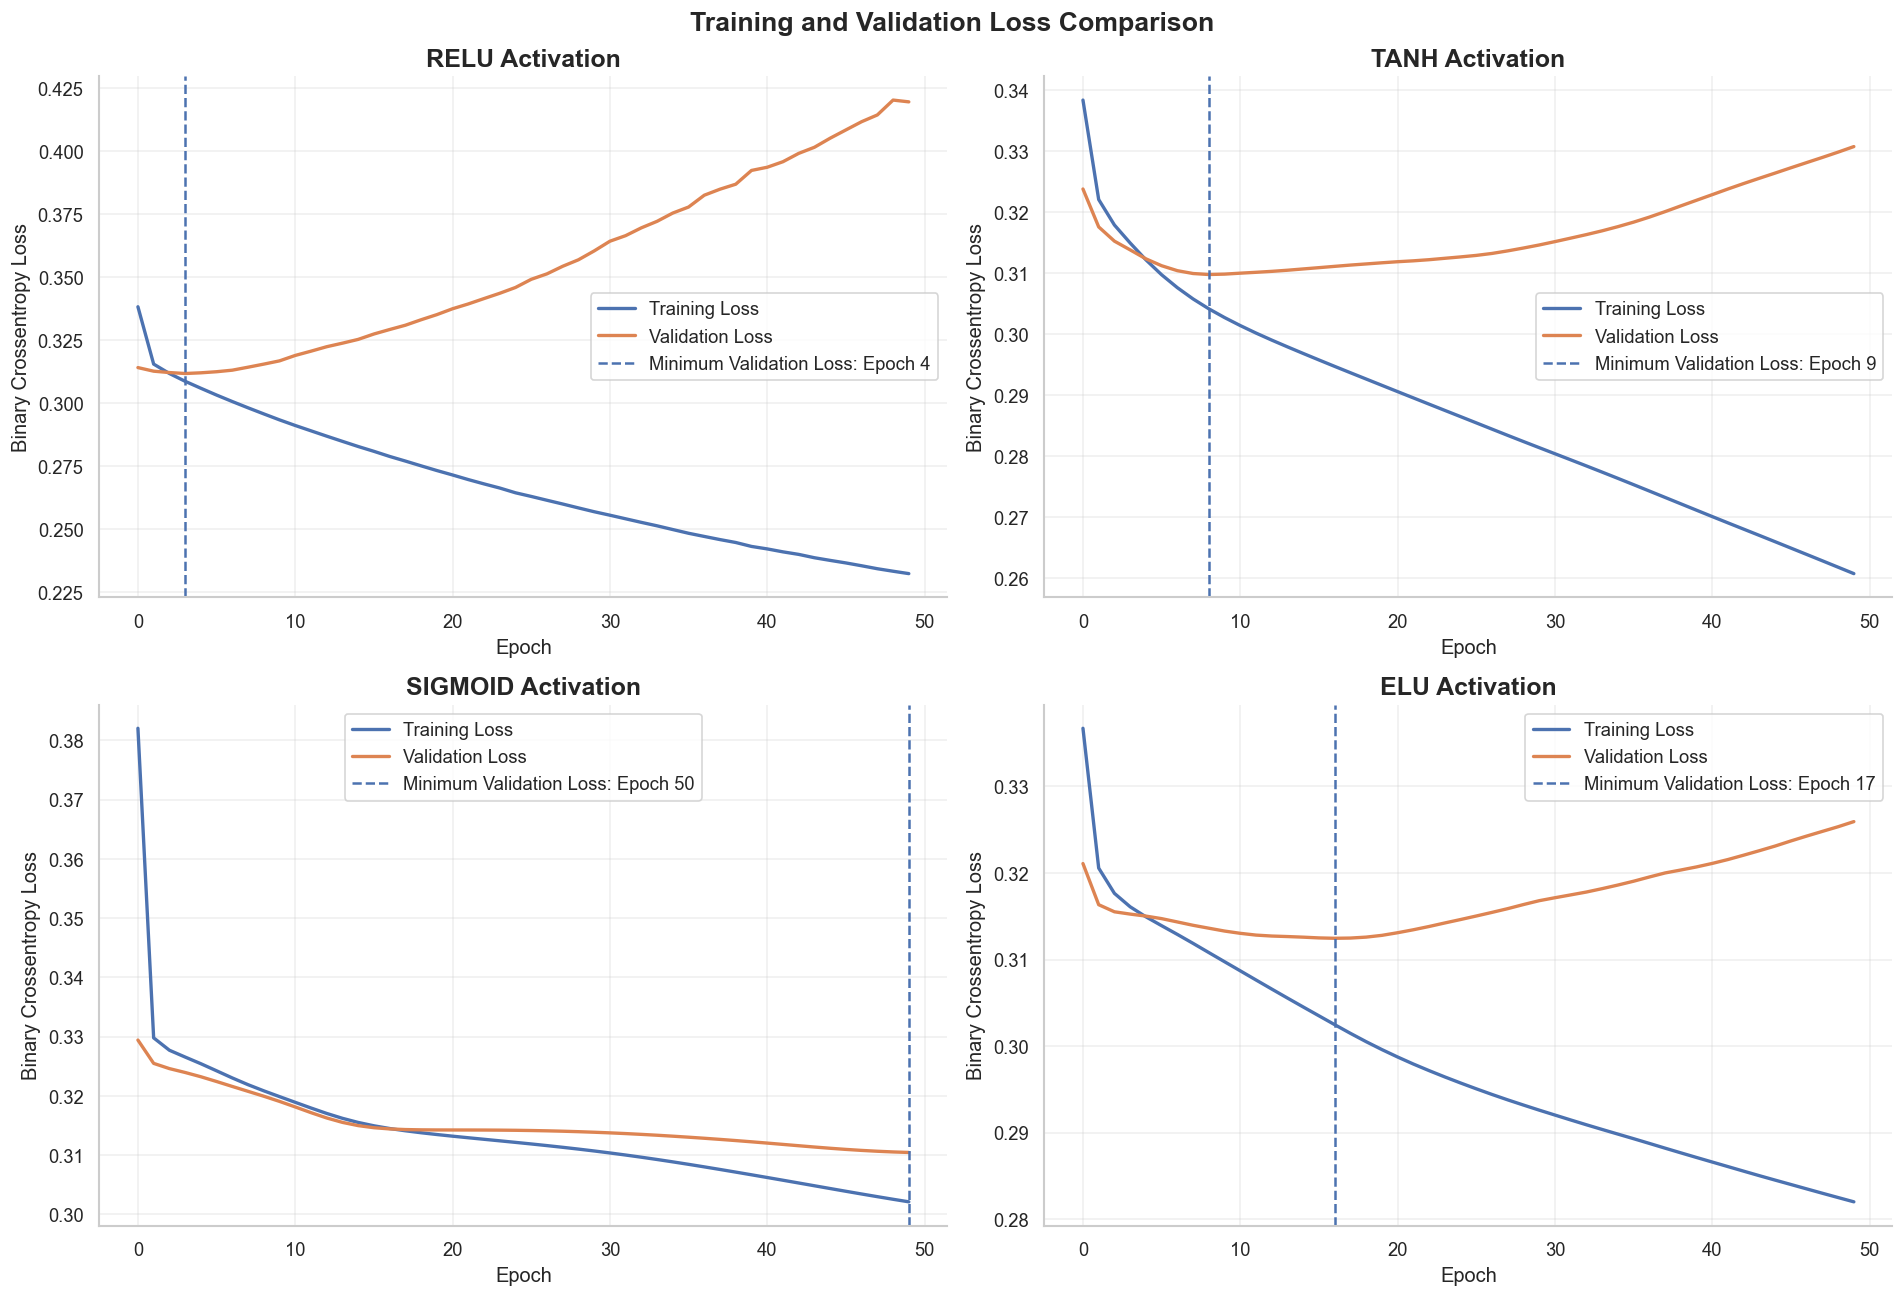


TASK 3.6: ROC CURVE COMPARISON


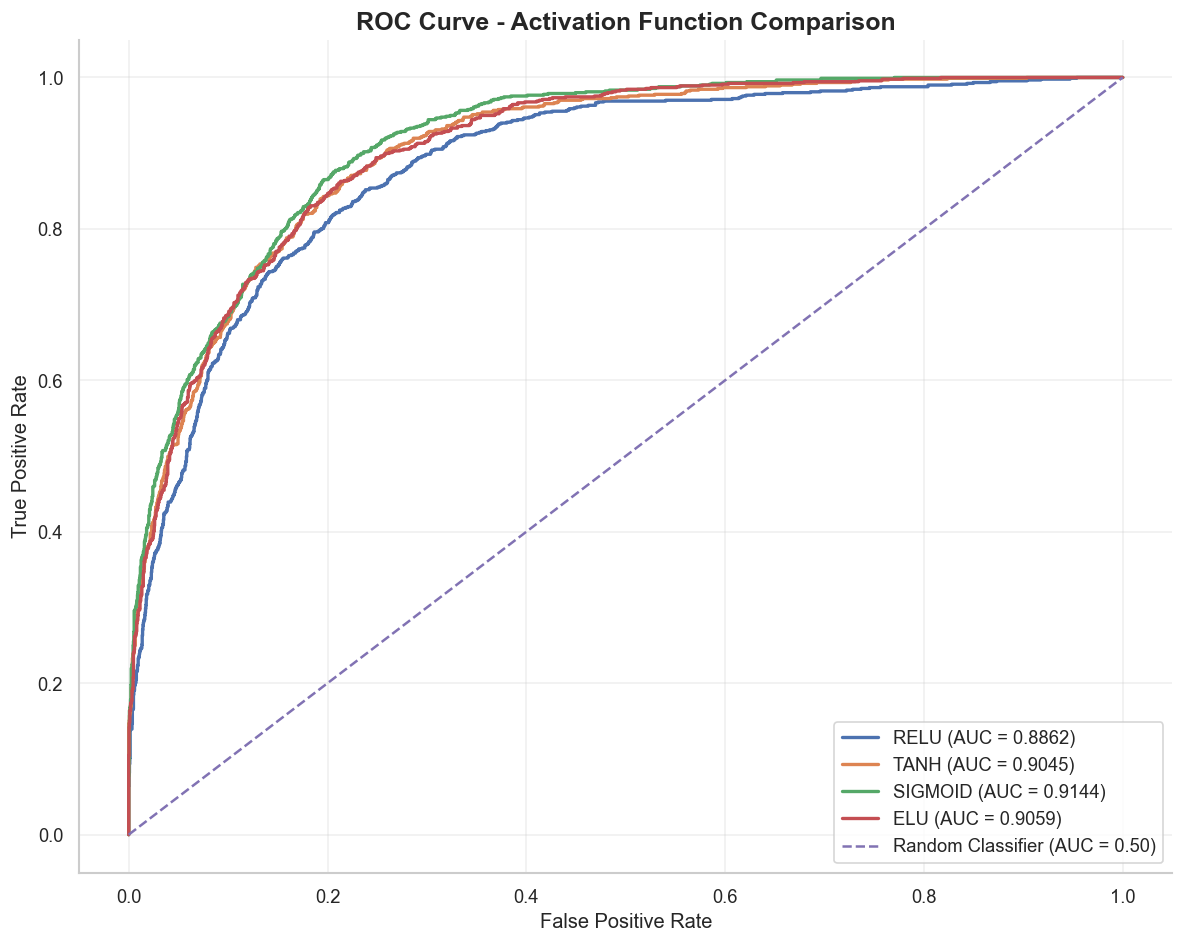


TASK 3.7: DEAD RELU NEURON ANALYSIS

DEAD RELU NEURON ANALYSIS RESULTS


,Hidden Layer,Total Neurons,Dead Neurons,Active Neurons,Dead Neuron Percentage
0,Layer 1,128,0,128,0.00%
1,Layer 2,64,2,62,3.12%



Dead ReLU neuron analysis completed successfully.
Results saved to: C:\Users\urenp\data\task3_dead_relu_analysis.csv

TASK 3.8: GRADIENT-FLOW ANALYSIS

GRADIENT-FLOW COMPARISON


,Activation,Batch Loss,Mean Absolute Gradient,Gradient L2 Norm
0,RELU,0.247591,0.00155604,0.45535135
1,TANH,0.295627,0.00046841,0.11722372
2,SIGMOID,0.316333,0.00011059,0.03174530
3,ELU,0.294949,0.00042871,0.10902557



TASK 3.9: FINAL ACTIVATION FUNCTION COMPARISON

FINAL ACTIVATION FUNCTION RANKING


,Activation,Validation Accuracy,Precision,Recall,F1-Score,ROC-AUC,Best Validation Accuracy,Minimum Validation Loss,Best Accuracy Epoch,Best Loss Epoch
0,ELU,0.8521,0.7631,0.5853,0.6625,0.9059,0.8568,0.3125,21,17
1,SIGMOID,0.8541,0.7860,0.5652,0.6576,0.9144,0.8557,0.3105,14,50
2,TANH,0.8466,0.7408,0.5864,0.6546,0.9045,0.8579,0.3098,8,9
3,RELU,0.8386,0.7239,0.5641,0.6341,0.8862,0.8554,0.3117,4,4



BEST ACTIVATION FUNCTION
------------------------------------------------------------
Selected Activation : ELU
Validation Accuracy : 0.8521
Validation F1-Score : 0.6625
Validation ROC-AUC  : 0.9059
Minimum Val Loss    : 0.3125

GENERATED FILES
------------------------------------------------------------
SUCCESS: task3_activation_comparison.csv
SUCCESS: task3_dead_relu_analysis.csv
SUCCESS: task3_gradient_analysis.csv
SUCCESS: task3_final_activation_ranking.csv
SUCCESS: task3_experiment_configuration.csv
SUCCESS: task3_best_activation_model.keras
SUCCESS: 09_activation_accuracy_comparison.png
SUCCESS: 10_activation_loss_comparison.png
SUCCESS: 11_activation_roc_comparison.png

TASK 3 COMPLETED SUCCESSFULLY


In [8]:
# =============================================================================
# DEEP LEARNING PRACTICAL 02
# TASK 3: COMPARISON OF ACTIVATION FUNCTIONS
# =============================================================================

print("=" * 90)
print("TASK 3: ACTIVATION FUNCTION COMPARISON")
print("=" * 90)

# -----------------------------------------------------------------------------
# TASK 3.1: EXPERIMENTAL CONFIGURATION AND VALIDATION
# -----------------------------------------------------------------------------

required_variables = [
    "X_train_exp", "X_val_exp",
    "y_train_exp", "y_val_exp",
    "build_ann", "INPUT_DIM",
    "HIDDEN_UNITS", "BATCH_SIZE",
    "LEARNING_RATE", "SEED",
    "PLOTS_DIR", "DATA_DIR"
]

missing_variables = [
    variable for variable in required_variables
    if variable not in globals()
]

if missing_variables:
    raise NameError(
        f"Missing variables: {missing_variables}. "
        "Execute Task 1 and Task 2 first."
    )

assert X_train_exp.shape[1] == INPUT_DIM
assert X_val_exp.shape[1] == INPUT_DIM
assert len(X_train_exp) == len(y_train_exp)
assert len(X_val_exp) == len(y_val_exp)
assert np.isfinite(X_train_exp).all()
assert np.isfinite(X_val_exp).all()
assert set(np.unique(y_train_exp)).issubset({0, 1})
assert set(np.unique(y_val_exp)).issubset({0, 1})

ACTIVATION_FUNCTIONS = ["relu", "tanh", "sigmoid", "elu"]

TASK3_EPOCHS = 50
TASK3_BATCH_SIZE = 64
TASK3_LEARNING_RATE = 0.001
TASK3_THRESHOLD = 0.50

print("\nExperimental Configuration")
print("-" * 60)
print(f"Input Features       : {INPUT_DIM}")
print(f"Hidden Layers        : {HIDDEN_UNITS}")
print(f"Epochs               : {TASK3_EPOCHS}")
print(f"Batch Size           : {TASK3_BATCH_SIZE}")
print("Optimizer            : Adam")
print(f"Learning Rate        : {TASK3_LEARNING_RATE}")
print("Loss Function        : Binary Crossentropy")
print("Output Activation    : Sigmoid")
print(f"Training Samples     : {len(X_train_exp):,}")
print(f"Validation Samples   : {len(X_val_exp):,}")
print(f"Activation Functions : {ACTIVATION_FUNCTIONS}")

# -----------------------------------------------------------------------------
# TASK 3.2: TRAIN FOUR ANN MODELS
# -----------------------------------------------------------------------------

activation_models = {}
activation_histories = {}

for activation in ACTIVATION_FUNCTIONS:

    print("\n" + "=" * 75)
    print(f"TRAINING {activation.upper()} ACTIVATION MODEL")
    print("=" * 75)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    model = build_ann(
        input_dim=INPUT_DIM,
        hidden_units=HIDDEN_UNITS,
        activation=activation,
        initializer="glorot_uniform",
        use_batch_norm=False,
        optimizer=Adam(
            learning_rate=TASK3_LEARNING_RATE
        ),
        loss="binary_crossentropy"
    )

    history = model.fit(
        X_train_exp,
        y_train_exp,
        epochs=TASK3_EPOCHS,
        batch_size=TASK3_BATCH_SIZE,
        validation_data=(X_val_exp, y_val_exp),
        shuffle=True,
        verbose=1
    )

    activation_models[activation] = model
    activation_histories[activation] = history

    print(f"\n{activation.upper()} model training completed.")

print("\nAll four models have been trained successfully.")

# -----------------------------------------------------------------------------
# TASK 3.3: EVALUATE MODEL PERFORMANCE
# -----------------------------------------------------------------------------

print("\n" + "=" * 90)
print("TASK 3.3: VALIDATION PERFORMANCE EVALUATION")
print("=" * 90)

activation_results = []
activation_validation_probabilities = {}

for activation, model in activation_models.items():

    probabilities = model.predict(
        X_val_exp,
        verbose=0
    ).ravel()

    predictions = (
        probabilities >= TASK3_THRESHOLD
    ).astype(int)

    activation_validation_probabilities[activation] = probabilities

    accuracy = accuracy_score(y_val_exp, predictions)
    precision = precision_score(
        y_val_exp, predictions, zero_division=0
    )
    recall = recall_score(
        y_val_exp, predictions, zero_division=0
    )
    f1 = f1_score(
        y_val_exp, predictions, zero_division=0
    )
    auc = roc_auc_score(y_val_exp, probabilities)

    history = activation_histories[activation].history

    activation_results.append({
        "Activation": activation.upper(),
        "Validation Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "ROC-AUC": auc,
        "Best Validation Accuracy": max(history["val_accuracy"]),
        "Minimum Validation Loss": min(history["val_loss"]),
        "Best Accuracy Epoch": int(
            np.argmax(history["val_accuracy"]) + 1
        ),
        "Best Loss Epoch": int(
            np.argmin(history["val_loss"]) + 1
        )
    })

activation_results_df = pd.DataFrame(activation_results)

activation_results_df = activation_results_df.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

print("\nACTIVATION FUNCTION PERFORMANCE TABLE")

display(
    activation_results_df.style.format({
        "Validation Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "Best Validation Accuracy": "{:.4f}",
        "Minimum Validation Loss": "{:.4f}"
    })
)

activation_results_df.to_csv(
    DATA_DIR / "task3_activation_comparison.csv",
    index=False
)

# -----------------------------------------------------------------------------
# TASK 3.4: TRAINING AND VALIDATION ACCURACY
# -----------------------------------------------------------------------------

print("\n" + "=" * 90)
print("TASK 3.4: ACCURACY COMPARISON")
print("=" * 90)

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
axes = axes.flatten()

for index, activation in enumerate(ACTIVATION_FUNCTIONS):

    history = activation_histories[activation].history

    axes[index].plot(
        history["accuracy"],
        label="Training Accuracy",
        linewidth=2
    )

    axes[index].plot(
        history["val_accuracy"],
        label="Validation Accuracy",
        linewidth=2
    )

    best_epoch = int(np.argmax(history["val_accuracy"]))

    axes[index].axvline(
        best_epoch,
        linestyle="--",
        label=f"Best Validation Epoch: {best_epoch + 1}"
    )

    axes[index].set_title(
        f"{activation.upper()} Activation",
        fontweight="bold"
    )

    axes[index].set_xlabel("Epoch")
    axes[index].set_ylabel("Accuracy")
    axes[index].legend()
    axes[index].grid(alpha=0.3)

fig.suptitle(
    "Training and Validation Accuracy Comparison",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig(
    PLOTS_DIR / "09_activation_accuracy_comparison.png",
    bbox_inches="tight"
)
plt.show()

# -----------------------------------------------------------------------------
# TASK 3.5: TRAINING AND VALIDATION LOSS
# -----------------------------------------------------------------------------

print("\n" + "=" * 90)
print("TASK 3.5: LOSS COMPARISON")
print("=" * 90)

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
axes = axes.flatten()

for index, activation in enumerate(ACTIVATION_FUNCTIONS):

    history = activation_histories[activation].history

    axes[index].plot(
        history["loss"],
        label="Training Loss",
        linewidth=2
    )

    axes[index].plot(
        history["val_loss"],
        label="Validation Loss",
        linewidth=2
    )

    best_epoch = int(np.argmin(history["val_loss"]))

    axes[index].axvline(
        best_epoch,
        linestyle="--",
        label=f"Minimum Validation Loss: Epoch {best_epoch + 1}"
    )

    axes[index].set_title(
        f"{activation.upper()} Activation",
        fontweight="bold"
    )

    axes[index].set_xlabel("Epoch")
    axes[index].set_ylabel("Binary Crossentropy Loss")
    axes[index].legend()
    axes[index].grid(alpha=0.3)

fig.suptitle(
    "Training and Validation Loss Comparison",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig(
    PLOTS_DIR / "10_activation_loss_comparison.png",
    bbox_inches="tight"
)
plt.show()

# -----------------------------------------------------------------------------
# TASK 3.6: ROC CURVE COMPARISON
# -----------------------------------------------------------------------------

print("\n" + "=" * 90)
print("TASK 3.6: ROC CURVE COMPARISON")
print("=" * 90)

plt.figure(figsize=(10, 8))

for activation in ACTIVATION_FUNCTIONS:

    probabilities = activation_validation_probabilities[activation]

    fpr, tpr, thresholds = roc_curve(
        y_val_exp,
        probabilities
    )

    auc_value = roc_auc_score(
        y_val_exp,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{activation.upper()} (AUC = {auc_value:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier (AUC = 0.50)"
)

plt.title(
    "ROC Curve - Activation Function Comparison",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "11_activation_roc_comparison.png",
    bbox_inches="tight"
)

plt.show()

# =============================================================================
# TASK 3.7: DEAD RELU NEURON ANALYSIS (KERAS COMPATIBLE FIX)
# =============================================================================

print("\n" + "=" * 90)
print("TASK 3.7: DEAD RELU NEURON ANALYSIS")
print("=" * 90)

relu_model = activation_models["relu"]

# Explicitly build the model using a sample input.
# This ensures that Keras registers the model's input and output tensors.
_ = relu_model(
    tf.convert_to_tensor(
        X_val_exp[:1],
        dtype=tf.float32
    ),
    training=False
)

# Identify all ReLU activation layers.
relu_activation_layers = [
    layer for layer in relu_model.layers
    if isinstance(layer, Activation)
    and layer.activation.__name__ == "relu"
]

assert len(relu_activation_layers) == len(HIDDEN_UNITS), (
    f"Expected {len(HIDDEN_UNITS)} ReLU layers, "
    f"but found {len(relu_activation_layers)}."
)

# Create an intermediate model using the actual input tensor.
relu_intermediate_model = keras.Model(
    inputs=relu_model.inputs,
    outputs=[
        layer.output for layer in relu_activation_layers
    ]
)

# Obtain activations for the complete validation dataset.
relu_layer_activations = relu_intermediate_model.predict(
    X_val_exp,
    batch_size=TASK3_BATCH_SIZE,
    verbose=0
)

dead_relu_results = []

for layer_number, activations in enumerate(
    relu_layer_activations,
    start=1
):

    # A neuron is considered inactive if its output is zero
    # for every validation sample.
    inactive_neurons = np.all(
        np.isclose(activations, 0.0, atol=1e-8),
        axis=0
    )

    total_neurons = activations.shape[1]
    dead_neurons = int(np.sum(inactive_neurons))
    active_neurons = total_neurons - dead_neurons

    dead_percentage = (
        dead_neurons / total_neurons
    ) * 100

    dead_relu_results.append({
        "Hidden Layer": f"Layer {layer_number}",
        "Total Neurons": total_neurons,
        "Dead Neurons": dead_neurons,
        "Active Neurons": active_neurons,
        "Dead Neuron Percentage": dead_percentage
    })

dead_relu_df = pd.DataFrame(dead_relu_results)

print("\nDEAD RELU NEURON ANALYSIS RESULTS")

display(
    dead_relu_df.style.format({
        "Dead Neuron Percentage": "{:.2f}%"
    })
)

# Save analysis results.
dead_relu_df.to_csv(
    DATA_DIR / "task3_dead_relu_analysis.csv",
    index=False
)

print("\nDead ReLU neuron analysis completed successfully.")
print(f"Results saved to: {DATA_DIR / 'task3_dead_relu_analysis.csv'}")


# -----------------------------------------------------------------------------
# TASK 3.8: SIGMOID GRADIENT-FLOW ANALYSIS
# -----------------------------------------------------------------------------

print("\n" + "=" * 90)
print("TASK 3.8: GRADIENT-FLOW ANALYSIS")
print("=" * 90)

gradient_batch_size = min(256, len(X_train_exp))

X_gradient_batch = tf.convert_to_tensor(
    X_train_exp[:gradient_batch_size],
    dtype=tf.float32
)

y_gradient_batch = tf.convert_to_tensor(
    np.asarray(y_train_exp[:gradient_batch_size]).reshape(-1, 1),
    dtype=tf.float32
)

gradient_results = []

for activation in ACTIVATION_FUNCTIONS:

    model = activation_models[activation]

    first_dense_layer = next(
        layer for layer in model.layers
        if isinstance(layer, Dense)
    )

    with tf.GradientTape() as tape:

        predictions = model(
            X_gradient_batch,
            training=False
        )

        batch_loss = tf.reduce_mean(
            keras.losses.binary_crossentropy(
                y_gradient_batch,
                predictions
            )
        )

    gradients = tape.gradient(
        batch_loss,
        first_dense_layer.trainable_variables
    )

    kernel_gradient = gradients[0]

    mean_absolute_gradient = float(
        tf.reduce_mean(
            tf.abs(kernel_gradient)
        ).numpy()
    )

    gradient_norm = float(
        tf.linalg.global_norm([kernel_gradient]).numpy()
    )

    gradient_results.append({
        "Activation": activation.upper(),
        "Batch Loss": float(batch_loss.numpy()),
        "Mean Absolute Gradient": mean_absolute_gradient,
        "Gradient L2 Norm": gradient_norm
    })

gradient_results_df = pd.DataFrame(gradient_results)

print("\nGRADIENT-FLOW COMPARISON")

display(
    gradient_results_df.style.format({
        "Batch Loss": "{:.6f}",
        "Mean Absolute Gradient": "{:.8f}",
        "Gradient L2 Norm": "{:.8f}"
    })
)

gradient_results_df.to_csv(
    DATA_DIR / "task3_gradient_analysis.csv",
    index=False
)

# -----------------------------------------------------------------------------
# TASK 3.9: FINAL COMPARISON AND BEST MODEL SELECTION
# -----------------------------------------------------------------------------

print("\n" + "=" * 90)
print("TASK 3.9: FINAL ACTIVATION FUNCTION COMPARISON")
print("=" * 90)

final_activation_ranking = activation_results_df.sort_values(
    by=["F1-Score", "ROC-AUC", "Validation Accuracy"],
    ascending=False
).reset_index(drop=True)

print("\nFINAL ACTIVATION FUNCTION RANKING")

display(
    final_activation_ranking.style.format({
        "Validation Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "Best Validation Accuracy": "{:.4f}",
        "Minimum Validation Loss": "{:.4f}"
    })
)

best_activation = (
    final_activation_ranking.iloc[0]["Activation"].lower()
)

best_activation_model = activation_models[best_activation]

print("\nBEST ACTIVATION FUNCTION")
print("-" * 60)

print(f"Selected Activation : {best_activation.upper()}")
print(
    f"Validation Accuracy : "
    f"{final_activation_ranking.iloc[0]['Validation Accuracy']:.4f}"
)
print(
    f"Validation F1-Score : "
    f"{final_activation_ranking.iloc[0]['F1-Score']:.4f}"
)
print(
    f"Validation ROC-AUC  : "
    f"{final_activation_ranking.iloc[0]['ROC-AUC']:.4f}"
)
print(
    f"Minimum Val Loss    : "
    f"{final_activation_ranking.iloc[0]['Minimum Validation Loss']:.4f}"
)

# Save best activation model
best_activation_model.save(
    DATA_DIR / "task3_best_activation_model.keras"
)

# Save final results and configuration
final_activation_ranking.to_csv(
    DATA_DIR / "task3_final_activation_ranking.csv",
    index=False
)

pd.DataFrame(
    list({
        "Input Features": INPUT_DIM,
        "Hidden Layers": HIDDEN_UNITS,
        "Epochs": TASK3_EPOCHS,
        "Batch Size": TASK3_BATCH_SIZE,
        "Optimizer": "Adam",
        "Learning Rate": TASK3_LEARNING_RATE,
        "Loss Function": "Binary Crossentropy",
        "Output Activation": "Sigmoid",
        "Classification Threshold": TASK3_THRESHOLD
    }.items()),
    columns=["Parameter", "Value"]
).to_csv(
    DATA_DIR / "task3_experiment_configuration.csv",
    index=False
)

print("\nGENERATED FILES")
print("-" * 60)

generated_files = [
    DATA_DIR / "task3_activation_comparison.csv",
    DATA_DIR / "task3_dead_relu_analysis.csv",
    DATA_DIR / "task3_gradient_analysis.csv",
    DATA_DIR / "task3_final_activation_ranking.csv",
    DATA_DIR / "task3_experiment_configuration.csv",
    DATA_DIR / "task3_best_activation_model.keras",
    PLOTS_DIR / "09_activation_accuracy_comparison.png",
    PLOTS_DIR / "10_activation_loss_comparison.png",
    PLOTS_DIR / "11_activation_roc_comparison.png"
]

for file_path in generated_files:
    print(f"{'SUCCESS' if file_path.exists() else 'MISSING'}: {file_path.name}")

print("\n" + "=" * 90)
print("TASK 3 COMPLETED SUCCESSFULLY")
print("=" * 90)

# TASK 4: COMPARISON OF WEIGHT INITIALIZERS

## Objective

To investigate the effect of different weight initialization techniques on the performance and convergence of an Artificial Neural Network.

The following initialization techniques will be compared:

1. Glorot Uniform
2. Glorot Normal
3. He Uniform
4. He Normal
5. Zero Initialization

The experiment will use the best-performing activation function identified in Task 3 while keeping the ANN architecture, optimizer, learning rate, batch size, loss function and datasets consistent.

## Evaluation Criteria

- Training and validation accuracy.
- Training and validation loss.
- Precision, recall and F1-score.
- ROC-AUC.
- Epochs required to reach the 82% validation accuracy reference.
- Initial and trained weight distributions.
- Effect of zero initialization on hidden-neuron symmetry.

The best weight initializer will be selected primarily using validation F1-score, with ROC-AUC and validation accuracy considered as additional performance measures.

TASK 4: COMPARISON OF WEIGHT INITIALIZERS

EXPERIMENTAL CONFIGURATION
-----------------------------------------------------------------
Input Features        : 80
Hidden Layers         : [128, 64]
Activation Function  : ELU
Epochs                : 50
Batch Size            : 64
Optimizer             : Adam
Learning Rate         : 0.001
Loss Function         : Binary Crossentropy
Output Activation     : Sigmoid
Output Initializer    : Glorot Uniform
Reference Accuracy    : 82%
Training Samples      : 32,559
Validation Samples    : 3,618

Initializers to compare:
- Glorot Uniform: glorot_uniform
- Glorot Normal: glorot_normal
- He Uniform: he_uniform
- He Normal: he_normal
- Zero Initialization: zeros

TRAINING MODEL: GLOROT UNIFORM
Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.8423 - loss: 0.3367 - precision: 0.7237 - recall: 0.5884 - val_accuracy: 0.8541 - val_loss: 0.3211 - val_precision: 0.7610 - val_recall: 0.5998
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/ste

,Initializer,Validation Accuracy,Precision,Recall,F1-Score,ROC-AUC,Best Validation Accuracy,Minimum Validation Loss,Best Accuracy Epoch,Best Loss Epoch,Epochs to Reach 82%
0,He Uniform,0.8513,0.7568,0.5897,0.6629,0.9060,0.8566,0.3126,19,10,1.000000
1,Glorot Uniform,0.8521,0.7631,0.5853,0.6625,0.9059,0.8568,0.3125,21,17,1.000000
2,He Normal,0.8502,0.7622,0.5753,0.6557,0.9056,0.8549,0.3126,13,12,1.000000
3,Glorot Normal,0.8466,0.7457,0.5786,0.6516,0.9066,0.8552,0.3126,15,17,1.000000
4,Zero Initialization,0.7521,0.0000,0.0000,0.0000,0.5000,0.7521,0.5608,1,50,nan



TASK 4.5: ACCURACY COMPARISON


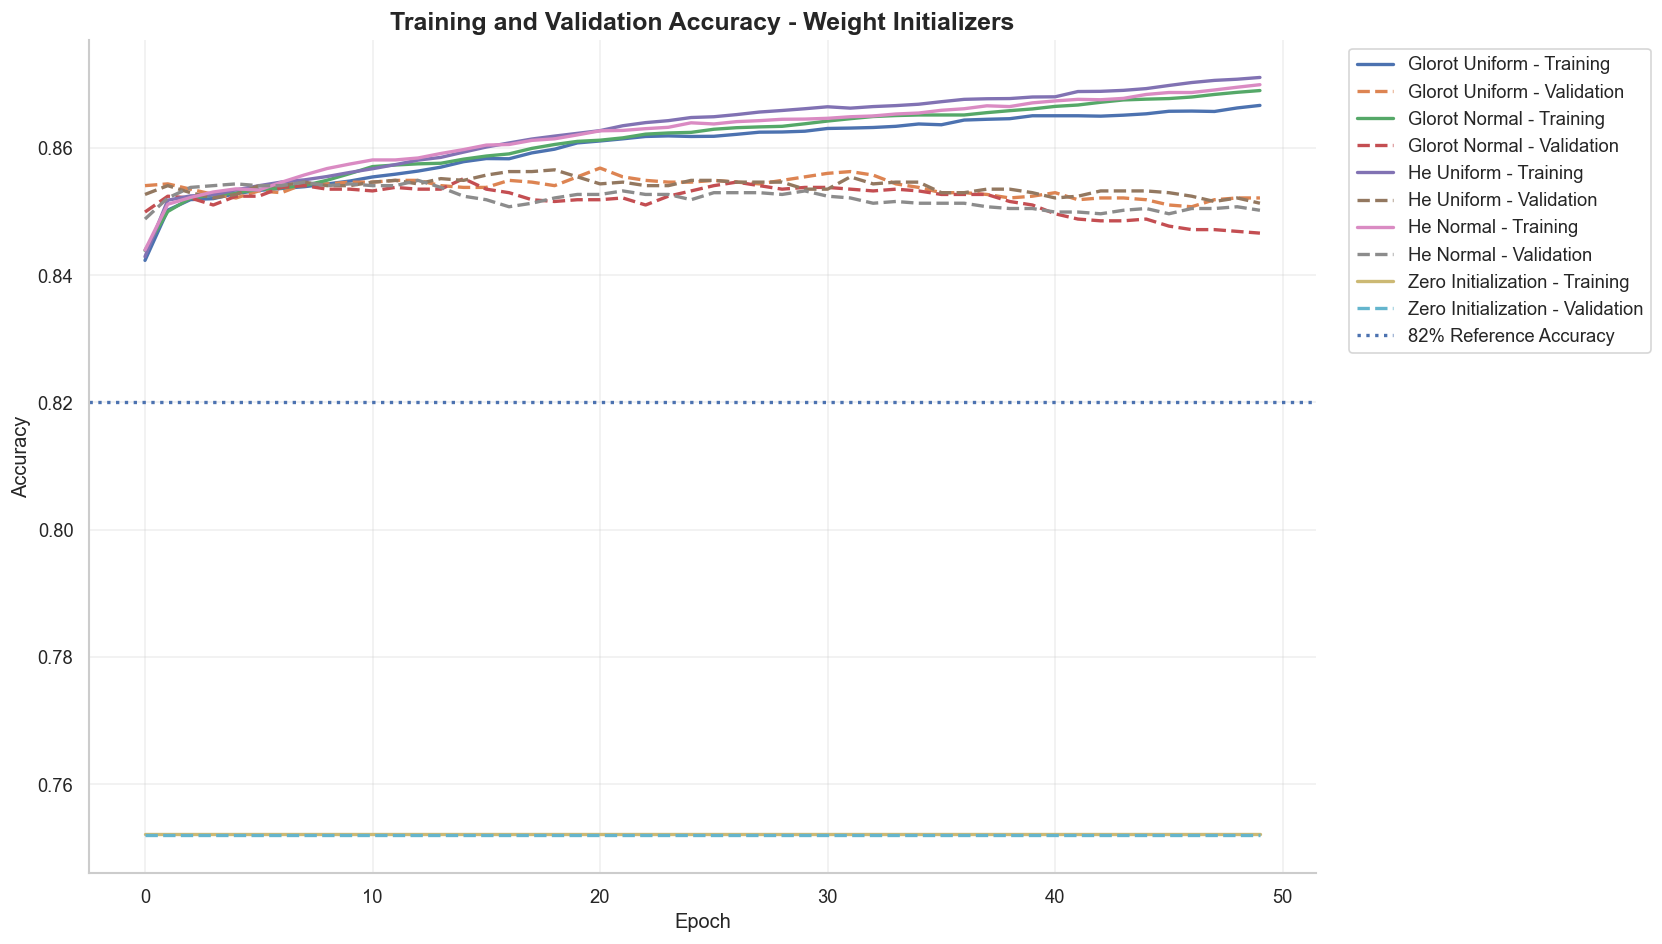


TASK 4.6: LOSS COMPARISON


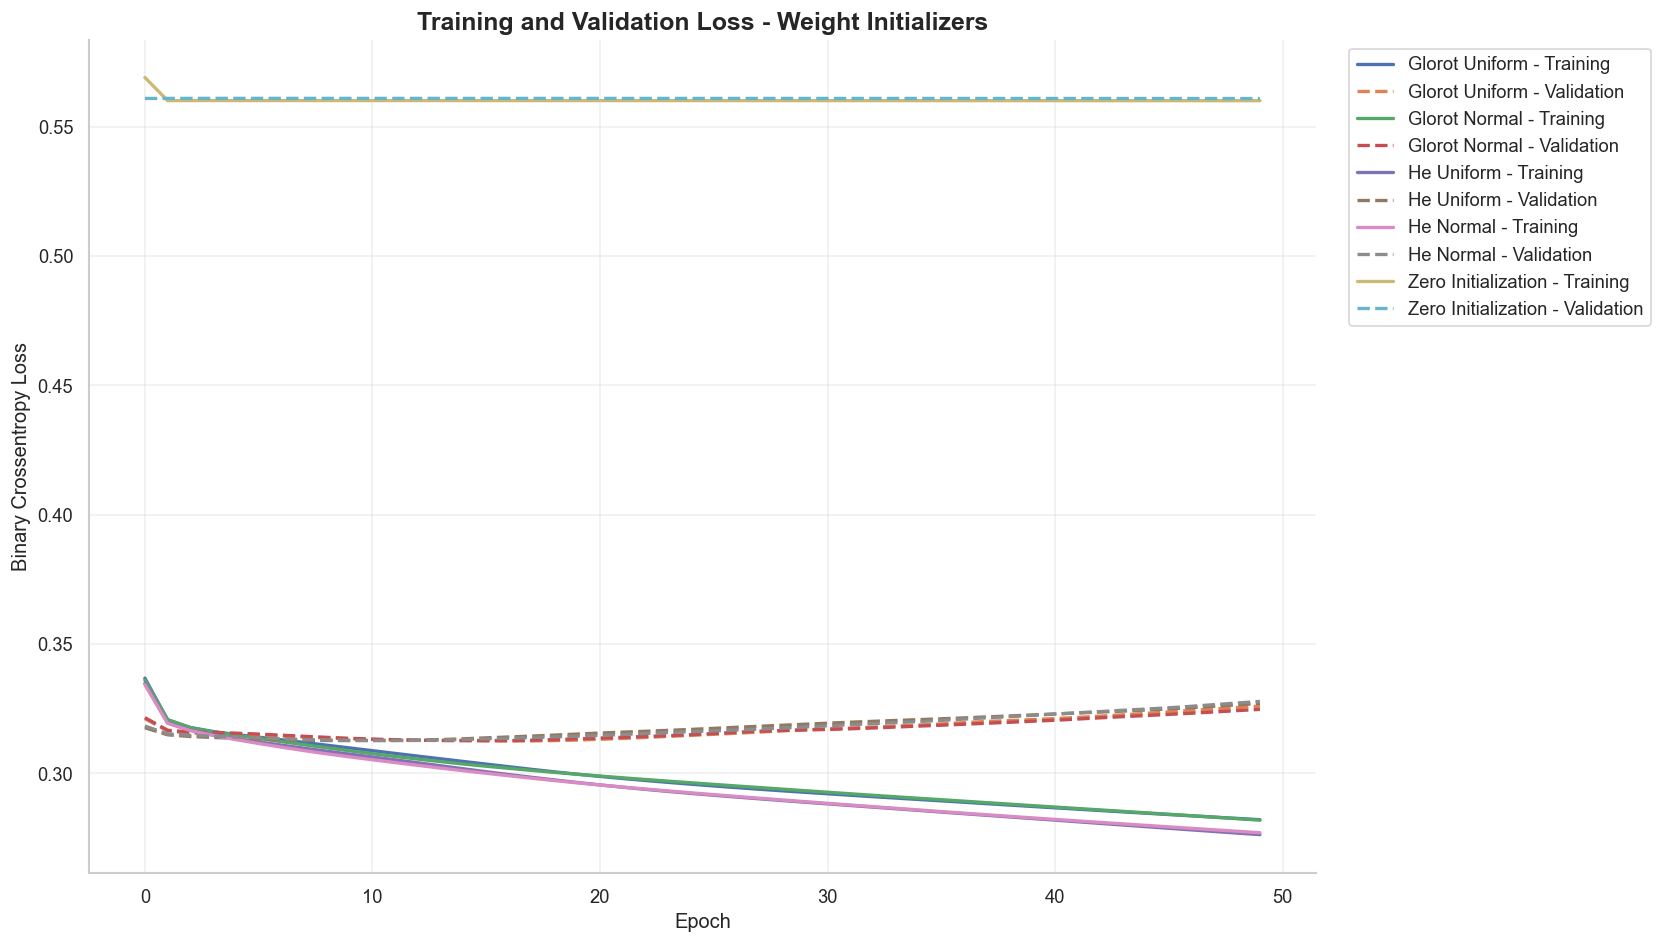


TASK 4.7: WEIGHT DISTRIBUTION ANALYSIS


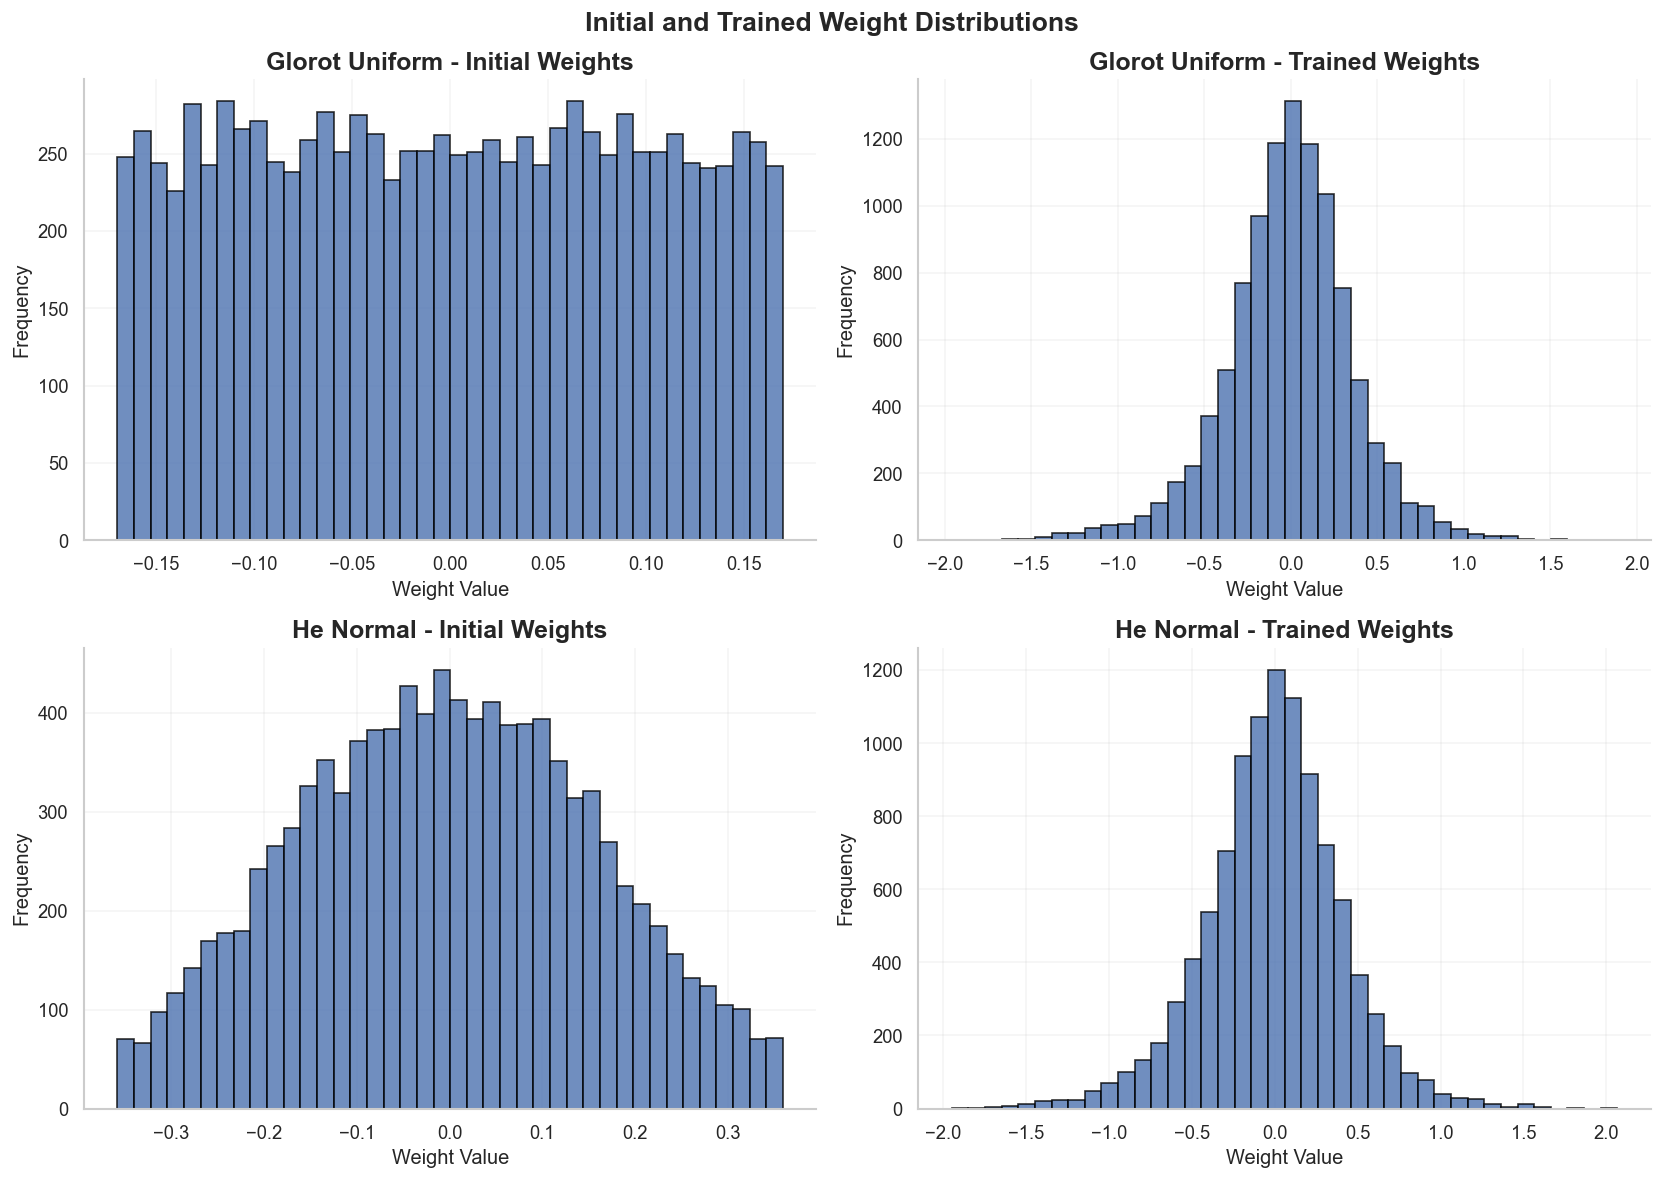


TASK 4.8: WEIGHT STATISTICS

WEIGHT STATISTICS TABLE


,Initializer,Stage,Layer,Mean,Standard Deviation,Minimum,Maximum,Zero Weight Percentage
0,Glorot Uniform,Initial,Layer 1,-0.000316,0.097648,-0.169736,0.169824,0.00%
1,Glorot Uniform,Initial,Layer 2,-0.001187,0.102457,-0.176772,0.176665,0.00%
2,Glorot Uniform,Final,Layer 1,-0.010370,0.372285,-1.959796,1.886527,0.00%
3,Glorot Uniform,Final,Layer 2,-0.009173,0.195425,-1.728064,0.896165,0.00%
4,Glorot Normal,Initial,Layer 1,-0.001947,0.098206,-0.222299,0.222948,0.00%
5,Glorot Normal,Initial,Layer 2,0.001200,0.103021,-0.231867,0.231592,0.00%
6,Glorot Normal,Final,Layer 1,-0.005610,0.373942,-1.758575,1.939642,0.00%
7,Glorot Normal,Final,Layer 2,-0.001959,0.190449,-2.049289,1.140232,0.00%
8,He Uniform,Initial,Layer 1,-0.000509,0.157452,-0.273692,0.273833,0.00%
9,He Uniform,Initial,Layer 2,-0.001454,0.125483,-0.216501,0.216370,0.00%



TASK 4.9: ZERO INITIALIZATION ANALYSIS

ZERO INITIALIZATION NEURON SYMMETRY RESULTS


,Hidden Layer,Total Neurons,Unique Neurons Before Training,Unique Neurons After Training,Initial Symmetry Percentage,Final Symmetry Percentage
0,Layer 1,128,1,1,99.22%,99.22%
1,Layer 2,64,1,1,98.44%,98.44%



TASK 4.10: ROC CURVE COMPARISON


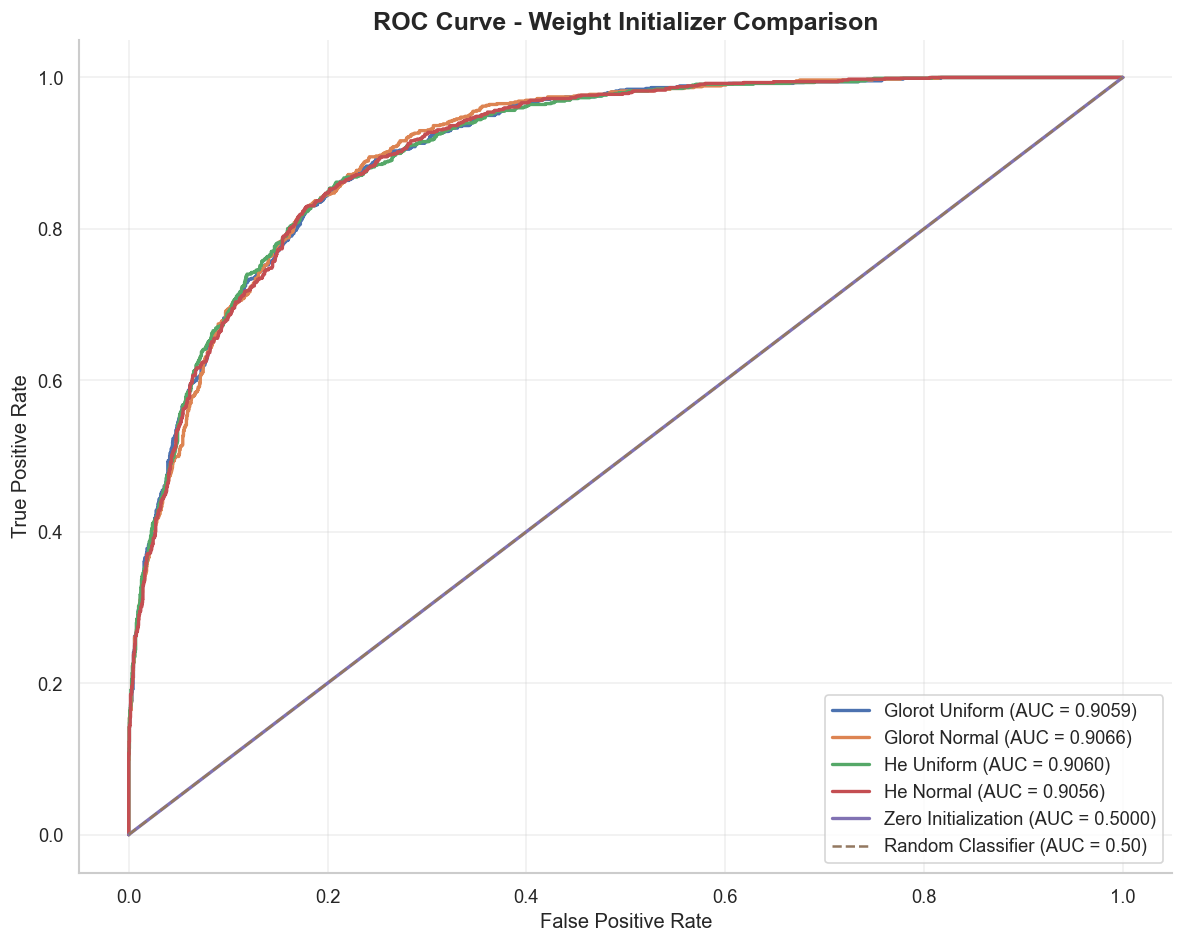


TASK 4.11: FINAL INITIALIZER RANKING


,Initializer,Validation Accuracy,Precision,Recall,F1-Score,ROC-AUC,Best Validation Accuracy,Minimum Validation Loss,Best Accuracy Epoch,Best Loss Epoch,Epochs to Reach 82%
0,He Uniform,0.8513,0.7568,0.5897,0.6629,0.9060,0.8566,0.3126,19,10,1.000000
1,Glorot Uniform,0.8521,0.7631,0.5853,0.6625,0.9059,0.8568,0.3125,21,17,1.000000
2,He Normal,0.8502,0.7622,0.5753,0.6557,0.9056,0.8549,0.3126,13,12,1.000000
3,Glorot Normal,0.8466,0.7457,0.5786,0.6516,0.9066,0.8552,0.3126,15,17,1.000000
4,Zero Initialization,0.7521,0.0000,0.0000,0.0000,0.5000,0.7521,0.5608,1,50,nan



BEST WEIGHT INITIALIZER
-----------------------------------------------------------------
Selected Initializer : He Uniform
Initializer Value    : he_uniform
Activation Function  : ELU
Validation Accuracy : 0.8513
Precision            : 0.7568
Recall               : 0.5897
F1-Score             : 0.6629
ROC-AUC              : 0.9060

TASK 4.12: SAVE AND VERIFY RESULTS
SUCCESS: task4_initializer_comparison.csv
SUCCESS: task4_weight_statistics.csv
SUCCESS: task4_zero_initialization_analysis.csv
SUCCESS: task4_final_initializer_ranking.csv
SUCCESS: task4_experiment_configuration.csv
SUCCESS: task4_best_initializer_model.keras
SUCCESS: 12_initializer_accuracy_comparison.png
SUCCESS: 13_initializer_loss_comparison.png
SUCCESS: 14_initializer_weight_distributions.png
SUCCESS: 15_initializer_roc_comparison.png

TASK 4: ALL EXPERIMENTS COMPLETED

Best Initializer: He Uniform
The selected model is based on validation F1-score, with ROC-AUC and validation accuracy as tie-breakers.

Test dataset 

In [9]:
# =============================================================================
# DEEP LEARNING PRACTICAL 02
# TASK 4: COMPARISON OF WEIGHT INITIALIZERS
# =============================================================================

print("=" * 95)
print("TASK 4: COMPARISON OF WEIGHT INITIALIZERS")
print("=" * 95)

# =============================================================================
# TASK 4.1: EXPERIMENTAL CONFIGURATION AND DATA VALIDATION
# =============================================================================

required_variables = [
    "X_train_exp", "X_val_exp",
    "y_train_exp", "y_val_exp",
    "INPUT_DIM", "HIDDEN_UNITS",
    "SEED", "DATA_DIR", "PLOTS_DIR"
]

missing_variables = [
    variable for variable in required_variables
    if variable not in globals()
]

if missing_variables:
    raise NameError(
        f"Missing variables: {missing_variables}. "
        "Execute Tasks 1 and 2 first."
    )

assert X_train_exp.shape[1] == INPUT_DIM
assert X_val_exp.shape[1] == INPUT_DIM
assert len(X_train_exp) == len(y_train_exp)
assert len(X_val_exp) == len(y_val_exp)
assert np.isfinite(X_train_exp).all()
assert np.isfinite(X_val_exp).all()

assert set(np.unique(y_train_exp)).issubset({0, 1})
assert set(np.unique(y_val_exp)).issubset({0, 1})

# Use the best activation function selected in Task 3.
# ELU is the fallback if the Task 3 variable is unavailable.

TASK4_ACTIVATION = (
    best_activation.lower()
    if "best_activation" in globals()
    else "elu"
)

INITIALIZER_CONFIG = {
    "Glorot Uniform": "glorot_uniform",
    "Glorot Normal": "glorot_normal",
    "He Uniform": "he_uniform",
    "He Normal": "he_normal",
    "Zero Initialization": "zeros"
}

TASK4_EPOCHS = 50
TASK4_BATCH_SIZE = 64
TASK4_LEARNING_RATE = 0.001
TASK4_REFERENCE_ACCURACY = 0.82
TASK4_THRESHOLD = 0.50

print("\nEXPERIMENTAL CONFIGURATION")
print("-" * 65)

print(f"Input Features        : {INPUT_DIM}")
print(f"Hidden Layers         : {HIDDEN_UNITS}")
print(f"Activation Function  : {TASK4_ACTIVATION.upper()}")
print(f"Epochs                : {TASK4_EPOCHS}")
print(f"Batch Size            : {TASK4_BATCH_SIZE}")
print("Optimizer             : Adam")
print(f"Learning Rate         : {TASK4_LEARNING_RATE}")
print("Loss Function         : Binary Crossentropy")
print("Output Activation     : Sigmoid")
print("Output Initializer    : Glorot Uniform")
print(f"Reference Accuracy    : {TASK4_REFERENCE_ACCURACY:.0%}")
print(f"Training Samples      : {len(X_train_exp):,}")
print(f"Validation Samples    : {len(X_val_exp):,}")

print("\nInitializers to compare:")
for name, initializer in INITIALIZER_CONFIG.items():
    print(f"- {name}: {initializer}")

# =============================================================================
# TASK 4.2: CREATE A REUSABLE ANN MODEL BUILDER
# =============================================================================

def build_initializer_model(
    input_dim,
    hidden_units,
    activation,
    initializer,
    learning_rate
):

    model = Sequential(name=f"ANN_{initializer}")

    # Explicit input layer avoids unbuilt Sequential model issues.
    model.add(
        Input(shape=(input_dim,), name="input_layer")
    )

    # Hidden layers use the initializer being tested.
    for layer_number, units in enumerate(
        hidden_units,
        start=1
    ):

        model.add(
            Dense(
                units,
                activation=activation,
                kernel_initializer=initializer,
                bias_initializer="zeros",
                name=f"hidden_dense_{layer_number}"
            )
        )

    # Keep output initialization identical for every experiment.
    model.add(
        Dense(
            1,
            activation="sigmoid",
            kernel_initializer=GlorotUniform(),
            bias_initializer="zeros",
            name="output_layer"
        )
    )

    model.compile(
        optimizer=Adam(
            learning_rate=learning_rate
        ),
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall")
        ]
    )

    return model


# =============================================================================
# TASK 4.3: TRAIN ALL FIVE INITIALIZER MODELS
# =============================================================================

initializer_models = {}
initializer_histories = {}

# Capture initial and final weights for distribution analysis.
initializer_weight_data = {}

for initializer_name, initializer in INITIALIZER_CONFIG.items():

    print("\n" + "=" * 85)
    print(f"TRAINING MODEL: {initializer_name.upper()}")
    print("=" * 85)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    model = build_initializer_model(
        input_dim=INPUT_DIM,
        hidden_units=HIDDEN_UNITS,
        activation=TASK4_ACTIVATION,
        initializer=initializer,
        learning_rate=TASK4_LEARNING_RATE
    )

    # Store initial hidden-layer weights before training.
    initial_weights = {}

    for layer_number in range(1, len(HIDDEN_UNITS) + 1):

        layer = model.get_layer(
            f"hidden_dense_{layer_number}"
        )

        initial_weights[f"Layer {layer_number}"] = (
            layer.get_weights()[0].copy()
        )

    initializer_weight_data[initializer_name] = {
        "initial": initial_weights
    }

    # Train using the same training and validation data.
    history = model.fit(
        X_train_exp,
        y_train_exp,
        epochs=TASK4_EPOCHS,
        batch_size=TASK4_BATCH_SIZE,
        validation_data=(X_val_exp, y_val_exp),
        shuffle=True,
        verbose=1
    )

    # Save trained models and histories.
    initializer_models[initializer_name] = model
    initializer_histories[initializer_name] = history

    # Store final hidden-layer weights after training.
    final_weights = {}

    for layer_number in range(1, len(HIDDEN_UNITS) + 1):

        layer = model.get_layer(
            f"hidden_dense_{layer_number}"
        )

        final_weights[f"Layer {layer_number}"] = (
            layer.get_weights()[0].copy()
        )

    initializer_weight_data[initializer_name]["final"] = final_weights

    print(f"\n{initializer_name} training completed.")

print("\nAll five initializer models have been trained.")

# =============================================================================
# TASK 4.4: VALIDATION PERFORMANCE COMPARISON
# =============================================================================

print("\n" + "=" * 95)
print("TASK 4.4: VALIDATION PERFORMANCE COMPARISON")
print("=" * 95)

initializer_results = []
initializer_validation_probabilities = {}

for initializer_name, model in initializer_models.items():

    probabilities = model.predict(
        X_val_exp,
        verbose=0
    ).ravel()

    predictions = (
        probabilities >= TASK4_THRESHOLD
    ).astype(int)

    initializer_validation_probabilities[
        initializer_name
    ] = probabilities

    accuracy = accuracy_score(
        y_val_exp,
        predictions
    )

    precision = precision_score(
        y_val_exp,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_val_exp,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_val_exp,
        predictions,
        zero_division=0
    )

    auc = roc_auc_score(
        y_val_exp,
        probabilities
    )

    history = initializer_histories[initializer_name].history

    validation_accuracy = history["val_accuracy"]
    validation_loss = history["val_loss"]

    # Find the first epoch reaching the reference accuracy.
    reference_epochs = [
        epoch + 1
        for epoch, score in enumerate(validation_accuracy)
        if score >= TASK4_REFERENCE_ACCURACY
    ]

    first_reference_epoch = (
        reference_epochs[0]
        if reference_epochs
        else None
    )

    initializer_results.append({

        "Initializer": initializer_name,

        "Validation Accuracy": accuracy,

        "Precision": precision,

        "Recall": recall,

        "F1-Score": f1,

        "ROC-AUC": auc,

        "Best Validation Accuracy": max(validation_accuracy),

        "Minimum Validation Loss": min(validation_loss),

        "Best Accuracy Epoch": int(
            np.argmax(validation_accuracy) + 1
        ),

        "Best Loss Epoch": int(
            np.argmin(validation_loss) + 1
        ),

        "Epochs to Reach 82%": first_reference_epoch

    })


initializer_results_df = pd.DataFrame(
    initializer_results
)

initializer_results_df = initializer_results_df.sort_values(
    by=["F1-Score", "ROC-AUC", "Validation Accuracy"],
    ascending=False
).reset_index(drop=True)

print("\nINITIALIZER PERFORMANCE TABLE")

display(
    initializer_results_df.style.format({
        "Validation Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "Best Validation Accuracy": "{:.4f}",
        "Minimum Validation Loss": "{:.4f}"
    })
)

initializer_results_df.to_csv(
    DATA_DIR / "task4_initializer_comparison.csv",
    index=False
)

# =============================================================================
# TASK 4.5: TRAINING AND VALIDATION ACCURACY COMPARISON
# =============================================================================

print("\n" + "=" * 95)
print("TASK 4.5: ACCURACY COMPARISON")
print("=" * 95)

plt.figure(figsize=(14, 8))

for initializer_name in INITIALIZER_CONFIG:

    history = initializer_histories[initializer_name].history

    plt.plot(
        history["accuracy"],
        linewidth=2,
        label=f"{initializer_name} - Training"
    )

    plt.plot(
        history["val_accuracy"],
        linewidth=2,
        linestyle="--",
        label=f"{initializer_name} - Validation"
    )

plt.axhline(
    TASK4_REFERENCE_ACCURACY,
    linestyle=":",
    linewidth=2,
    label="82% Reference Accuracy"
)

plt.title(
    "Training and Validation Accuracy - Weight Initializers",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "12_initializer_accuracy_comparison.png",
    bbox_inches="tight"
)

plt.show()

# =============================================================================
# TASK 4.6: TRAINING AND VALIDATION LOSS COMPARISON
# =============================================================================

print("\n" + "=" * 95)
print("TASK 4.6: LOSS COMPARISON")
print("=" * 95)

plt.figure(figsize=(14, 8))

for initializer_name in INITIALIZER_CONFIG:

    history = initializer_histories[initializer_name].history

    plt.plot(
        history["loss"],
        linewidth=2,
        label=f"{initializer_name} - Training"
    )

    plt.plot(
        history["val_loss"],
        linewidth=2,
        linestyle="--",
        label=f"{initializer_name} - Validation"
    )

plt.title(
    "Training and Validation Loss - Weight Initializers",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Epoch")
plt.ylabel("Binary Crossentropy Loss")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "13_initializer_loss_comparison.png",
    bbox_inches="tight"
)

plt.show()

# =============================================================================
# TASK 4.7: INITIAL AND TRAINED WEIGHT DISTRIBUTION
# =============================================================================

print("\n" + "=" * 95)
print("TASK 4.7: WEIGHT DISTRIBUTION ANALYSIS")
print("=" * 95)

# Compare He Normal and Glorot Uniform.
# The first hidden layer is used for a consistent comparison.

selected_initializers = [
    "Glorot Uniform",
    "He Normal"
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 10)
)

plot_index = 0

for initializer_name in selected_initializers:

    initial_kernel = initializer_weight_data[
        initializer_name
    ]["initial"]["Layer 1"].ravel()

    final_kernel = initializer_weight_data[
        initializer_name
    ]["final"]["Layer 1"].ravel()

    axes[plot_index, 0].hist(
        initial_kernel,
        bins=40,
        edgecolor="black",
        alpha=0.8
    )

    axes[plot_index, 0].set_title(
        f"{initializer_name} - Initial Weights"
    )

    axes[plot_index, 0].set_xlabel("Weight Value")
    axes[plot_index, 0].set_ylabel("Frequency")
    axes[plot_index, 0].grid(alpha=0.2)

    axes[plot_index, 1].hist(
        final_kernel,
        bins=40,
        edgecolor="black",
        alpha=0.8
    )

    axes[plot_index, 1].set_title(
        f"{initializer_name} - Trained Weights"
    )

    axes[plot_index, 1].set_xlabel("Weight Value")
    axes[plot_index, 1].set_ylabel("Frequency")
    axes[plot_index, 1].grid(alpha=0.2)

    plot_index += 1

fig.suptitle(
    "Initial and Trained Weight Distributions",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "14_initializer_weight_distributions.png",
    bbox_inches="tight"
)

plt.show()

# =============================================================================
# TASK 4.8: WEIGHT STATISTICS BEFORE AND AFTER TRAINING
# =============================================================================

print("\n" + "=" * 95)
print("TASK 4.8: WEIGHT STATISTICS")
print("=" * 95)

weight_statistics = []

for initializer_name in INITIALIZER_CONFIG:

    for stage in ["initial", "final"]:

        for layer_name, weights in initializer_weight_data[
            initializer_name
        ][stage].items():

            weight_statistics.append({

                "Initializer": initializer_name,

                "Stage": stage.capitalize(),

                "Layer": layer_name,

                "Mean": float(np.mean(weights)),

                "Standard Deviation": float(np.std(weights)),

                "Minimum": float(np.min(weights)),

                "Maximum": float(np.max(weights)),

                "Zero Weight Percentage": float(
                    np.mean(np.isclose(weights, 0.0)) * 100
                )

            })

weight_statistics_df = pd.DataFrame(
    weight_statistics
)

print("\nWEIGHT STATISTICS TABLE")

display(
    weight_statistics_df.style.format({
        "Mean": "{:.6f}",
        "Standard Deviation": "{:.6f}",
        "Minimum": "{:.6f}",
        "Maximum": "{:.6f}",
        "Zero Weight Percentage": "{:.2f}%"
    })
)

weight_statistics_df.to_csv(
    DATA_DIR / "task4_weight_statistics.csv",
    index=False
)

# =============================================================================
# TASK 4.9: ZERO INITIALIZATION AND NEURON SYMMETRY ANALYSIS
# =============================================================================

print("\n" + "=" * 95)
print("TASK 4.9: ZERO INITIALIZATION ANALYSIS")
print("=" * 95)

zero_model = initializer_models["Zero Initialization"]

zero_symmetry_results = []

for layer_number in range(1, len(HIDDEN_UNITS) + 1):

    layer_name = f"Layer {layer_number}"

    initial_kernel = initializer_weight_data[
        "Zero Initialization"
    ]["initial"][layer_name]

    final_kernel = initializer_weight_data[
        "Zero Initialization"
    ]["final"][layer_name]

    # Each column represents the incoming weights of one neuron.
    initial_unique_neurons = np.unique(
        np.round(initial_kernel, decimals=10),
        axis=1
    ).shape[1]

    final_unique_neurons = np.unique(
        np.round(final_kernel, decimals=10),
        axis=1
    ).shape[1]

    total_neurons = initial_kernel.shape[1]

    zero_symmetry_results.append({

        "Hidden Layer": layer_name,

        "Total Neurons": total_neurons,

        "Unique Neurons Before Training": initial_unique_neurons,

        "Unique Neurons After Training": final_unique_neurons,

        "Initial Symmetry Percentage": (
            total_neurons - initial_unique_neurons
        ) / total_neurons * 100,

        "Final Symmetry Percentage": (
            total_neurons - final_unique_neurons
        ) / total_neurons * 100

    })

zero_symmetry_df = pd.DataFrame(
    zero_symmetry_results
)

print("\nZERO INITIALIZATION NEURON SYMMETRY RESULTS")

display(
    zero_symmetry_df.style.format({
        "Initial Symmetry Percentage": "{:.2f}%",
        "Final Symmetry Percentage": "{:.2f}%"
    })
)

zero_symmetry_df.to_csv(
    DATA_DIR / "task4_zero_initialization_analysis.csv",
    index=False
)

# =============================================================================
# TASK 4.10: ROC CURVE COMPARISON
# =============================================================================

print("\n" + "=" * 95)
print("TASK 4.10: ROC CURVE COMPARISON")
print("=" * 95)

plt.figure(figsize=(10, 8))

for initializer_name in INITIALIZER_CONFIG:

    probabilities = initializer_validation_probabilities[
        initializer_name
    ]

    fpr, tpr, thresholds = roc_curve(
        y_val_exp,
        probabilities
    )

    auc_value = roc_auc_score(
        y_val_exp,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{initializer_name} (AUC = {auc_value:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier (AUC = 0.50)"
)

plt.title(
    "ROC Curve - Weight Initializer Comparison",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "15_initializer_roc_comparison.png",
    bbox_inches="tight"
)

plt.show()

# =============================================================================
# TASK 4.11: FINAL RANKING AND BEST INITIALIZER SELECTION
# =============================================================================

print("\n" + "=" * 95)
print("TASK 4.11: FINAL INITIALIZER RANKING")
print("=" * 95)

final_initializer_ranking = initializer_results_df.sort_values(
    by=["F1-Score", "ROC-AUC", "Validation Accuracy"],
    ascending=False
).reset_index(drop=True)

display(
    final_initializer_ranking.style.format({
        "Validation Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "Best Validation Accuracy": "{:.4f}",
        "Minimum Validation Loss": "{:.4f}"
    })
)

best_initializer_name = (
    final_initializer_ranking.iloc[0]["Initializer"]
)

best_initializer_model = initializer_models[
    best_initializer_name
]

best_initializer_value = INITIALIZER_CONFIG[
    best_initializer_name
]

print("\nBEST WEIGHT INITIALIZER")
print("-" * 65)

print(f"Selected Initializer : {best_initializer_name}")
print(f"Initializer Value    : {best_initializer_value}")
print(f"Activation Function  : {TASK4_ACTIVATION.upper()}")

print(
    f"Validation Accuracy : "
    f"{final_initializer_ranking.iloc[0]['Validation Accuracy']:.4f}"
)

print(
    f"Precision            : "
    f"{final_initializer_ranking.iloc[0]['Precision']:.4f}"
)

print(
    f"Recall               : "
    f"{final_initializer_ranking.iloc[0]['Recall']:.4f}"
)

print(
    f"F1-Score             : "
    f"{final_initializer_ranking.iloc[0]['F1-Score']:.4f}"
)

print(
    f"ROC-AUC              : "
    f"{final_initializer_ranking.iloc[0]['ROC-AUC']:.4f}"
)

# Save selected model.
best_initializer_model.save(
    DATA_DIR / "task4_best_initializer_model.keras"
)

# Save ranking.
final_initializer_ranking.to_csv(
    DATA_DIR / "task4_final_initializer_ranking.csv",
    index=False
)

# Save experiment configuration.
task4_configuration = pd.DataFrame(
    [
        ["Activation Function", TASK4_ACTIVATION],
        ["Hidden Layers", str(HIDDEN_UNITS)],
        ["Epochs", TASK4_EPOCHS],
        ["Batch Size", TASK4_BATCH_SIZE],
        ["Optimizer", "Adam"],
        ["Learning Rate", TASK4_LEARNING_RATE],
        ["Loss Function", "Binary Crossentropy"],
        ["Output Activation", "Sigmoid"],
        ["Output Initializer", "Glorot Uniform"],
        ["Reference Accuracy", TASK4_REFERENCE_ACCURACY],
        ["Classification Threshold", TASK4_THRESHOLD],
        ["Selected Initializer", best_initializer_name]
    ],
    columns=["Parameter", "Value"]
)

task4_configuration.to_csv(
    DATA_DIR / "task4_experiment_configuration.csv",
    index=False
)

# =============================================================================
# TASK 4.12: SAVE AND VERIFY ALL GENERATED FILES
# =============================================================================

print("\n" + "=" * 95)
print("TASK 4.12: SAVE AND VERIFY RESULTS")
print("=" * 95)

generated_files = [

    DATA_DIR / "task4_initializer_comparison.csv",

    DATA_DIR / "task4_weight_statistics.csv",

    DATA_DIR / "task4_zero_initialization_analysis.csv",

    DATA_DIR / "task4_final_initializer_ranking.csv",

    DATA_DIR / "task4_experiment_configuration.csv",

    DATA_DIR / "task4_best_initializer_model.keras",

    PLOTS_DIR / "12_initializer_accuracy_comparison.png",

    PLOTS_DIR / "13_initializer_loss_comparison.png",

    PLOTS_DIR / "14_initializer_weight_distributions.png",

    PLOTS_DIR / "15_initializer_roc_comparison.png"

]

for file_path in generated_files:

    status = "SUCCESS" if file_path.exists() else "MISSING"

    print(f"{status}: {file_path.name}")

print("\n" + "=" * 95)
print("TASK 4: ALL EXPERIMENTS COMPLETED")
print("=" * 95)

print(f"\nBest Initializer: {best_initializer_name}")

print(
    "The selected model is based on validation F1-score, "
    "with ROC-AUC and validation accuracy as tie-breakers."
)

print("\nTest dataset has not been used for initializer selection.")

print("=" * 95)

# TASK 5: COMPARISON OF LOSS FUNCTIONS

## Objective

The objective of this experiment is to evaluate the effect of different loss functions on the performance of an Artificial Neural Network (ANN) for Adult Income Prediction.

The target variable contains two classes:

- Class 0: Income <=50K
- Class 1: Income >50K

Since the dataset is imbalanced, this experiment investigates whether different loss functions can improve the identification of the minority class.

## Loss Functions to Be Compared

1. **Binary Crossentropy (BCE):** Standard loss function for binary classification. It measures the difference between actual binary labels and predicted probabilities.

2. **Mean Squared Error (MSE):** Measures the squared difference between actual labels and predicted probabilities. It is included to compare its effectiveness against a classification-specific loss function.

3. **Weighted Binary Crossentropy:** Assigns higher importance to the minority class during training so that errors involving higher-income individuals receive greater attention.

4. **Focal Loss:** Reduces the contribution of easily classified examples and gives greater attention to difficult examples. It is useful for investigating classification performance on imbalanced datasets.

## Experimental Configuration

To ensure a fair comparison, the following parameters will remain constant:

- Input features: 80
- Hidden layers: 128 and 64 neurons
- Activation function: ELU
- Weight initializer: He Uniform
- Optimizer: Adam
- Learning rate: 0.001
- Batch size: 64
- Training epochs: 50
- Output activation: Sigmoid
- Training and validation datasets: Same across all experiments

Only the loss function and its associated class-weighting strategy will change.

## Evaluation Metrics

The models will be evaluated using:

- Accuracy
- Precision
- Recall
- F1-Score
- ROC-AUC
- Confusion Matrix
- ROC Curve
- Precision-Recall Curve
- Training and Validation Loss
- Training and Validation Accuracy

The F1-score will be the primary metric for model selection because it balances precision and recall. ROC-AUC and accuracy will be used as additional comparison metrics.

**Important:** The validation dataset will be used for model comparison and selection. The test dataset will remain completely unused until the final model evaluation.

TASK 5: COMPARISON OF LOSS FUNCTIONS

DATA VALIDATION
-----------------------------------------------------------------
Training samples       : 32559
Validation samples     : 3618
Input features         : 80
Hidden architecture    : [128, 64]
Activation function    : elu
Weight initializer     : he_uniform
Optimizer              : Adam
Learning rate          : 0.001
Epochs                 : 50
Batch size             : 64

TRAINING CLASS DISTRIBUTION


,Class,Training Samples,Percentage,Balanced Class Weight
0,<=50K (0),24490,75.2173,0.6647
1,>50K (1),8069,24.7827,2.0175



CLASS WEIGHT CONFIGURATION
-----------------------------------------------------------------
Class 0 Weight       : 0.6647
Class 1 Weight       : 2.0175
Focal Alpha Positive : 0.7522
Focal Gamma          : 2.0

FOCAL LOSS DEFINITION
-----------------------------------------------------------------
Focal Loss successfully defined.
Alpha : 0.7521729782855738
Gamma : 2.0

LOSS FUNCTIONS TO BE EVALUATED
1. Binary Crossentropy
    Standard binary classification loss
2. Mean Squared Error
    Squared prediction error
3. Weighted Binary Crossentropy
    Binary crossentropy with balanced class weights
4. Focal Loss
    Class-balanced focal binary crossentropy

TRAINING MODEL: BINARY CROSSENTROPY

Model Architecture


Model: "ANN_Loss_Comparison"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ hidden_layer_1 (Dense)               │ (None, 128)                 │          10,368 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ hidden_layer_2 (Dense)               │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ output_layer (Dense)                 │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 18,689 (73.00 KB)

... (18 outputs left out)

 Trainable params: 18,689 (73.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.7999 - loss: 0.0389 - precision: 0.5650 - recall: 0.8372 - val_accuracy: 0.8118 - val_loss: 0.0372 - val_precision: 0.5860 - val_recall: 0.8205
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8073 - loss: 0.0370 - precision: 0.5749 - recall: 0.8538 - val_accuracy: 0.8109 - val_loss: 0.0364 - val_precision: 0.5820 - val_recall: 0.8428
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8092 - loss: 0.0365 - precision: 0.5775 - recall: 0.8572 - val_accuracy: 0.8090 - val_loss: 0.0361 - val_precision: 0.5774 - val_recall: 0.8562
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8111 - loss: 0.0362 - precision: 0.5800 - recall: 0.8616 - val_accuracy: 0.8087 - val_loss: 0.0360 - val_precision: 0.5761 - val_recall: 0.8651
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8121 - loss: 0.0359 - precision: 0.5816 - recall: 0.8618 - val_accuracy: 0.8090 - val_loss: 0.

,Loss Function,Validation Accuracy,Precision,Recall,F1-Score,ROC-AUC,Best Validation Accuracy,Minimum Validation Loss,Best Accuracy Epoch,Best Loss Epoch,Epochs to Reach 82%
0,Focal Loss,0.8184,0.5968,0.8250,0.6926,0.9019,0.8220,0.0359,36,8,32.0
1,Weighted Binary Crossentropy,0.8151,0.5915,0.8216,0.6878,0.9030,0.8187,0.3646,28,8,NaN
2,Mean Squared Error,0.8505,0.7418,0.6087,0.6687,0.9055,0.8568,0.0994,16,11,1.0
3,Binary Crossentropy,0.8513,0.7568,0.5897,0.6629,0.9060,0.8566,0.3126,19,10,1.0


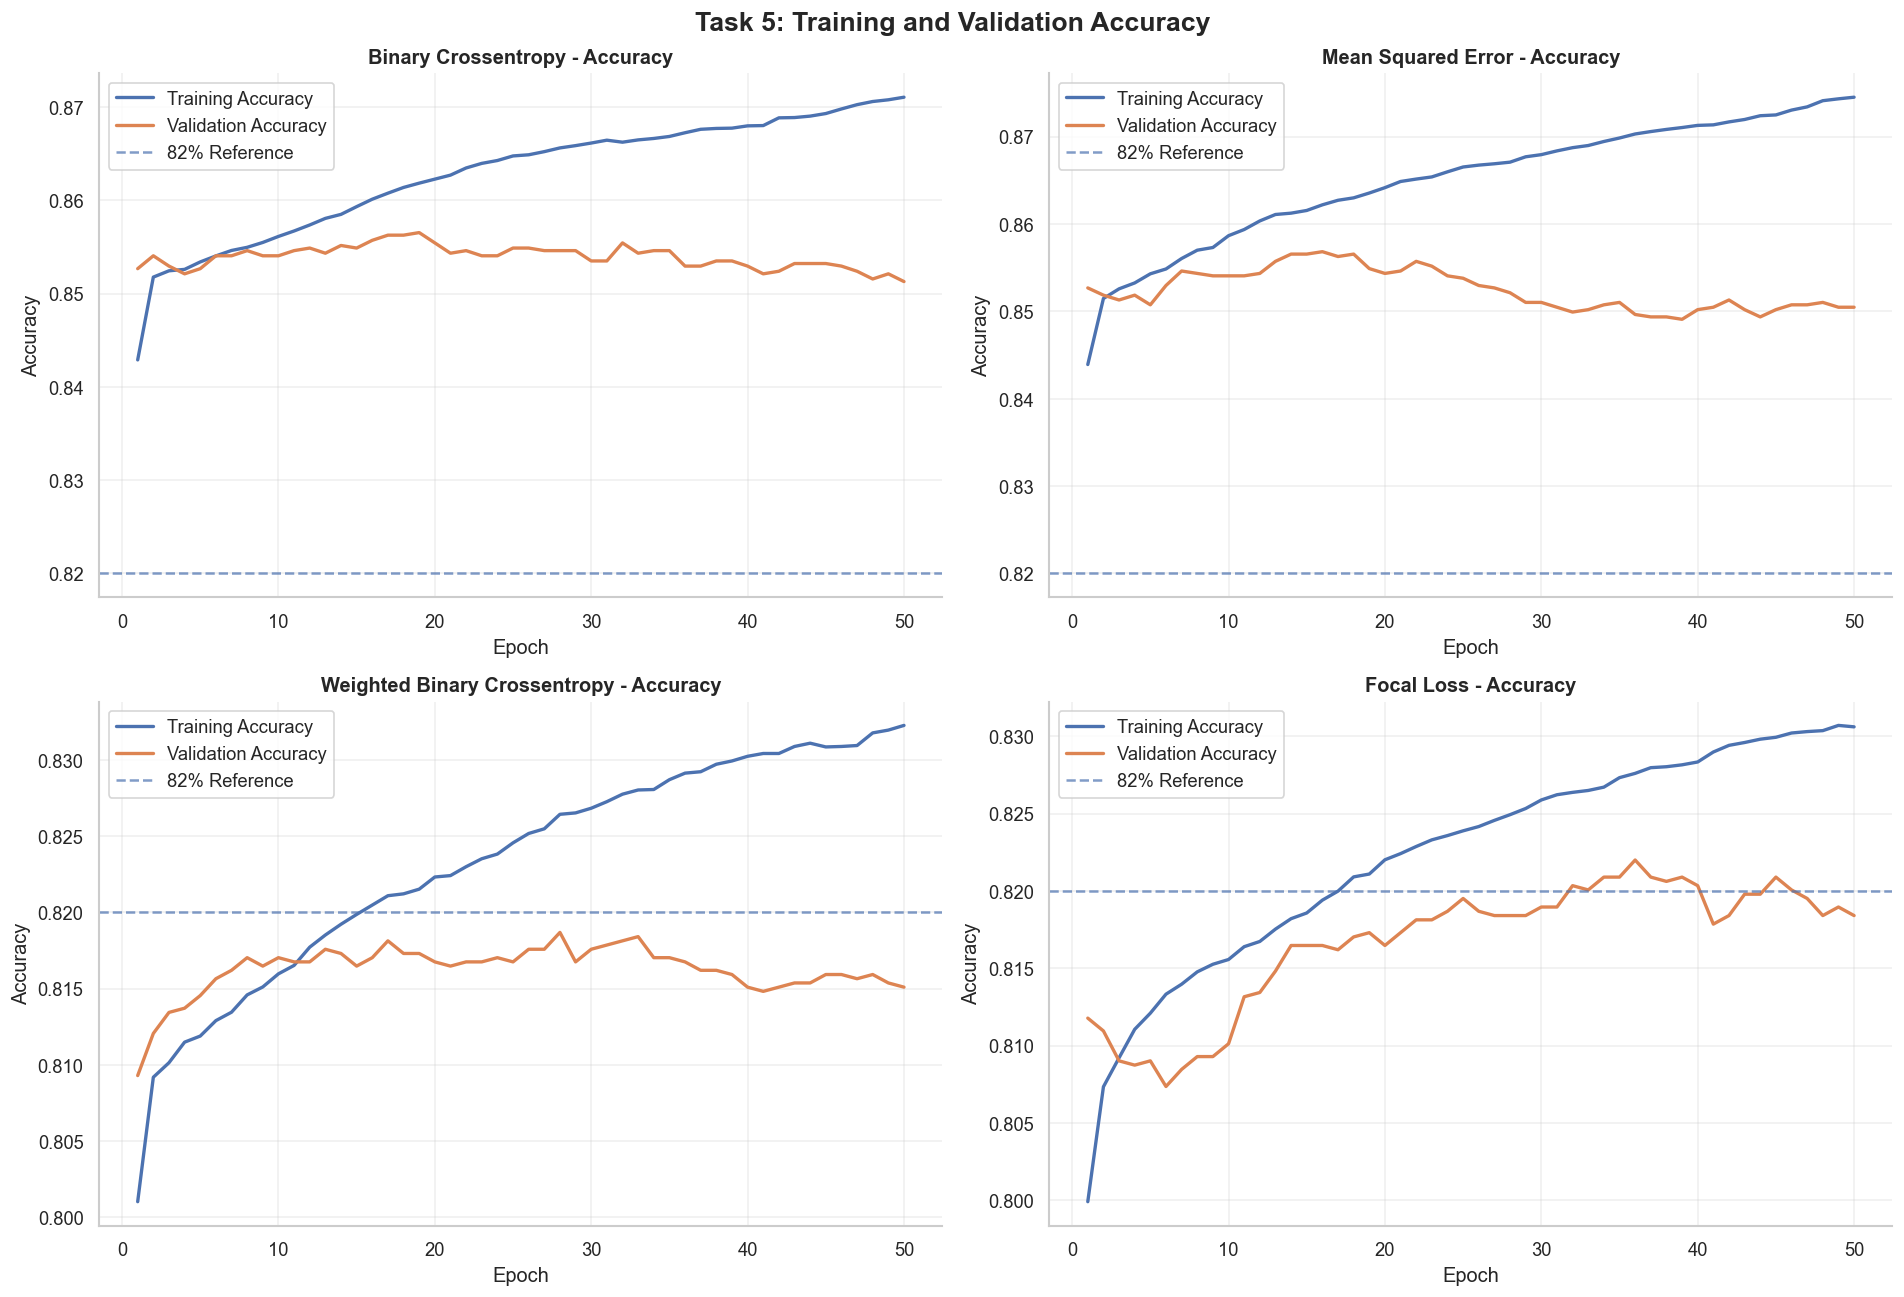

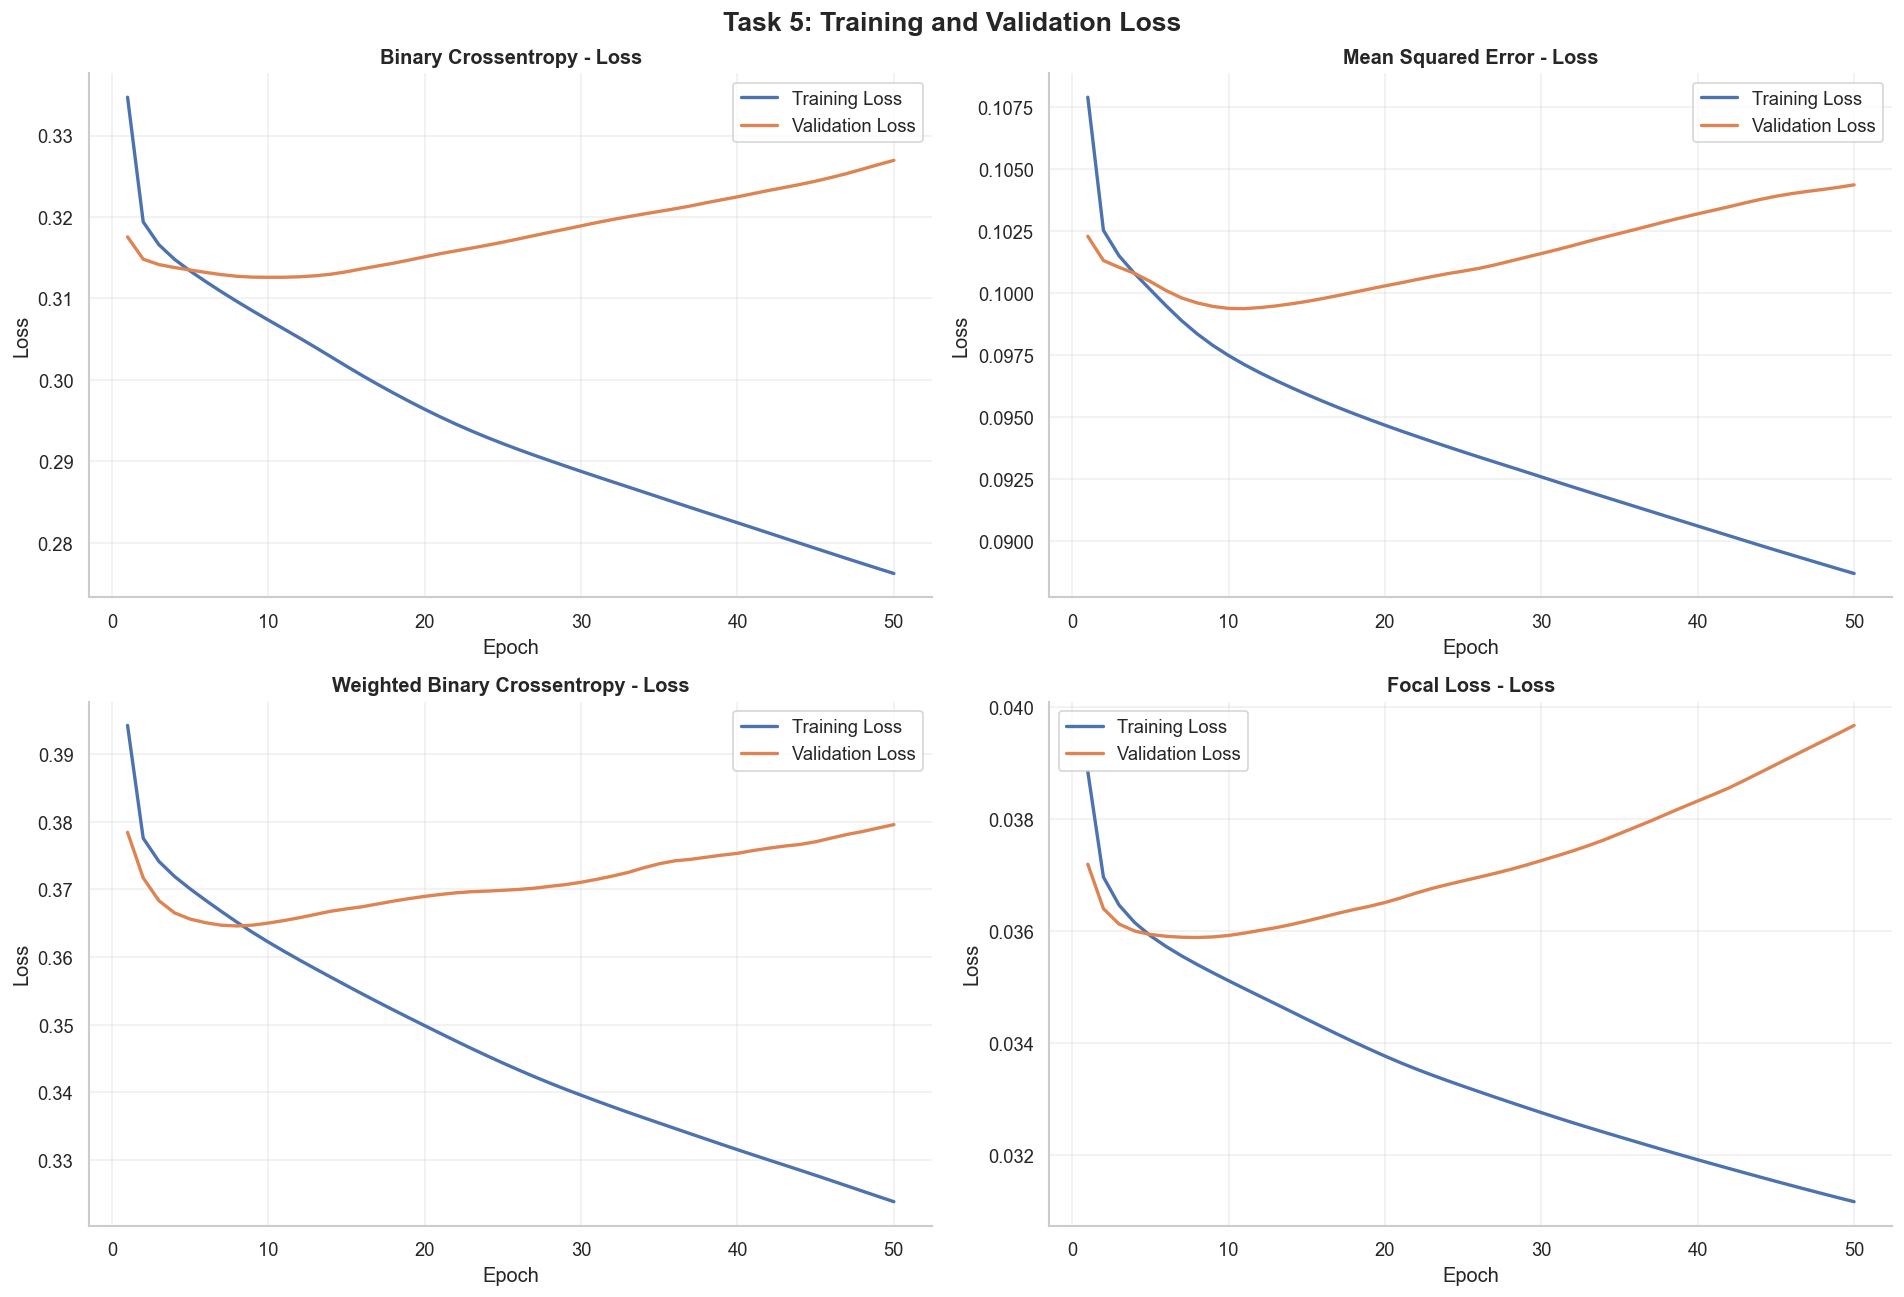

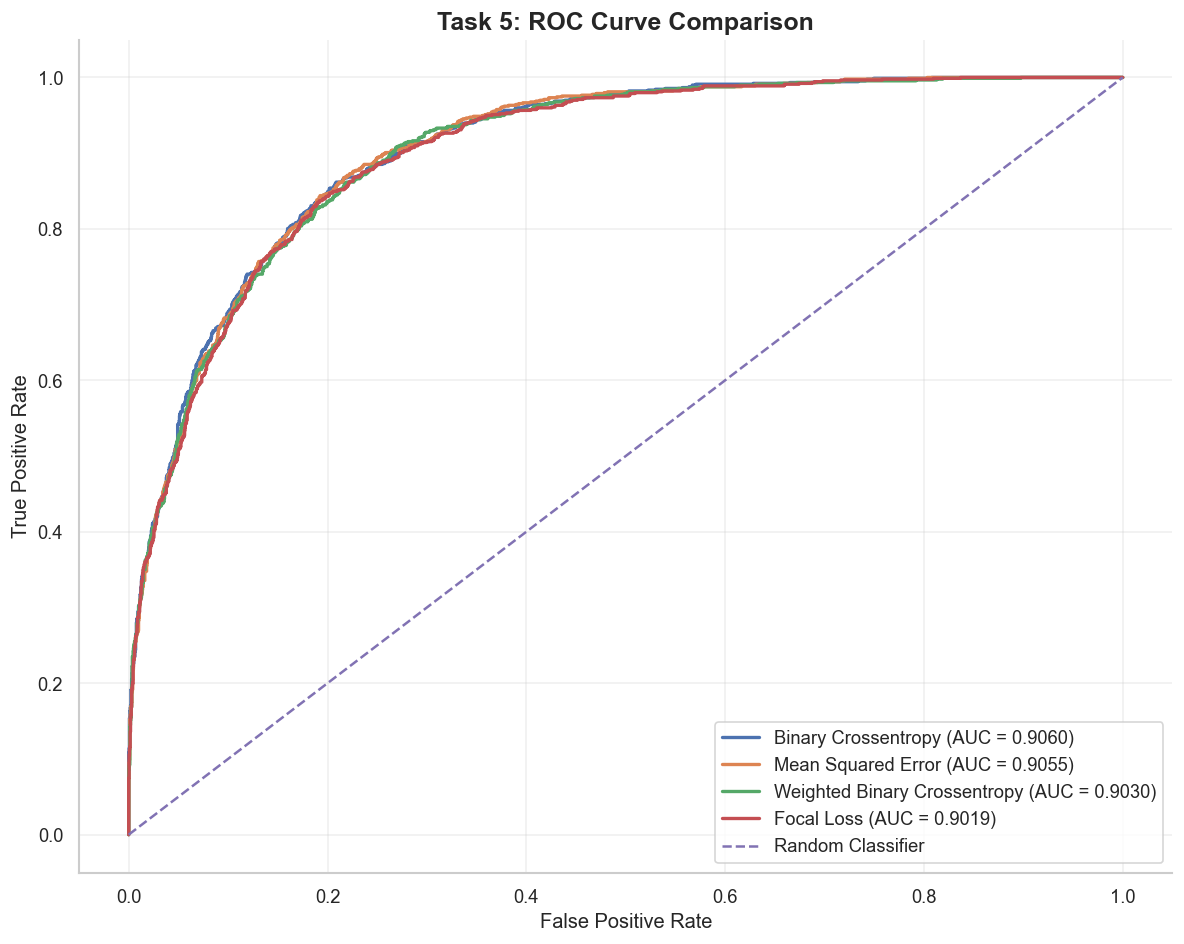

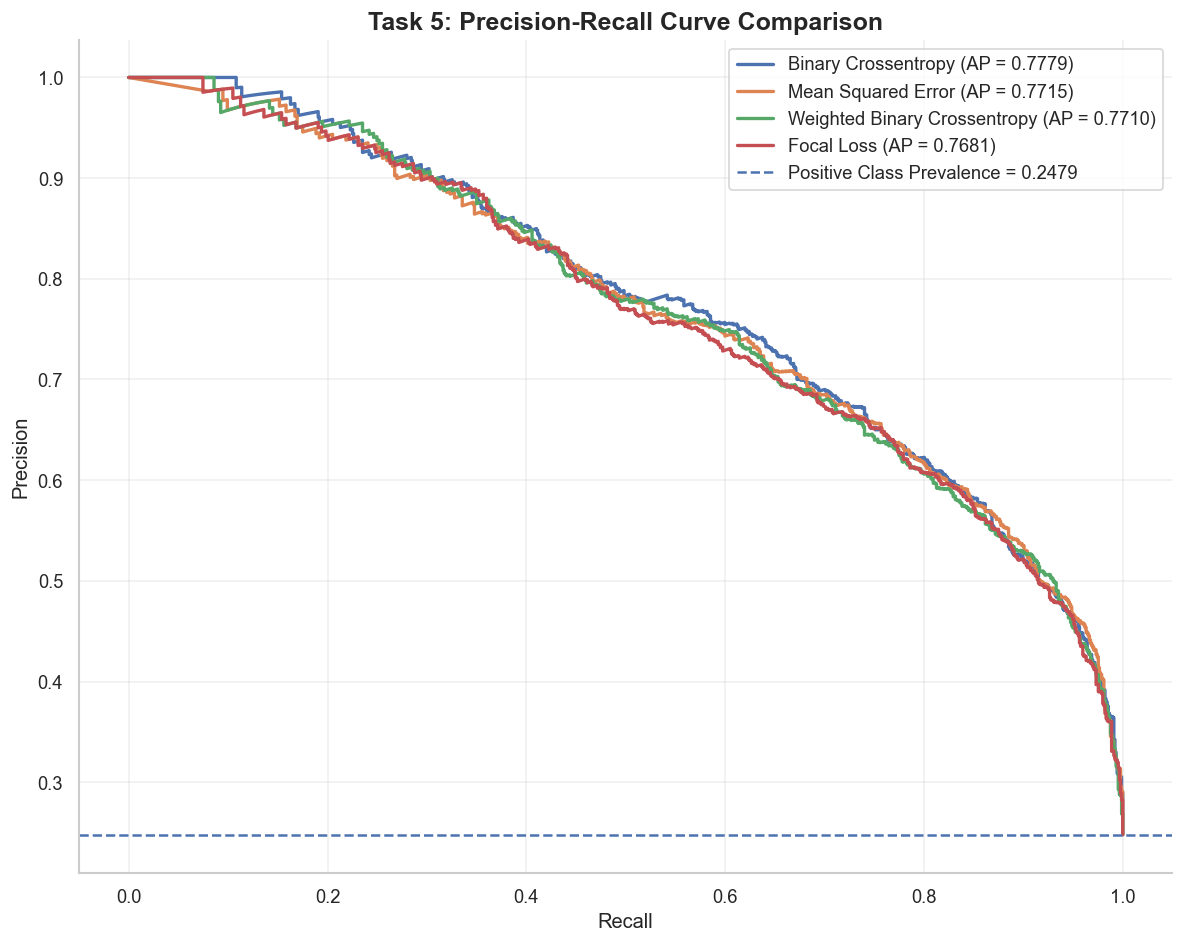

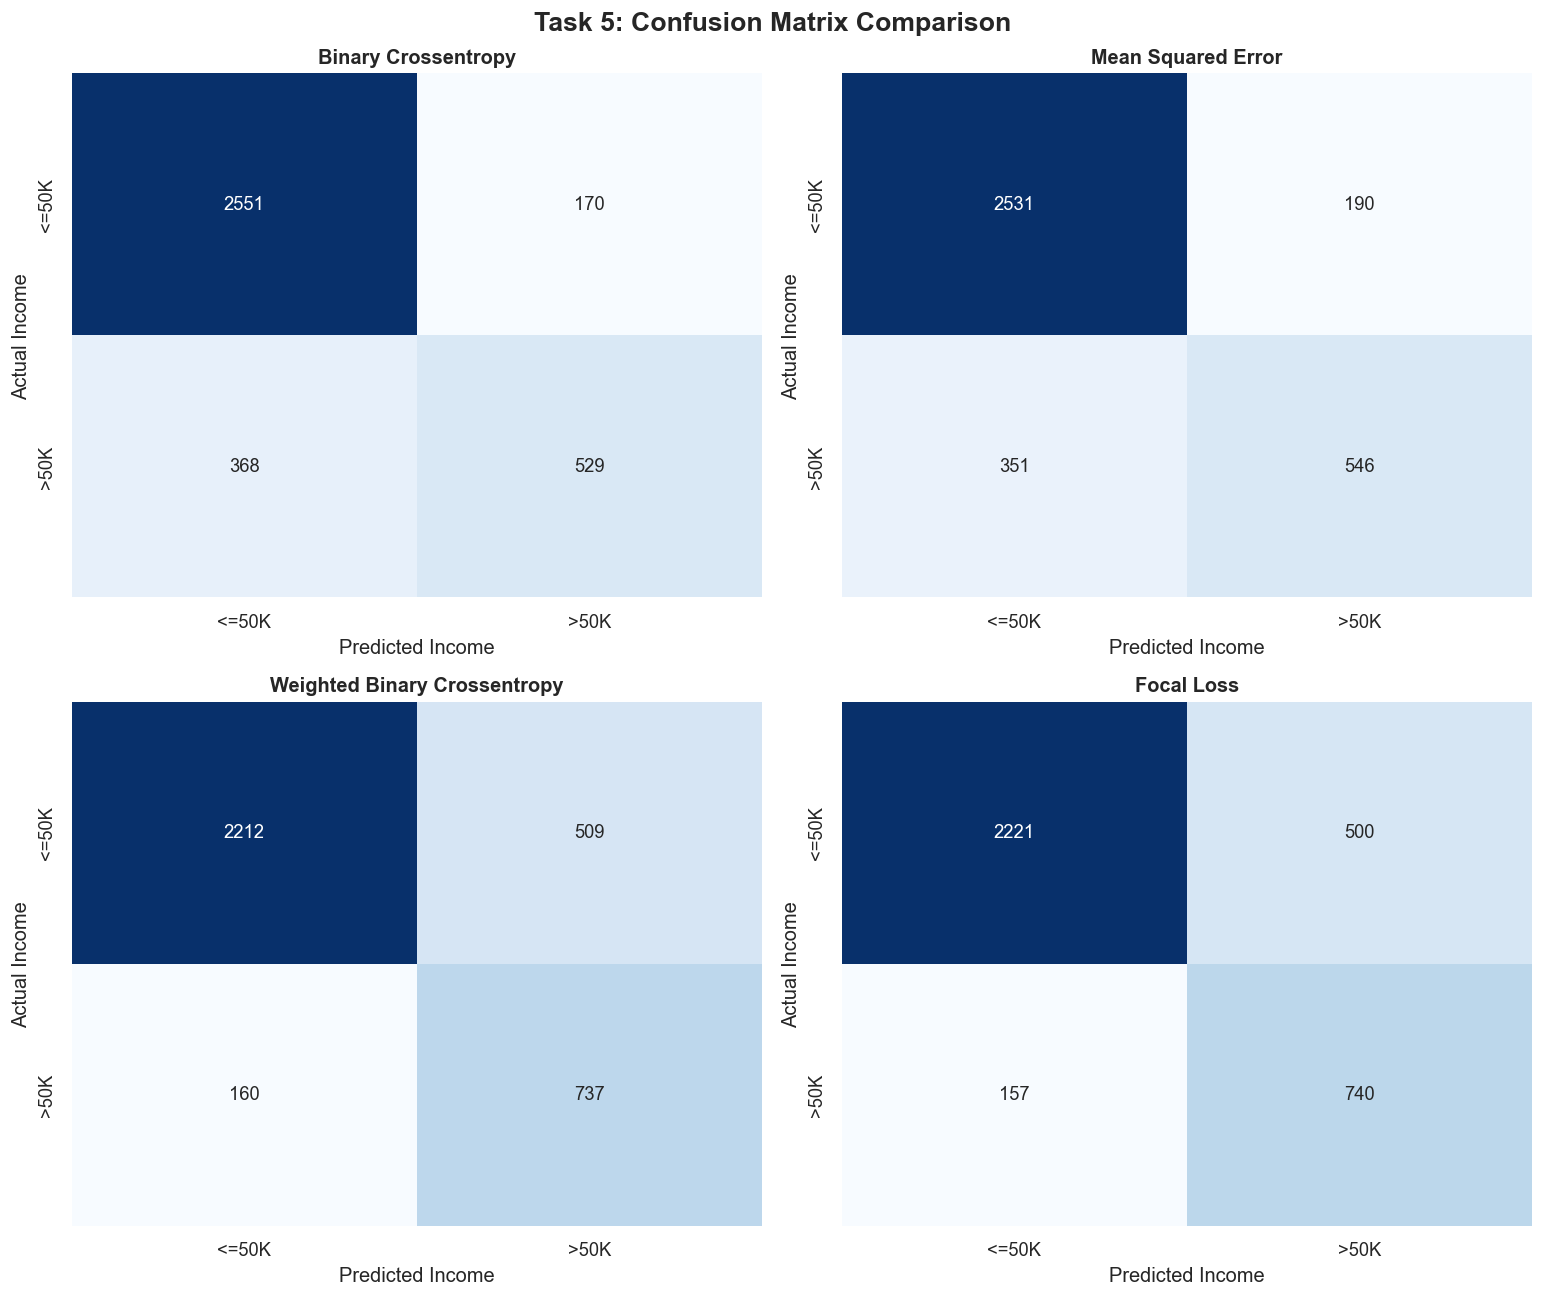


TASK 5.13: DETAILED CLASSIFICATION REPORTS

--------------------------------------------------------------------------------
CLASSIFICATION REPORT: BINARY CROSSENTROPY
--------------------------------------------------------------------------------
              precision    recall  f1-score   support

       <=50K       0.87      0.94      0.90      2721
        >50K       0.76      0.59      0.66       897

    accuracy                           0.85      3618
   macro avg       0.82      0.76      0.78      3618
weighted avg       0.84      0.85      0.84      3618


--------------------------------------------------------------------------------
CLASSIFICATION REPORT: MEAN SQUARED ERROR
--------------------------------------------------------------------------------
              precision    recall  f1-score   support

       <=50K       0.88      0.93      0.90      2721
        >50K       0.74      0.61      0.67       897

    accuracy                           0.85      3618


,Loss Function,Precision,Recall,F1-Score,ROC-AUC,Minority Class
0,Focal Loss,0.5968,0.8250,0.6926,0.9019,>50K
1,Weighted Binary Crossentropy,0.5915,0.8216,0.6878,0.9030,>50K
2,Mean Squared Error,0.7418,0.6087,0.6687,0.9055,>50K
3,Binary Crossentropy,0.7568,0.5897,0.6629,0.9060,>50K



TASK 5.15: FINAL LOSS FUNCTION RANKING


,Rank,Loss Function,Validation Accuracy,Precision,Recall,F1-Score,ROC-AUC,Best Validation Accuracy,Minimum Validation Loss,Best Accuracy Epoch,Best Loss Epoch,Epochs to Reach 82%
0,1,Focal Loss,0.8184,0.5968,0.8250,0.6926,0.9019,0.8220,0.0359,36,8,32.0
1,2,Weighted Binary Crossentropy,0.8151,0.5915,0.8216,0.6878,0.9030,0.8187,0.3646,28,8,NaN
2,3,Mean Squared Error,0.8505,0.7418,0.6087,0.6687,0.9055,0.8568,0.0994,16,11,1.0
3,4,Binary Crossentropy,0.8513,0.7568,0.5897,0.6629,0.9060,0.8566,0.3126,19,10,1.0



SELECTED LOSS FUNCTION
-----------------------------------------------------------------
Best Loss Function : Focal Loss
Validation Accuracy: 0.8184
Precision          : 0.5968
Recall             : 0.8250
F1-Score           : 0.6926
ROC-AUC            : 0.9019

Ranking criteria:
1. Highest validation F1-score
2. Highest ROC-AUC in case of a tie
3. Highest validation accuracy in case of a further tie

Best model saved successfully:
C:\Users\urenp\data\task5_best_loss_model.keras

Saved model verification successful.
Loaded model parameters: 18689

TASK 5.18: OUTPUT FILE VERIFICATION
SUCCESS: task5_class_distribution.csv
SUCCESS: task5_loss_function_comparison.csv
SUCCESS: task5_classification_reports.csv
SUCCESS: task5_minority_class_analysis.csv
SUCCESS: task5_final_loss_ranking.csv
SUCCESS: task5_experiment_configuration.csv
SUCCESS: task5_training_history.csv
SUCCESS: task5_best_loss_model.keras
SUCCESS: 16_loss_accuracy_comparison.png
SUCCESS: 17_loss_curves_comparison.png
SUCCESS:

In [21]:
# =============================================================================
# DEEP LEARNING PRACTICAL 02
# TASK 5: COMPARISON OF LOSS FUNCTIONS
# Adult Income Prediction Using Artificial Neural Networks
# =============================================================================

# =============================================================================
# TASK 5.1: ENVIRONMENT AND DATA VALIDATION
# =============================================================================

print("=" * 95)
print("TASK 5: COMPARISON OF LOSS FUNCTIONS")
print("=" * 95)

required_variables = [
    "X_train_exp",
    "X_val_exp",
    "y_train_exp",
    "y_val_exp",
    "SEED",
    "DATA_DIR",
    "PLOTS_DIR"
]

missing_variables = [
    variable for variable in required_variables
    if variable not in globals()
]

if missing_variables:
    raise NameError(
        f"Missing variables: {missing_variables}. "
        "Please execute the previous practical tasks first."
    )

# Convert inputs into NumPy arrays
X_train_task5 = np.asarray(X_train_exp, dtype=np.float32)
X_val_task5 = np.asarray(X_val_exp, dtype=np.float32)

y_train_task5 = np.asarray(y_train_exp, dtype=np.float32).reshape(-1, 1)
y_val_task5 = np.asarray(y_val_exp, dtype=np.float32).reshape(-1, 1)

INPUT_DIM = X_train_task5.shape[1]
HIDDEN_UNITS = [128, 64]

TASK5_ACTIVATION = "elu"
TASK5_INITIALIZER = "he_uniform"

EPOCHS = 50
BATCH_SIZE = 64
LEARNING_RATE = 0.001

REFERENCE_ACCURACY = 0.82

DATA_DIR = Path(DATA_DIR)
PLOTS_DIR = Path(PLOTS_DIR)

DATA_DIR.mkdir(exist_ok=True, parents=True)
PLOTS_DIR.mkdir(exist_ok=True, parents=True)

# Validate dimensions
assert X_train_task5.shape[0] == y_train_task5.shape[0]
assert X_val_task5.shape[0] == y_val_task5.shape[0]
assert X_train_task5.shape[1] == X_val_task5.shape[1]

assert np.isfinite(X_train_task5).all()
assert np.isfinite(X_val_task5).all()

assert set(np.unique(y_train_task5)).issubset({0.0, 1.0})
assert set(np.unique(y_val_task5)).issubset({0.0, 1.0})

print("\nDATA VALIDATION")
print("-" * 65)

print("Training samples       :", len(X_train_task5))
print("Validation samples     :", len(X_val_task5))
print("Input features         :", INPUT_DIM)
print("Hidden architecture    :", HIDDEN_UNITS)
print("Activation function    :", TASK5_ACTIVATION)
print("Weight initializer     :", TASK5_INITIALIZER)
print("Optimizer              : Adam")
print("Learning rate          :", LEARNING_RATE)
print("Epochs                 :", EPOCHS)
print("Batch size             :", BATCH_SIZE)

# =============================================================================
# TASK 5.2: CLASS DISTRIBUTION AND CLASS WEIGHT CALCULATION
# =============================================================================

train_labels = y_train_task5.flatten().astype(int)
val_labels = y_val_task5.flatten().astype(int)

class_counts = np.bincount(train_labels, minlength=2)

NEGATIVE_COUNT = int(class_counts[0])
POSITIVE_COUNT = int(class_counts[1])

TOTAL_TRAINING = NEGATIVE_COUNT + POSITIVE_COUNT

# Balanced class weights:
# weight = total_samples / (number_of_classes * class_count)

CLASS_WEIGHT_0 = TOTAL_TRAINING / (2 * NEGATIVE_COUNT)
CLASS_WEIGHT_1 = TOTAL_TRAINING / (2 * POSITIVE_COUNT)

CLASS_WEIGHTS = {
    0: float(CLASS_WEIGHT_0),
    1: float(CLASS_WEIGHT_1)
}

# Focal loss alpha:
# Higher alpha is assigned to the positive minority class.

FOCAL_ALPHA_POSITIVE = NEGATIVE_COUNT / TOTAL_TRAINING
FOCAL_GAMMA = 2.0

class_distribution = pd.DataFrame({
    "Class": ["<=50K (0)", ">50K (1)"],
    "Training Samples": [NEGATIVE_COUNT, POSITIVE_COUNT],
    "Percentage": [
        NEGATIVE_COUNT / TOTAL_TRAINING * 100,
        POSITIVE_COUNT / TOTAL_TRAINING * 100
    ],
    "Balanced Class Weight": [
        CLASS_WEIGHT_0,
        CLASS_WEIGHT_1
    ]
})

print("\nTRAINING CLASS DISTRIBUTION")
display(class_distribution.round(4))

print("\nCLASS WEIGHT CONFIGURATION")
print("-" * 65)
print(f"Class 0 Weight       : {CLASS_WEIGHT_0:.4f}")
print(f"Class 1 Weight       : {CLASS_WEIGHT_1:.4f}")
print(f"Focal Alpha Positive : {FOCAL_ALPHA_POSITIVE:.4f}")
print(f"Focal Gamma          : {FOCAL_GAMMA}")

# Save class distribution
class_distribution.to_csv(
    DATA_DIR / "task5_class_distribution.csv",
    index=False
)

# =============================================================================
# TASK 5.3: DEFINE FOCAL LOSS
# =============================================================================

@tf.keras.utils.register_keras_serializable(package="AdultIncome")
class BinaryFocalLoss(tf.keras.losses.Loss):

    def __init__(
        self,
        alpha_positive=0.75,
        gamma=2.0,
        name="binary_focal_loss",
        reduction="sum_over_batch_size"
    ):

        super().__init__(
            name=name,
            reduction=reduction
        )

        self.alpha_positive = float(alpha_positive)
        self.gamma = float(gamma)

    def call(self, y_true, y_pred):

        y_true = tf.cast(y_true, tf.float32)

        y_pred = tf.cast(y_pred, tf.float32)

        epsilon = tf.keras.backend.epsilon()

        y_pred = tf.clip_by_value(
            y_pred,
            epsilon,
            1.0 - epsilon
        )

        # Probability assigned to the correct class
        p_t = (
            y_true * y_pred
            +
            (1.0 - y_true) * (1.0 - y_pred)
        )

        # Class balancing factor
        alpha_t = (
            y_true * self.alpha_positive
            +
            (1.0 - y_true) * (1.0 - self.alpha_positive)
        )

        # Binary crossentropy
        cross_entropy = -(
            y_true * tf.math.log(y_pred)
            +
            (1.0 - y_true) * tf.math.log(1.0 - y_pred)
        )

        # Focal modulation factor
        focal_factor = tf.pow(
            1.0 - p_t,
            self.gamma
        )

        focal_loss = alpha_t * focal_factor * cross_entropy

        return tf.squeeze(focal_loss, axis=-1)

    def get_config(self):

        config = super().get_config()

        config.update({
            "alpha_positive": self.alpha_positive,
            "gamma": self.gamma
        })

        return config


print("\nFOCAL LOSS DEFINITION")
print("-" * 65)
print("Focal Loss successfully defined.")
print("Alpha :", FOCAL_ALPHA_POSITIVE)
print("Gamma :", FOCAL_GAMMA)

# =============================================================================
# TASK 5.4: DEFINE LOSS FUNCTION CONFIGURATIONS
# =============================================================================

LOSS_CONFIGURATIONS = {

    "Binary Crossentropy": {
        "loss": "binary_crossentropy",
        "class_weight": None,
        "description": "Standard binary classification loss"
    },

    "Mean Squared Error": {
        "loss": "mean_squared_error",
        "class_weight": None,
        "description": "Squared prediction error"
    },

    "Weighted Binary Crossentropy": {
        "loss": "binary_crossentropy",
        "class_weight": CLASS_WEIGHTS,
        "description": "Binary crossentropy with balanced class weights"
    },

    "Focal Loss": {
        "loss": BinaryFocalLoss(
            alpha_positive=FOCAL_ALPHA_POSITIVE,
            gamma=FOCAL_GAMMA
        ),
        "class_weight": None,
        "description": "Class-balanced focal binary crossentropy"
    }
}

print("\nLOSS FUNCTIONS TO BE EVALUATED")

for index, (name, config) in enumerate(
    LOSS_CONFIGURATIONS.items(),
    start=1
):

    print(f"{index}. {name}")
    print("   ", config["description"])

# =============================================================================
# TASK 5.5: ANN MODEL BUILDER
# =============================================================================

def build_loss_comparison_model(
    input_dim,
    hidden_units,
    loss_function,
    learning_rate
):

    model = Sequential(
        name="ANN_Loss_Comparison"
    )

    model.add(
        Input(shape=(input_dim,))
    )

    for index, units in enumerate(hidden_units, start=1):

        model.add(
            Dense(
                units,
                activation=TASK5_ACTIVATION,
                kernel_initializer=HeUniform(),
                bias_initializer="zeros",
                name=f"hidden_layer_{index}"
            )
        )

    model.add(
        Dense(
            1,
            activation="sigmoid",
            kernel_initializer=GlorotUniform(),
            bias_initializer="zeros",
            name="output_layer"
        )
    )

    model.compile(
        optimizer=Adam(
            learning_rate=learning_rate
        ),

        loss=loss_function,

        metrics=[
            "accuracy",
            Precision(name="precision"),
            Recall(name="recall")
        ]
    )

    return model


# =============================================================================
# TASK 5.6: TRAIN ALL FOUR MODELS
# =============================================================================

loss_models = {}
loss_histories = {}

initial_seed = SEED

for loss_name, configuration in LOSS_CONFIGURATIONS.items():

    print("\n" + "=" * 95)
    print(f"TRAINING MODEL: {loss_name.upper()}")
    print("=" * 95)

    # Reset random seeds for controlled experiments
    os.environ["PYTHONHASHSEED"] = str(initial_seed)

    random.seed(initial_seed)
    np.random.seed(initial_seed)
    tf.random.set_seed(initial_seed)

    model = build_loss_comparison_model(
        input_dim=INPUT_DIM,
        hidden_units=HIDDEN_UNITS,
        loss_function=configuration["loss"],
        learning_rate=LEARNING_RATE
    )

    print("\nModel Architecture")
    model.summary()

    fit_arguments = {

        "x": X_train_task5,
        "y": y_train_task5,

        "validation_data": (
            X_val_task5,
            y_val_task5
        ),

        "epochs": EPOCHS,
        "batch_size": BATCH_SIZE,

        "shuffle": True,
        "verbose": 1
    }

    # Apply class weighting only to the weighted BCE experiment
    if configuration["class_weight"] is not None:

        fit_arguments["class_weight"] = configuration["class_weight"]

    history = model.fit(**fit_arguments)

    loss_models[loss_name] = model
    loss_histories[loss_name] = history.history

    print(f"\n{loss_name} training completed successfully.")

    print("-" * 65)
    print("Final Training Accuracy   :",
          f"{history.history['accuracy'][-1]:.4f}")

    print("Final Validation Accuracy :",
          f"{history.history['val_accuracy'][-1]:.4f}")

    print("Final Training Loss       :",
          f"{history.history['loss'][-1]:.4f}")

    print("Final Validation Loss     :",
          f"{history.history['val_loss'][-1]:.4f}")


print("\nAll four loss function models have been trained.")

# =============================================================================
# TASK 5.7: VALIDATION PERFORMANCE EVALUATION
# =============================================================================

loss_comparison_results = []
loss_predictions = {}

for loss_name, model in loss_models.items():

    # Generate validation probabilities
    probabilities = model.predict(
        X_val_task5,
        verbose=0
    ).flatten()

    # Convert probabilities into binary predictions
    predictions = (
        probabilities >= 0.5
    ).astype(int)

    loss_predictions[loss_name] = {
        "probabilities": probabilities,
        "predictions": predictions
    }

    # Calculate classification metrics
    accuracy = accuracy_score(
        val_labels,
        predictions
    )

    precision = precision_score(
        val_labels,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        val_labels,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        val_labels,
        predictions,
        zero_division=0
    )

    auc = roc_auc_score(
        val_labels,
        probabilities
    )

    history = loss_histories[loss_name]

    best_accuracy_epoch = (
        int(np.argmax(history["val_accuracy"])) + 1
    )

    best_loss_epoch = (
        int(np.argmin(history["val_loss"])) + 1
    )

    first_epoch_82 = next(
        (
            epoch + 1
            for epoch, value in enumerate(history["val_accuracy"])
            if value >= REFERENCE_ACCURACY
        ),
        np.nan
    )

    loss_comparison_results.append({

        "Loss Function": loss_name,

        "Validation Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "ROC-AUC": auc,

        "Best Validation Accuracy": max(
            history["val_accuracy"]
        ),

        "Minimum Validation Loss": min(
            history["val_loss"]
        ),

        "Best Accuracy Epoch": best_accuracy_epoch,
        "Best Loss Epoch": best_loss_epoch,

        "Epochs to Reach 82%": first_epoch_82

    })


loss_comparison_df = pd.DataFrame(
    loss_comparison_results
)

loss_comparison_df = loss_comparison_df.sort_values(
    by=["F1-Score", "ROC-AUC", "Validation Accuracy"],
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 95)
print("TASK 5.7: LOSS FUNCTION PERFORMANCE COMPARISON")
print("=" * 95)

display(
    loss_comparison_df.round(4)
)

# Save results
loss_comparison_df.to_csv(
    DATA_DIR / "task5_loss_function_comparison.csv",
    index=False
)

# =============================================================================
# TASK 5.8: TRAINING AND VALIDATION ACCURACY COMPARISON
# =============================================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 11)
)

axes = axes.flatten()

for ax, (loss_name, history) in zip(
    axes,
    loss_histories.items()
):

    epochs_range = range(
        1,
        len(history["accuracy"]) + 1
    )

    ax.plot(
        epochs_range,
        history["accuracy"],
        label="Training Accuracy",
        linewidth=2
    )

    ax.plot(
        epochs_range,
        history["val_accuracy"],
        label="Validation Accuracy",
        linewidth=2
    )

    ax.axhline(
        y=REFERENCE_ACCURACY,
        linestyle="--",
        label="82% Reference",
        alpha=0.7
    )

    ax.set_title(
        f"{loss_name} - Accuracy",
        fontsize=12,
        fontweight="bold"
    )

    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy")

    ax.legend()
    ax.grid(alpha=0.3)


plt.suptitle(
    "Task 5: Training and Validation Accuracy",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "16_loss_accuracy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# =============================================================================
# TASK 5.9: TRAINING AND VALIDATION LOSS COMPARISON
# =============================================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 11)
)

axes = axes.flatten()

for ax, (loss_name, history) in zip(
    axes,
    loss_histories.items()
):

    epochs_range = range(
        1,
        len(history["loss"]) + 1
    )

    ax.plot(
        epochs_range,
        history["loss"],
        label="Training Loss",
        linewidth=2
    )

    ax.plot(
        epochs_range,
        history["val_loss"],
        label="Validation Loss",
        linewidth=2
    )

    ax.set_title(
        f"{loss_name} - Loss",
        fontsize=12,
        fontweight="bold"
    )

    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")

    ax.legend()
    ax.grid(alpha=0.3)


plt.suptitle(
    "Task 5: Training and Validation Loss",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "17_loss_curves_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# =============================================================================
# TASK 5.10: ROC CURVE COMPARISON
# =============================================================================

plt.figure(figsize=(10, 8))

for loss_name, result in loss_predictions.items():

    probabilities = result["probabilities"]

    fpr, tpr, thresholds = roc_curve(
        val_labels,
        probabilities
    )

    auc = roc_auc_score(
        val_labels,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{loss_name} (AUC = {auc:.4f})"
    )


plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title(
    "Task 5: ROC Curve Comparison",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "18_loss_roc_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# =============================================================================
# TASK 5.11: PRECISION-RECALL CURVE COMPARISON
# =============================================================================

plt.figure(figsize=(10, 8))

for loss_name, result in loss_predictions.items():

    probabilities = result["probabilities"]

    precision_values, recall_values, thresholds = (
        precision_recall_curve(
            val_labels,
            probabilities
        )
    )

    average_precision = average_precision_score(
        val_labels,
        probabilities
    )

    plt.plot(
        recall_values,
        precision_values,
        linewidth=2,
        label=f"{loss_name} (AP = {average_precision:.4f})"
    )


baseline_precision = np.mean(val_labels)

plt.axhline(
    y=baseline_precision,
    linestyle="--",
    label=f"Positive Class Prevalence = {baseline_precision:.4f}"
)

plt.title(
    "Task 5: Precision-Recall Curve Comparison",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.legend(loc="best")
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "19_loss_precision_recall_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# =============================================================================
# TASK 5.12: CONFUSION MATRIX COMPARISON
# =============================================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(13, 11)
)

axes = axes.flatten()

for ax, (loss_name, result) in zip(
    axes,
    loss_predictions.items()
):

    cm = confusion_matrix(
        val_labels,
        result["predictions"],
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        ax=ax,

        xticklabels=["<=50K", ">50K"],
        yticklabels=["<=50K", ">50K"]
    )

    ax.set_title(
        loss_name,
        fontsize=12,
        fontweight="bold"
    )

    ax.set_xlabel("Predicted Income")
    ax.set_ylabel("Actual Income")


plt.suptitle(
    "Task 5: Confusion Matrix Comparison",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "20_loss_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# =============================================================================
# TASK 5.13: CLASSIFICATION REPORTS
# =============================================================================

classification_reports = []

print("\n" + "=" * 95)
print("TASK 5.13: DETAILED CLASSIFICATION REPORTS")
print("=" * 95)

for loss_name, result in loss_predictions.items():

    print("\n" + "-" * 80)
    print("CLASSIFICATION REPORT:", loss_name.upper())
    print("-" * 80)

    report = classification_report(
        val_labels,
        result["predictions"],
        labels=[0, 1],
        target_names=["<=50K", ">50K"],
        output_dict=True,
        zero_division=0
    )

    print(
        classification_report(
            val_labels,
            result["predictions"],
            labels=[0, 1],
            target_names=["<=50K", ">50K"],
            zero_division=0
        )
    )

    for class_name in ["<=50K", ">50K"]:

        classification_reports.append({

            "Loss Function": loss_name,

            "Class": class_name,

            "Precision": report[class_name]["precision"],

            "Recall": report[class_name]["recall"],

            "F1-Score": report[class_name]["f1-score"],

            "Support": report[class_name]["support"]

        })


classification_report_df = pd.DataFrame(
    classification_reports
)

classification_report_df.to_csv(
    DATA_DIR / "task5_classification_reports.csv",
    index=False
)

# =============================================================================
# TASK 5.14: MINORITY CLASS PERFORMANCE ANALYSIS
# =============================================================================

minority_class_analysis = loss_comparison_df[
    [
        "Loss Function",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ]
].copy()

minority_class_analysis["Minority Class"] = ">50K"

minority_class_analysis = minority_class_analysis.sort_values(
    by="F1-Score",
    ascending=False
)

print("\n" + "=" * 95)
print("TASK 5.14: MINORITY CLASS PERFORMANCE ANALYSIS")
print("=" * 95)

print(
    "The following metrics evaluate the model's ability "
    "to identify individuals earning more than $50K."
)

display(
    minority_class_analysis.round(4)
)

minority_class_analysis.to_csv(
    DATA_DIR / "task5_minority_class_analysis.csv",
    index=False
)

# =============================================================================
# TASK 5.15: FINAL LOSS FUNCTION RANKING
# =============================================================================

final_loss_ranking = loss_comparison_df.copy()

final_loss_ranking.insert(
    0,
    "Rank",
    range(1, len(final_loss_ranking) + 1)
)

best_loss_name = final_loss_ranking.iloc[0]["Loss Function"]

best_loss_model = loss_models[best_loss_name]

best_loss_result = final_loss_ranking.iloc[0]

print("\n" + "=" * 95)
print("TASK 5.15: FINAL LOSS FUNCTION RANKING")
print("=" * 95)

display(
    final_loss_ranking.round(4)
)

print("\nSELECTED LOSS FUNCTION")
print("-" * 65)

print("Best Loss Function :", best_loss_name)

print(
    "Validation Accuracy:",
    f"{best_loss_result['Validation Accuracy']:.4f}"
)

print(
    "Precision          :",
    f"{best_loss_result['Precision']:.4f}"
)

print(
    "Recall             :",
    f"{best_loss_result['Recall']:.4f}"
)

print(
    "F1-Score           :",
    f"{best_loss_result['F1-Score']:.4f}"
)

print(
    "ROC-AUC            :",
    f"{best_loss_result['ROC-AUC']:.4f}"
)

print("\nRanking criteria:")
print("1. Highest validation F1-score")
print("2. Highest ROC-AUC in case of a tie")
print("3. Highest validation accuracy in case of a further tie")

# =============================================================================
# TASK 5.16: SAVE BEST LOSS FUNCTION MODEL
# =============================================================================

best_model_path = DATA_DIR / "task5_best_loss_model.keras"

best_loss_model.save(best_model_path)

print("\nBest model saved successfully:")
print(best_model_path)

# Verify model loading, including custom Focal Loss if selected
loaded_best_model = tf.keras.models.load_model(
    best_model_path
)

print("\nSaved model verification successful.")

print(
    "Loaded model parameters:",
    loaded_best_model.count_params()
)

# =============================================================================
# TASK 5.17: EXPERIMENT CONFIGURATION AND RESULT EXPORT
# =============================================================================

task5_configuration = pd.DataFrame({

    "Parameter": [
        "Input Features",
        "Hidden Layers",
        "Activation Function",
        "Weight Initializer",
        "Optimizer",
        "Learning Rate",
        "Batch Size",
        "Epochs",
        "Output Activation",
        "Output Units",
        "Reference Accuracy",
        "Training Samples",
        "Validation Samples",
        "Class 0 Weight",
        "Class 1 Weight",
        "Focal Alpha Positive",
        "Focal Gamma",
        "Selected Loss Function"
    ],

    "Value": [
        INPUT_DIM,
        str(HIDDEN_UNITS),
        TASK5_ACTIVATION,
        TASK5_INITIALIZER,
        "Adam",
        LEARNING_RATE,
        BATCH_SIZE,
        EPOCHS,
        "Sigmoid",
        1,
        REFERENCE_ACCURACY,
        len(X_train_task5),
        len(X_val_task5),
        CLASS_WEIGHT_0,
        CLASS_WEIGHT_1,
        FOCAL_ALPHA_POSITIVE,
        FOCAL_GAMMA,
        best_loss_name
    ]

})

task5_configuration.to_csv(
    DATA_DIR / "task5_experiment_configuration.csv",
    index=False
)

final_loss_ranking.to_csv(
    DATA_DIR / "task5_final_loss_ranking.csv",
    index=False
)

# Save all model training histories
history_rows = []

for loss_name, history in loss_histories.items():

    for epoch in range(len(history["loss"])):

        history_rows.append({

            "Loss Function": loss_name,

            "Epoch": epoch + 1,

            "Training Accuracy": history["accuracy"][epoch],

            "Validation Accuracy": history["val_accuracy"][epoch],

            "Training Loss": history["loss"][epoch],

            "Validation Loss": history["val_loss"][epoch],

            "Training Precision": history["precision"][epoch],

            "Validation Precision": history["val_precision"][epoch],

            "Training Recall": history["recall"][epoch],

            "Validation Recall": history["val_recall"][epoch]

        })


task5_history_df = pd.DataFrame(history_rows)

task5_history_df.to_csv(
    DATA_DIR / "task5_training_history.csv",
    index=False
)

# =============================================================================
# TASK 5.18: FINAL FILE VERIFICATION
# =============================================================================

expected_files = [

    "task5_class_distribution.csv",

    "task5_loss_function_comparison.csv",

    "task5_classification_reports.csv",

    "task5_minority_class_analysis.csv",

    "task5_final_loss_ranking.csv",

    "task5_experiment_configuration.csv",

    "task5_training_history.csv",

    "task5_best_loss_model.keras",

    "16_loss_accuracy_comparison.png",

    "17_loss_curves_comparison.png",

    "18_loss_roc_comparison.png",

    "19_loss_precision_recall_comparison.png",

    "20_loss_confusion_matrices.png"

]

print("\n" + "=" * 95)
print("TASK 5.18: OUTPUT FILE VERIFICATION")
print("=" * 95)

for filename in expected_files:

    if filename.endswith(".png"):

        file_path = PLOTS_DIR / filename

    else:

        file_path = DATA_DIR / filename

    if file_path.exists():

        print("SUCCESS:", filename)

    else:

        print("MISSING:", filename)


# =============================================================================
# TASK 5: FINAL SUMMARY
# =============================================================================

print("\n" + "=" * 95)
print("TASK 5: ALL EXPERIMENTS COMPLETED")
print("=" * 95)

print("\nNumber of loss functions evaluated:", len(loss_models))

print("Selected loss function:", best_loss_name)

print(
    "Best validation F1-score:",
    f"{best_loss_result['F1-Score']:.4f}"
)

print(
    "Best validation ROC-AUC:",
    f"{best_loss_result['ROC-AUC']:.4f}"
)

print(
    "Best validation accuracy:",
    f"{best_loss_result['Validation Accuracy']:.4f}"
)

print("\nTest dataset has NOT been used for model selection.")

print("\nAll Task 5 results have been exported successfully.")

print("=" * 95)

# TASK 6: BATCH NORMALIZATION

## Objective
To understand and implement Batch Normalization in an Artificial Neural Network (ANN) to improve training stability, convergence, and model performance.

### TASK 6.1: Batch Normalization Architecture
Implement Batch Normalization in the hidden layers of an ANN using the following architecture:

**Dense Layer → Batch Normalization → ReLU Activation**

### TASK 6.2: Understanding Batch Normalization
Study the following concepts:
- Internal Covariate Shift
- Batch Mean and Batch Variance
- Learnable Parameters (Gamma and Beta)
- Moving Mean and Moving Variance
- Training Phase vs. Inference Phase
- Effect on Training Stability and Convergence

### TASK 6.3: Performance Comparison
Train and compare two ANN models:
1. ANN without Batch Normalization.
2. ANN with Batch Normalization.

Evaluate both models using:
- Training Accuracy
- Validation Accuracy
- Training Loss
- Validation Loss
- Test Accuracy
- Class-1 F1-Score

Train both models for 50 epochs using the same dataset and experimental configuration.

### TASK 6.4: Batch Normalization Placement
Compare the following architectures for 20 epochs:

**Architecture A:** Dense → ReLU → Batch Normalization

**Architecture B:** Dense → Batch Normalization → ReLU

Evaluate their validation performance using the same experimental conditions.

### TASK 6.5: Gamma and Beta Parameter Analysis
Extract the learnable Gamma and Beta parameters from the first Batch Normalization layer.

- Visualize all 128 Gamma values.
- Visualize all 128 Beta values.
- Identify neurons with near-zero Gamma values.
- Interpret how these parameters influence normalized activations.

### Expected Outcome
Understand how Batch Normalization affects ANN training, compare its placement within hidden layers, and analyze the learned normalization parameters.


TASK 6.1: DATASET VALIDATION AND ANN ARCHITECTURE CONFIGURATION

Training Samples       : 32,559
Validation Samples     : 3,618
Testing Samples        : 9,045
Input Features         : 80
Hidden Layer Structure : [128, 64]
Activation Function    : relu
Weight Initializer     : he_uniform
Learning Rate          : 0.001
Batch Size             : 64

Dataset validation completed successfully.

TASK 6.1: REUSABLE ANN MODEL BUILDER
Reusable Batch Normalization ANN builder created successfully.

TASK 6.2: UNDERSTANDING BATCH NORMALIZATION

1. INTERNAL COVARIATE SHIFT
   During neural network training, the distribution of activations
   can change as the parameters of previous layers are updated.

2. BATCH MEAN AND VARIANCE
   Batch Normalization calculates the mean and variance of activations
   within the current mini-batch.

3. NORMALIZATION
   The activations are normalized using:

       x_normalized = (x - batch_mean) / sqrt(batch_variance + epsilon)

4. LEARNABLE PARAMETERS
   Gamma (γ)

,Model,Test_Accuracy,Test_Precision,Test_Recall,Class_1_F1,Test_ROC_AUC
0,Without Batch Normalization,0.8381,0.7080,0.5905,0.644,0.8877
1,With Batch Normalization,0.8163,0.6583,0.5379,0.592,0.8581


,Epoch,Without_BN_Training_Accuracy,Without_BN_Validation_Accuracy,With_BN_Training_Accuracy,With_BN_Validation_Accuracy,Without_BN_Training_Loss,Without_BN_Validation_Loss,With_BN_Training_Loss,With_BN_Validation_Loss
0,1,0.842839,0.853234,0.838754,0.851852,0.337532,0.314786,0.346417,0.316828
1,2,0.854633,0.852128,0.852391,0.851023,0.315042,0.312836,0.318286,0.315891
2,3,0.856200,0.852128,0.855217,0.852128,0.311014,0.312146,0.311482,0.315635
3,4,0.857397,0.854063,0.857612,0.855721,0.308029,0.312101,0.306137,0.315935
4,5,0.858902,0.856274,0.860131,0.854892,0.305220,0.312213,0.301564,0.317125


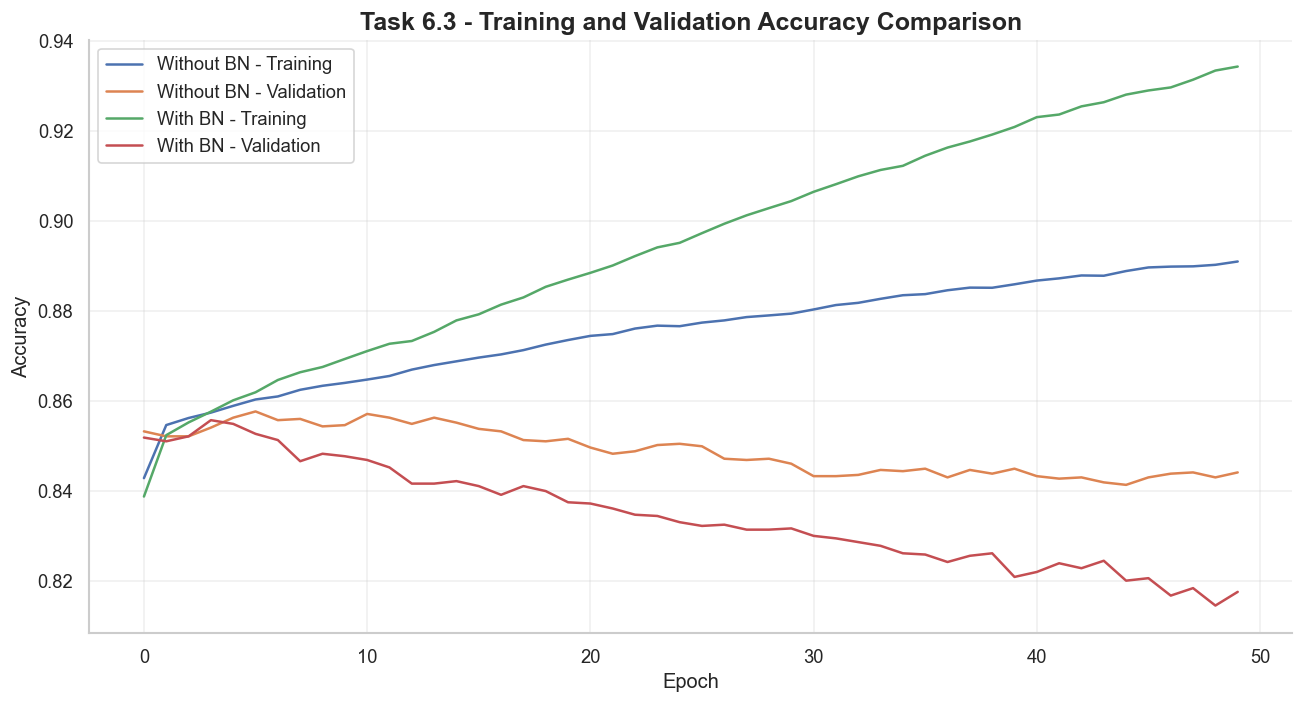

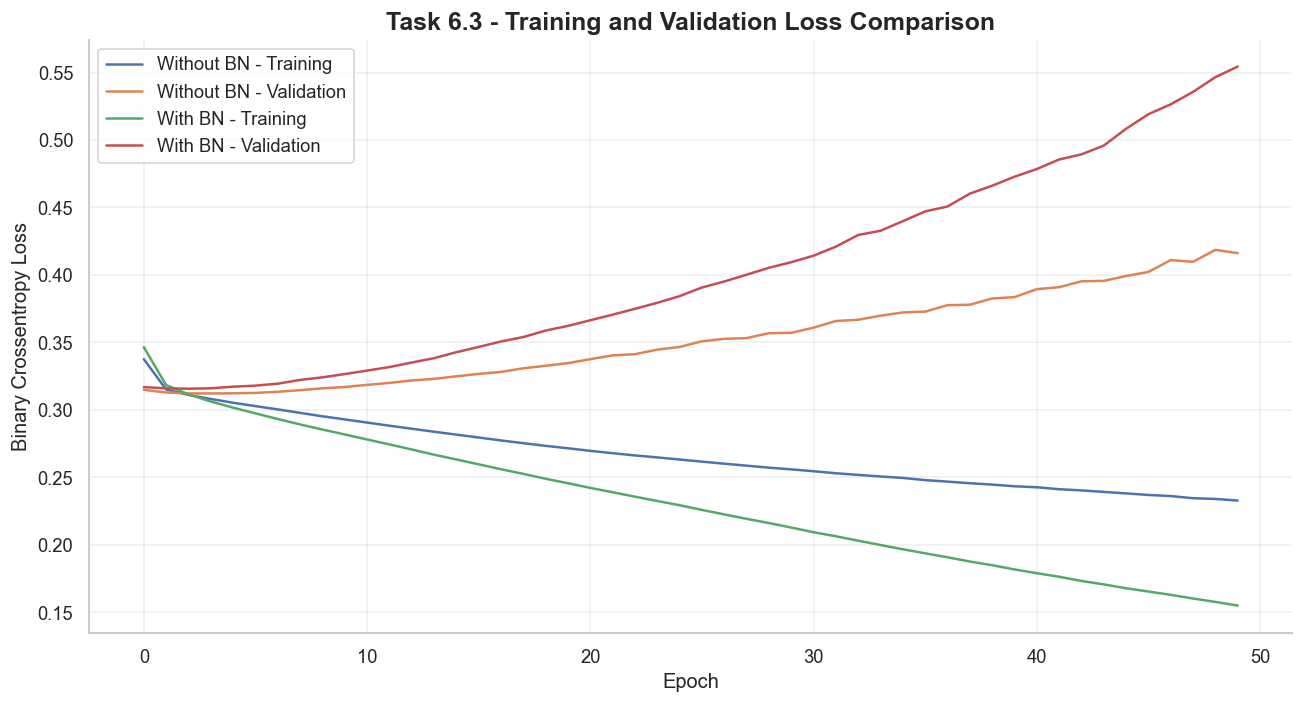

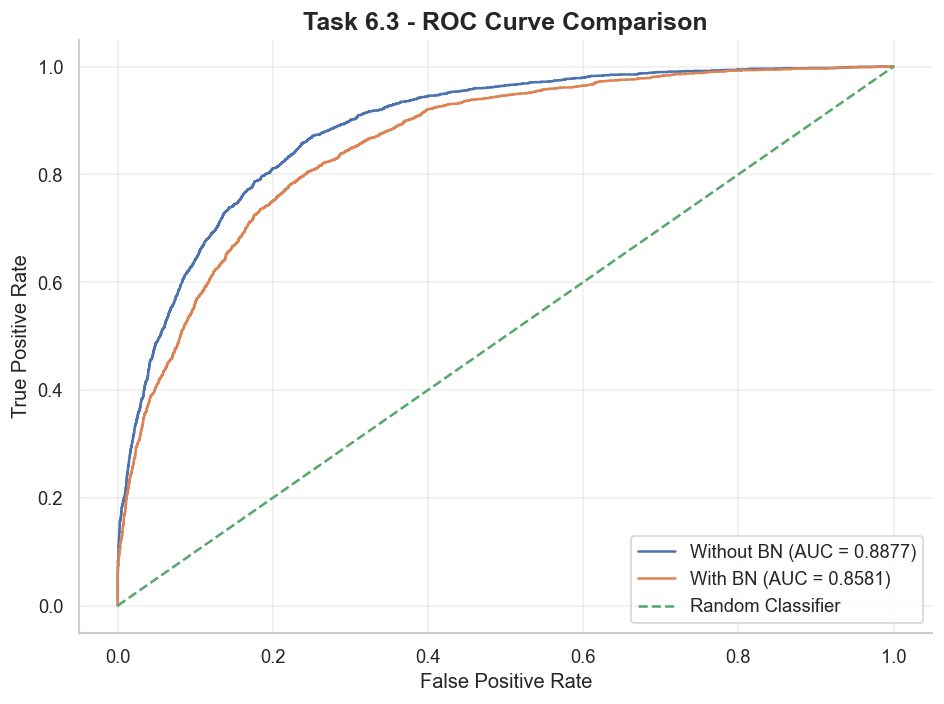

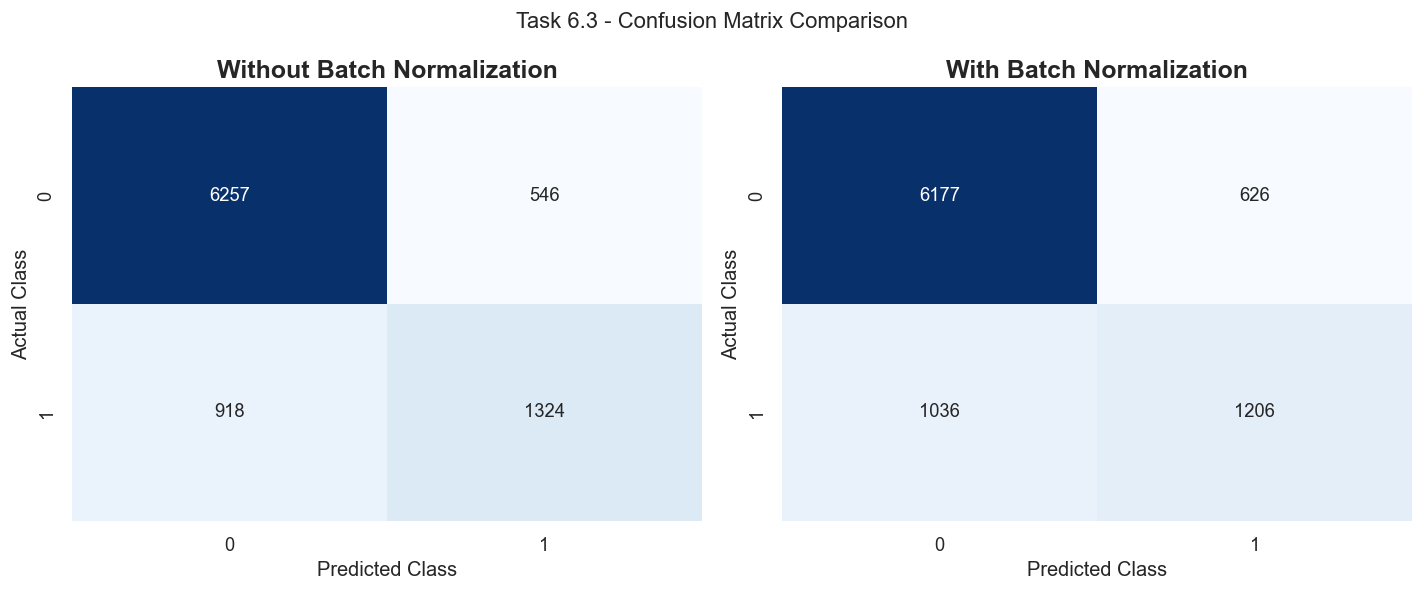


CLASSIFICATION REPORT - WITHOUT BATCH NORMALIZATION
----------------------------------------------------------------------
              precision    recall  f1-score   support

       <=50K       0.87      0.92      0.90      6803
        >50K       0.71      0.59      0.64      2242

    accuracy                           0.84      9045
   macro avg       0.79      0.76      0.77      9045
weighted avg       0.83      0.84      0.83      9045


CLASSIFICATION REPORT - WITH BATCH NORMALIZATION
----------------------------------------------------------------------
              precision    recall  f1-score   support

       <=50K       0.86      0.91      0.88      6803
        >50K       0.66      0.54      0.59      2242

    accuracy                           0.82      9045
   macro avg       0.76      0.72      0.74      9045
weighted avg       0.81      0.82      0.81      9045


TASK 6.4: COMPARISON OF BATCH NORMALIZATION PLACEMENT

Training Model: Dense -> ReLU -> Batch Normal

,Architecture,Validation_Accuracy,Validation_Precision,Validation_Recall,Validation_F1,Validation_ROC_AUC,Final_Validation_Loss
0,Dense -> ReLU -> Batch Normalization,0.8347,0.6862,0.6143,0.6482,0.8820,0.3848
1,Dense -> Batch Normalization -> ReLU,0.8375,0.6833,0.6421,0.6621,0.8912,0.3622


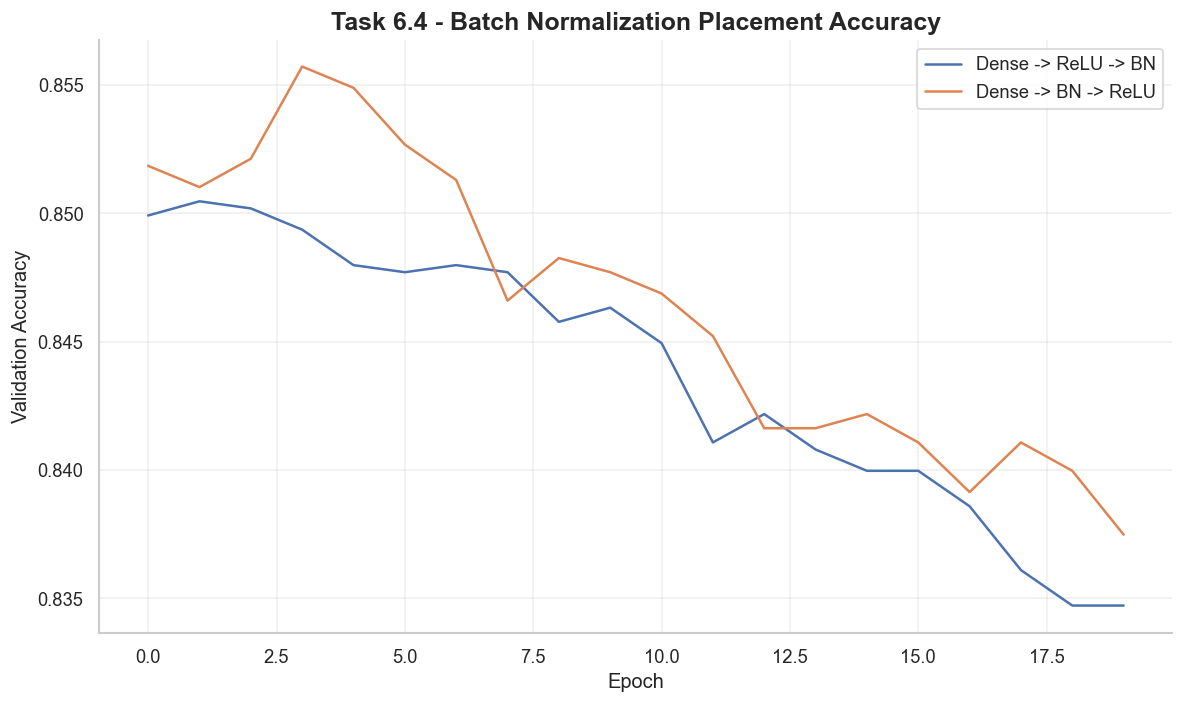

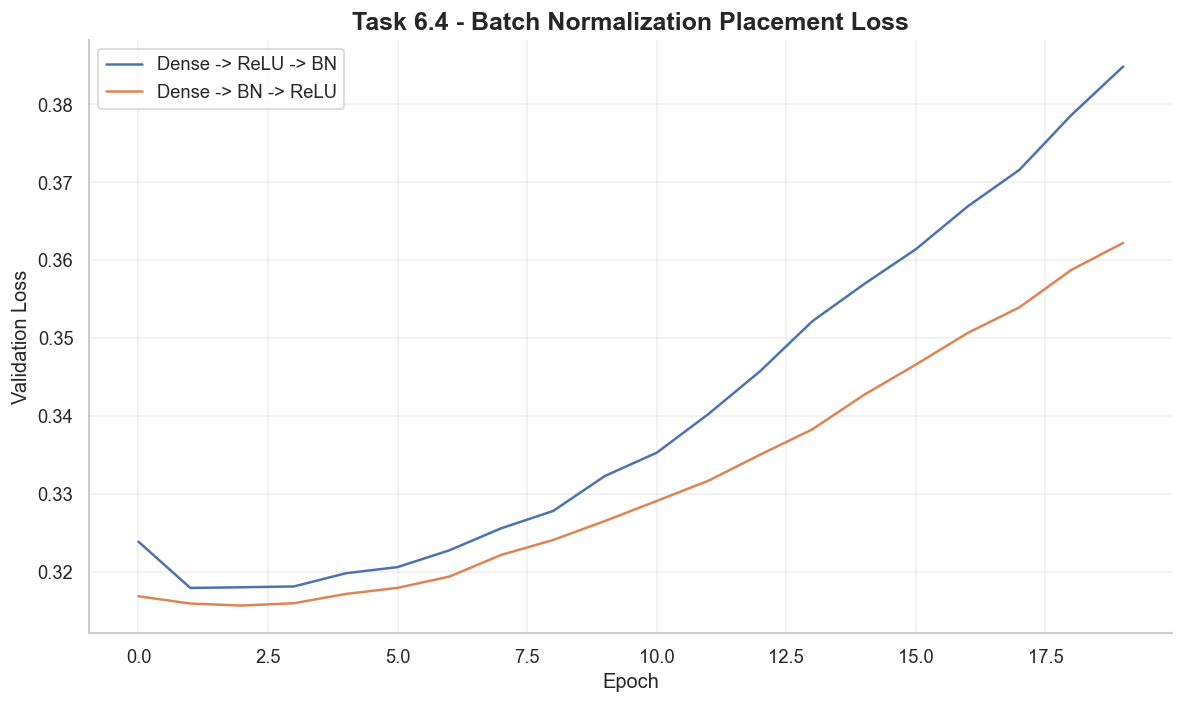


TASK 6.5: GAMMA AND BETA PARAMETER ANALYSIS

FIRST BATCH NORMALIZATION LAYER PARAMETERS
------------------------------------------------------------------------------------------
Number of Neurons          : 128
Gamma Parameter Count     : 128
Beta Parameter Count      : 128
Near-Zero Gamma Threshold : 0.01
Near-Zero Gamma Neurons   : 0

Near-Zero Gamma Neuron Indices (1-based):
No near-zero Gamma values identified.


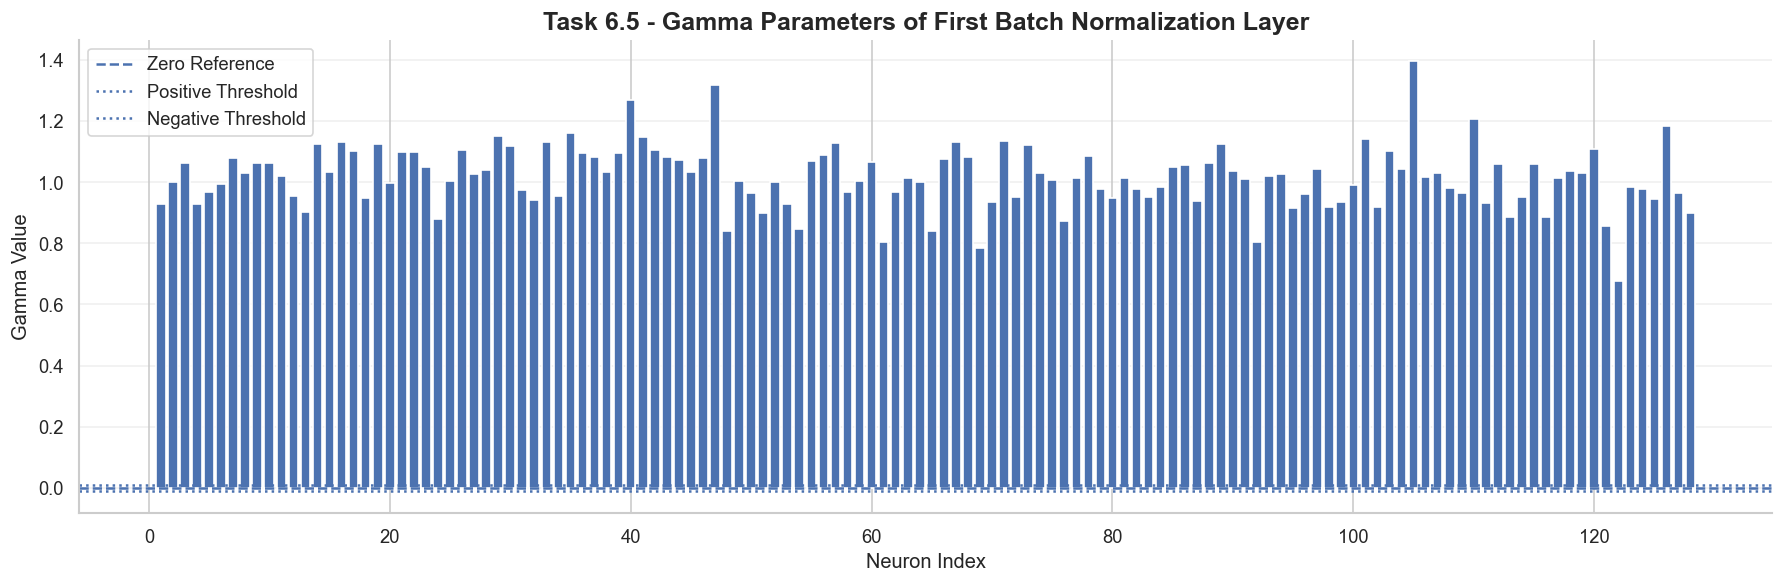

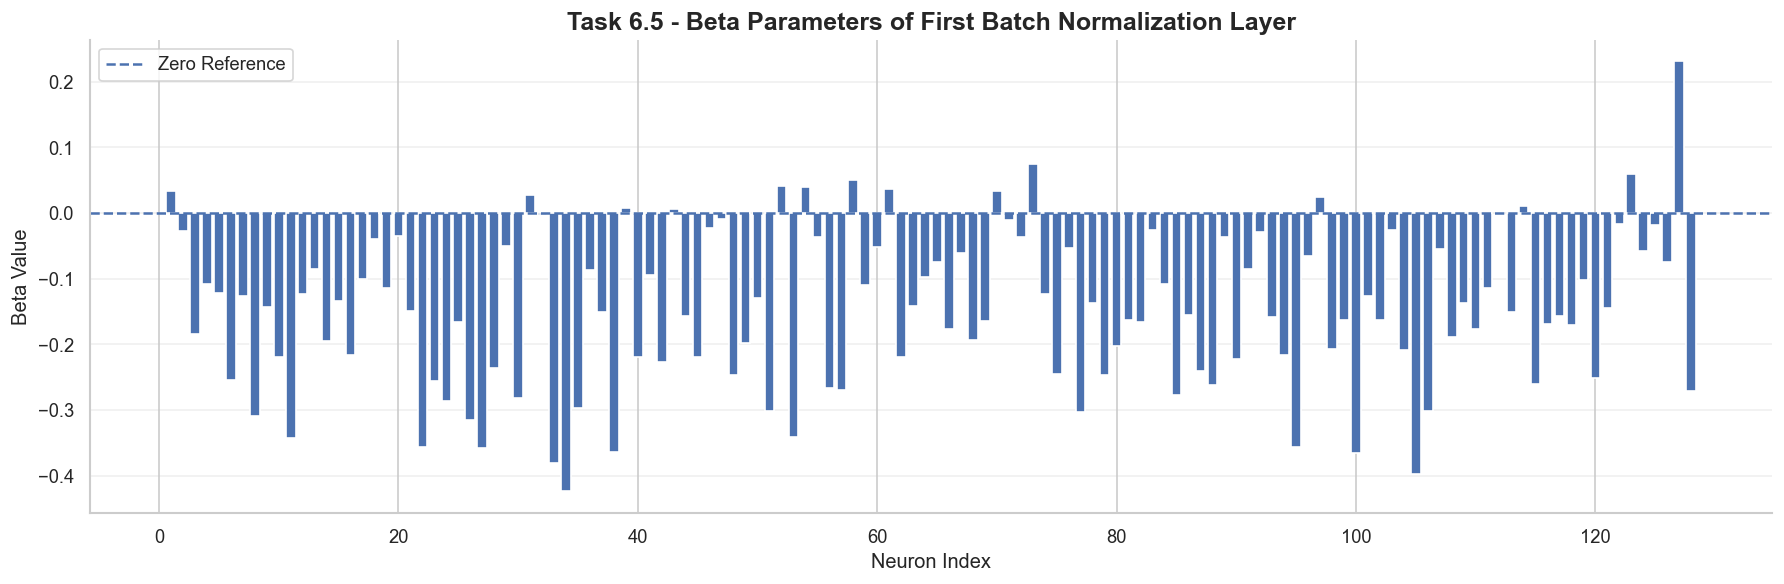


BATCH NORMALIZATION PARAMETER STATISTICS
------------------------------------------------------------------------------------------


,Parameter,Mean,Standard Deviation,Minimum,Maximum
0,Gamma,1.01756,0.10176,0.67625,1.39588
1,Beta,-0.14687,0.11997,-0.42343,0.23118
2,Moving Mean,-0.04647,0.36884,-0.78981,0.86059
3,Moving Variance,0.36635,0.21061,0.15679,2.21660



TASK 6: EXPERIMENTAL RESULTS AND FILE EXPORT

FINAL PERFORMANCE SUMMARY
------------------------------------------------------------------------------------------
Test Accuracy Difference : -0.0219
Class-1 F1 Difference    : -0.0519
Batch Normalization reduced the Class-1 F1-score.
Batch Normalization reduced test accuracy.

GENERATED FILE VERIFICATION
------------------------------------------------------------------------------------------
SUCCESS : task6_batchnorm_performance.csv
SUCCESS : task6_batchnorm_training_history.csv
SUCCESS : task6_batchnorm_placement.csv
SUCCESS : task6_batchnorm_parameters.csv
SUCCESS : task6_batchnorm_parameter_summary.csv
SUCCESS : task6_model_without_batchnorm.keras
SUCCESS : task6_model_with_batchnorm.keras
SUCCESS : 21_batchnorm_accuracy_comparison.png
SUCCESS : 22_batchnorm_loss_comparison.png
SUCCESS : 23_batchnorm_roc_comparison.png
SUCCESS : 24_batchnorm_confusion_matrices.png
SUCCESS : 25_batchnorm_placement_accuracy.png
SUCCESS : 26_batchnorm

In [22]:
# =============================================================================
# DEEP LEARNING - PRACTICAL 02
# PROJECT: ADULT INCOME PREDICTION USING ARTIFICIAL NEURAL NETWORKS
# TASK 6: BATCH NORMALIZATION
# SECTIONS: 6.1 TO 6.5
# =============================================================================


# =============================================================================
# TASK 6.1: DATASET VALIDATION AND ANN ARCHITECTURE CONFIGURATION
# =============================================================================

print("\n" + "=" * 90)
print("TASK 6.1: DATASET VALIDATION AND ANN ARCHITECTURE CONFIGURATION")
print("=" * 90)

# Validate the existing training, validation, and testing datasets.
required_variables = [
    "X_train_exp", "X_val_exp", "y_train_exp", "y_val_exp",
    "X_test", "y_test", "SEED", "PLOTS_DIR", "DATA_DIR"
]

missing_variables = [
    variable for variable in required_variables
    if variable not in globals()
]

assert not missing_variables, (
    f"Required variables are missing: {missing_variables}"
)

# Convert data into consistent NumPy formats.
X_train_bn = np.asarray(X_train_exp, dtype=np.float32)
X_val_bn = np.asarray(X_val_exp, dtype=np.float32)
X_test_bn = np.asarray(X_test, dtype=np.float32)

y_train_bn = np.asarray(y_train_exp, dtype=np.float32).reshape(-1, 1)
y_val_bn = np.asarray(y_val_exp, dtype=np.float32).reshape(-1, 1)
y_test_bn = np.asarray(y_test, dtype=np.float32).reshape(-1, 1)

# Validate dimensions and data integrity.
assert X_train_bn.ndim == 2
assert X_val_bn.ndim == 2
assert X_test_bn.ndim == 2

assert X_train_bn.shape[1] == X_val_bn.shape[1] == X_test_bn.shape[1]

assert len(X_train_bn) == len(y_train_bn)
assert len(X_val_bn) == len(y_val_bn)
assert len(X_test_bn) == len(y_test_bn)

assert np.isfinite(X_train_bn).all()
assert np.isfinite(X_val_bn).all()
assert np.isfinite(X_test_bn).all()

assert set(np.unique(y_train_bn)).issubset({0.0, 1.0})
assert set(np.unique(y_val_bn)).issubset({0.0, 1.0})
assert set(np.unique(y_test_bn)).issubset({0.0, 1.0})

# Model configuration.
INPUT_DIM = X_train_bn.shape[1]
HIDDEN_UNITS_BN = [128, 64]
BN_ACTIVATION = "relu"
BN_INITIALIZER = "he_uniform"

BN_LEARNING_RATE = 0.001
BN_BATCH_SIZE = 64
BN_MAIN_EPOCHS = 50
BN_PLACEMENT_EPOCHS = 20

BN_NEAR_ZERO_THRESHOLD = 0.01

print(f"\nTraining Samples       : {len(X_train_bn):,}")
print(f"Validation Samples     : {len(X_val_bn):,}")
print(f"Testing Samples        : {len(X_test_bn):,}")
print(f"Input Features         : {INPUT_DIM}")
print(f"Hidden Layer Structure : {HIDDEN_UNITS_BN}")
print(f"Activation Function    : {BN_ACTIVATION}")
print(f"Weight Initializer     : {BN_INITIALIZER}")
print(f"Learning Rate          : {BN_LEARNING_RATE}")
print(f"Batch Size             : {BN_BATCH_SIZE}")

print("\nDataset validation completed successfully.")


# =============================================================================
# TASK 6.1: REUSABLE ANN MODEL BUILDER WITH BATCH NORMALIZATION
# =============================================================================

print("\n" + "=" * 90)
print("TASK 6.1: REUSABLE ANN MODEL BUILDER")
print("=" * 90)


def build_batchnorm_ann(
    input_dim,
    hidden_units,
    activation,
    initializer,
    use_batch_norm,
    bn_position="before_activation"
):
    """
    Build a configurable ANN for binary income classification.

    Supported architectures:

    1. Without Batch Normalization:
       Dense -> ReLU

    2. Batch Normalization before activation:
       Dense -> BatchNormalization -> ReLU

    3. Batch Normalization after activation:
       Dense -> ReLU -> BatchNormalization

    The same architecture, optimizer, and loss are used
    across experiments to maintain controlled comparisons.
    """

    model = Sequential(name="Adult_Income_BatchNorm_ANN")

    model.add(Input(shape=(input_dim,)))

    for layer_index, units in enumerate(hidden_units):

        # Dense bias is unnecessary when Batch Normalization
        # immediately follows the Dense layer.
        disable_bias = (
            use_batch_norm and bn_position == "before_activation"
        )

        model.add(
            Dense(
                units,
                kernel_initializer=initializer,
                use_bias=not disable_bias,
                name=f"dense_hidden_{layer_index + 1}"
            )
        )

        if use_batch_norm and bn_position == "before_activation":

            model.add(
                BatchNormalization(
                    momentum=0.99,
                    epsilon=0.001,
                    name=f"batch_norm_{layer_index + 1}"
                )
            )

            model.add(
                Activation(
                    activation,
                    name=f"activation_{layer_index + 1}"
                )
            )

        elif use_batch_norm and bn_position == "after_activation":

            model.add(
                Activation(
                    activation,
                    name=f"activation_{layer_index + 1}"
                )
            )

            model.add(
                BatchNormalization(
                    momentum=0.99,
                    epsilon=0.001,
                    name=f"batch_norm_{layer_index + 1}"
                )
            )

        else:

            model.add(
                Activation(
                    activation,
                    name=f"activation_{layer_index + 1}"
                )
            )

    # Binary classification output.
    model.add(
        Dense(
            1,
            activation="sigmoid",
            kernel_initializer="glorot_uniform",
            name="income_prediction"
        )
    )

    model.compile(
        optimizer=Adam(learning_rate=BN_LEARNING_RATE),
        loss=BinaryCrossentropy(),
        metrics=[
            "accuracy",
            Precision(name="precision"),
            Recall(name="recall")
        ]
    )

    return model


print("Reusable Batch Normalization ANN builder created successfully.")


# =============================================================================
# TASK 6.2: BATCH NORMALIZATION EXPERIMENTAL CONCEPTS
# =============================================================================

print("\n" + "=" * 90)
print("TASK 6.2: UNDERSTANDING BATCH NORMALIZATION")
print("=" * 90)

print("""
1. INTERNAL COVARIATE SHIFT
   During neural network training, the distribution of activations
   can change as the parameters of previous layers are updated.

2. BATCH MEAN AND VARIANCE
   Batch Normalization calculates the mean and variance of activations
   within the current mini-batch.

3. NORMALIZATION
   The activations are normalized using:

       x_normalized = (x - batch_mean) / sqrt(batch_variance + epsilon)

4. LEARNABLE PARAMETERS
   Gamma (γ) controls scaling, while Beta (β) controls shifting:

       output = γ * x_normalized + β

5. TRAINING PHASE
   Current mini-batch statistics are used during training.
   Moving averages of mean and variance are also updated.

6. INFERENCE PHASE
   During prediction, the stored moving mean and moving variance
   are used instead of calculating statistics from the current batch.

7. TRAINING STABILITY
   Batch Normalization can improve optimization stability and may
   allow neural networks to converge more efficiently.

NOTE:
Batch Normalization does not guarantee better performance in every
dataset or architecture. Its effect must be evaluated experimentally.
""")

print("Batch Normalization concepts documented successfully.")


# =============================================================================
# TASK 6.3: COMPARE ANN WITH AND WITHOUT BATCH NORMALIZATION
# =============================================================================

print("\n" + "=" * 90)
print("TASK 6.3: PERFORMANCE COMPARISON - WITH VS WITHOUT BATCH NORMALIZATION")
print("=" * 90)


def train_batchnorm_experiment(
    model_name,
    use_batch_norm,
    epochs,
    bn_position="before_activation"
):

    # Reproducibility.
    random.seed(SEED)
    np.random.seed(SEED)
    tf.random.set_seed(SEED)

    model = build_batchnorm_ann(
        input_dim=INPUT_DIM,
        hidden_units=HIDDEN_UNITS_BN,
        activation=BN_ACTIVATION,
        initializer=BN_INITIALIZER,
        use_batch_norm=use_batch_norm,
        bn_position=bn_position
    )

    print(f"\nTraining Model: {model_name}")
    print("-" * 70)

    history = model.fit(
        X_train_bn,
        y_train_bn,
        validation_data=(X_val_bn, y_val_bn),
        epochs=epochs,
        batch_size=BN_BATCH_SIZE,
        shuffle=True,
        verbose=1
    )

    return model, history


# Model 1: ANN without Batch Normalization.
model_without_bn, history_without_bn = train_batchnorm_experiment(
    model_name="ANN Without Batch Normalization",
    use_batch_norm=False,
    epochs=BN_MAIN_EPOCHS
)

# Model 2: ANN with Batch Normalization.
model_with_bn, history_with_bn = train_batchnorm_experiment(
    model_name="ANN With Batch Normalization",
    use_batch_norm=True,
    epochs=BN_MAIN_EPOCHS,
    bn_position="before_activation"
)


# -----------------------------------------------------------------------------
# MODEL EVALUATION
# -----------------------------------------------------------------------------

def evaluate_bn_model(model, model_name):

    probabilities = model.predict(
        X_test_bn,
        batch_size=BN_BATCH_SIZE,
        verbose=0
    ).reshape(-1)

    predictions = (probabilities >= 0.5).astype(int)

    accuracy = accuracy_score(y_test_bn.reshape(-1), predictions)

    precision_value = precision_score(
        y_test_bn.reshape(-1),
        predictions,
        zero_division=0
    )

    recall_value = recall_score(
        y_test_bn.reshape(-1),
        predictions,
        zero_division=0
    )

    f1_value = f1_score(
        y_test_bn.reshape(-1),
        predictions,
        zero_division=0
    )

    auc_value = roc_auc_score(
        y_test_bn.reshape(-1),
        probabilities
    )

    return {
        "Model": model_name,
        "Test_Accuracy": accuracy,
        "Test_Precision": precision_value,
        "Test_Recall": recall_value,
        "Class_1_F1": f1_value,
        "Test_ROC_AUC": auc_value
    }


performance_without_bn = evaluate_bn_model(
    model_without_bn,
    "Without Batch Normalization"
)

performance_with_bn = evaluate_bn_model(
    model_with_bn,
    "With Batch Normalization"
)

performance_df = pd.DataFrame([
    performance_without_bn,
    performance_with_bn
])

print("\nTEST PERFORMANCE COMPARISON")
print("-" * 90)
display(performance_df.round(4))


# -----------------------------------------------------------------------------
# TRAINING HISTORY COMPARISON
# -----------------------------------------------------------------------------

history_comparison = pd.DataFrame({
    "Epoch": range(1, BN_MAIN_EPOCHS + 1),

    "Without_BN_Training_Accuracy":
        history_without_bn.history["accuracy"],

    "Without_BN_Validation_Accuracy":
        history_without_bn.history["val_accuracy"],

    "With_BN_Training_Accuracy":
        history_with_bn.history["accuracy"],

    "With_BN_Validation_Accuracy":
        history_with_bn.history["val_accuracy"],

    "Without_BN_Training_Loss":
        history_without_bn.history["loss"],

    "Without_BN_Validation_Loss":
        history_without_bn.history["val_loss"],

    "With_BN_Training_Loss":
        history_with_bn.history["loss"],

    "With_BN_Validation_Loss":
        history_with_bn.history["val_loss"]
})

display(history_comparison.head())


# -----------------------------------------------------------------------------
# ACCURACY VISUALIZATION
# -----------------------------------------------------------------------------

plt.figure(figsize=(11, 6))

plt.plot(
    history_without_bn.history["accuracy"],
    label="Without BN - Training"
)

plt.plot(
    history_without_bn.history["val_accuracy"],
    label="Without BN - Validation"
)

plt.plot(
    history_with_bn.history["accuracy"],
    label="With BN - Training"
)

plt.plot(
    history_with_bn.history["val_accuracy"],
    label="With BN - Validation"
)

plt.title("Task 6.3 - Training and Validation Accuracy Comparison")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "21_batchnorm_accuracy_comparison.png", dpi=300)
plt.show()


# -----------------------------------------------------------------------------
# LOSS VISUALIZATION
# -----------------------------------------------------------------------------

plt.figure(figsize=(11, 6))

plt.plot(
    history_without_bn.history["loss"],
    label="Without BN - Training"
)

plt.plot(
    history_without_bn.history["val_loss"],
    label="Without BN - Validation"
)

plt.plot(
    history_with_bn.history["loss"],
    label="With BN - Training"
)

plt.plot(
    history_with_bn.history["val_loss"],
    label="With BN - Validation"
)

plt.title("Task 6.3 - Training and Validation Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Binary Crossentropy Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "22_batchnorm_loss_comparison.png", dpi=300)
plt.show()


# -----------------------------------------------------------------------------
# ROC CURVE COMPARISON
# -----------------------------------------------------------------------------

y_test_flat = y_test_bn.reshape(-1)

prob_without_bn = model_without_bn.predict(
    X_test_bn, verbose=0
).reshape(-1)

prob_with_bn = model_with_bn.predict(
    X_test_bn, verbose=0
).reshape(-1)

fpr_without, tpr_without, _ = roc_curve(
    y_test_flat, prob_without_bn
)

fpr_with, tpr_with, _ = roc_curve(
    y_test_flat, prob_with_bn
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_without,
    tpr_without,
    label=f"Without BN (AUC = {roc_auc_score(y_test_flat, prob_without_bn):.4f})"
)

plt.plot(
    fpr_with,
    tpr_with,
    label=f"With BN (AUC = {roc_auc_score(y_test_flat, prob_with_bn):.4f})"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.title("Task 6.3 - ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "23_batchnorm_roc_comparison.png", dpi=300)
plt.show()


# -----------------------------------------------------------------------------
# CONFUSION MATRIX COMPARISON
# -----------------------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for axis, model_name, probabilities in [
    (axes[0], "Without Batch Normalization", prob_without_bn),
    (axes[1], "With Batch Normalization", prob_with_bn)
]:

    predicted_labels = (probabilities >= 0.5).astype(int)

    matrix = confusion_matrix(
        y_test_flat,
        predicted_labels
    )

    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        ax=axis
    )

    axis.set_title(model_name)
    axis.set_xlabel("Predicted Class")
    axis.set_ylabel("Actual Class")

plt.suptitle("Task 6.3 - Confusion Matrix Comparison")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "24_batchnorm_confusion_matrices.png", dpi=300)
plt.show()


# -----------------------------------------------------------------------------
# CLASSIFICATION REPORTS
# -----------------------------------------------------------------------------

print("\nCLASSIFICATION REPORT - WITHOUT BATCH NORMALIZATION")
print("-" * 70)

print(
    classification_report(
        y_test_flat,
        (prob_without_bn >= 0.5).astype(int),
        target_names=["<=50K", ">50K"],
        zero_division=0
    )
)

print("\nCLASSIFICATION REPORT - WITH BATCH NORMALIZATION")
print("-" * 70)

print(
    classification_report(
        y_test_flat,
        (prob_with_bn >= 0.5).astype(int),
        target_names=["<=50K", ">50K"],
        zero_division=0
    )
)


# =============================================================================
# TASK 6.4: COMPARISON OF BATCH NORMALIZATION PLACEMENT
# =============================================================================

print("\n" + "=" * 90)
print("TASK 6.4: COMPARISON OF BATCH NORMALIZATION PLACEMENT")
print("=" * 90)

# Architecture A: Dense -> ReLU -> Batch Normalization.
model_bn_after_activation, history_bn_after_activation = (
    train_batchnorm_experiment(
        model_name="Dense -> ReLU -> Batch Normalization",
        use_batch_norm=True,
        epochs=BN_PLACEMENT_EPOCHS,
        bn_position="after_activation"
    )
)

# Architecture B: Dense -> Batch Normalization -> ReLU.
model_bn_before_activation, history_bn_before_activation = (
    train_batchnorm_experiment(
        model_name="Dense -> Batch Normalization -> ReLU",
        use_batch_norm=True,
        epochs=BN_PLACEMENT_EPOCHS,
        bn_position="before_activation"
    )
)


# Evaluate placement variants using validation data only.
def evaluate_validation_model(model, model_name):

    probabilities = model.predict(
        X_val_bn,
        batch_size=BN_BATCH_SIZE,
        verbose=0
    ).reshape(-1)

    predictions = (probabilities >= 0.5).astype(int)

    return {
        "Architecture": model_name,

        "Validation_Accuracy": accuracy_score(
            y_val_bn.reshape(-1), predictions
        ),

        "Validation_Precision": precision_score(
            y_val_bn.reshape(-1), predictions, zero_division=0
        ),

        "Validation_Recall": recall_score(
            y_val_bn.reshape(-1), predictions, zero_division=0
        ),

        "Validation_F1": f1_score(
            y_val_bn.reshape(-1), predictions, zero_division=0
        ),

        "Validation_ROC_AUC": roc_auc_score(
            y_val_bn.reshape(-1), probabilities
        ),

        "Final_Training_Loss": model.history.history["loss"][-1]
        if hasattr(model, "history") else np.nan
    }


placement_results = []

for architecture_name, model in [
    ("Dense -> ReLU -> Batch Normalization", model_bn_after_activation),
    ("Dense -> Batch Normalization -> ReLU", model_bn_before_activation)
]:

    result = evaluate_validation_model(model, architecture_name)

    # Record the final validation loss directly from its training history.
    if architecture_name == "Dense -> ReLU -> Batch Normalization":
        result["Final_Validation_Loss"] = (
            history_bn_after_activation.history["val_loss"][-1]
        )
    else:
        result["Final_Validation_Loss"] = (
            history_bn_before_activation.history["val_loss"][-1]
        )

    placement_results.append(result)


placement_df = pd.DataFrame(placement_results)

print("\nBATCH NORMALIZATION PLACEMENT COMPARISON")
print("-" * 90)

display(
    placement_df.drop(columns=["Final_Training_Loss"]).round(4)
)


# -----------------------------------------------------------------------------
# PLACEMENT ACCURACY COMPARISON
# -----------------------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    history_bn_after_activation.history["val_accuracy"],
    label="Dense -> ReLU -> BN"
)

plt.plot(
    history_bn_before_activation.history["val_accuracy"],
    label="Dense -> BN -> ReLU"
)

plt.title("Task 6.4 - Batch Normalization Placement Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "25_batchnorm_placement_accuracy.png", dpi=300)
plt.show()


# -----------------------------------------------------------------------------
# PLACEMENT LOSS COMPARISON
# -----------------------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    history_bn_after_activation.history["val_loss"],
    label="Dense -> ReLU -> BN"
)

plt.plot(
    history_bn_before_activation.history["val_loss"],
    label="Dense -> BN -> ReLU"
)

plt.title("Task 6.4 - Batch Normalization Placement Loss")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "26_batchnorm_placement_loss.png", dpi=300)
plt.show()


# =============================================================================
# TASK 6.5: GAMMA AND BETA PARAMETER ANALYSIS
# =============================================================================

print("\n" + "=" * 90)
print("TASK 6.5: GAMMA AND BETA PARAMETER ANALYSIS")
print("=" * 90)

# Extract the first Batch Normalization layer.
first_bn_layer = model_with_bn.get_layer("batch_norm_1")

gamma_values = first_bn_layer.gamma.numpy()
beta_values = first_bn_layer.beta.numpy()

moving_mean_values = first_bn_layer.moving_mean.numpy()
moving_variance_values = first_bn_layer.moving_variance.numpy()

# Verify extracted parameter dimensions.
assert len(gamma_values) == HIDDEN_UNITS_BN[0]
assert len(beta_values) == HIDDEN_UNITS_BN[0]

assert np.isfinite(gamma_values).all()
assert np.isfinite(beta_values).all()

# Identify near-zero gamma values.
near_zero_indices = np.where(
    np.abs(gamma_values) < BN_NEAR_ZERO_THRESHOLD
)[0]

parameter_df = pd.DataFrame({
    "Neuron": np.arange(1, len(gamma_values) + 1),
    "Gamma": gamma_values,
    "Beta": beta_values,
    "Moving_Mean": moving_mean_values,
    "Moving_Variance": moving_variance_values,
    "Near_Zero_Gamma": np.abs(gamma_values) < BN_NEAR_ZERO_THRESHOLD
})

print("\nFIRST BATCH NORMALIZATION LAYER PARAMETERS")
print("-" * 90)

print(f"Number of Neurons          : {len(gamma_values)}")
print(f"Gamma Parameter Count     : {len(gamma_values)}")
print(f"Beta Parameter Count      : {len(beta_values)}")
print(f"Near-Zero Gamma Threshold : {BN_NEAR_ZERO_THRESHOLD}")
print(f"Near-Zero Gamma Neurons   : {len(near_zero_indices)}")

print("\nNear-Zero Gamma Neuron Indices (1-based):")

if len(near_zero_indices) > 0:
    print((near_zero_indices + 1).tolist())
else:
    print("No near-zero Gamma values identified.")


# -----------------------------------------------------------------------------
# GAMMA VISUALIZATION
# -----------------------------------------------------------------------------

plt.figure(figsize=(15, 5))

plt.bar(
    np.arange(1, len(gamma_values) + 1),
    gamma_values
)

plt.axhline(
    0,
    linestyle="--",
    label="Zero Reference"
)

plt.axhline(
    BN_NEAR_ZERO_THRESHOLD,
    linestyle=":",
    label="Positive Threshold"
)

plt.axhline(
    -BN_NEAR_ZERO_THRESHOLD,
    linestyle=":",
    label="Negative Threshold"
)

plt.title("Task 6.5 - Gamma Parameters of First Batch Normalization Layer")
plt.xlabel("Neuron Index")
plt.ylabel("Gamma Value")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "27_batchnorm_gamma_analysis.png", dpi=300)
plt.show()


# -----------------------------------------------------------------------------
# BETA VISUALIZATION
# -----------------------------------------------------------------------------

plt.figure(figsize=(15, 5))

plt.bar(
    np.arange(1, len(beta_values) + 1),
    beta_values
)

plt.axhline(
    0,
    linestyle="--",
    label="Zero Reference"
)

plt.title("Task 6.5 - Beta Parameters of First Batch Normalization Layer")
plt.xlabel("Neuron Index")
plt.ylabel("Beta Value")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "28_batchnorm_beta_analysis.png", dpi=300)
plt.show()


# -----------------------------------------------------------------------------
# GAMMA AND BETA SUMMARY STATISTICS
# -----------------------------------------------------------------------------

parameter_summary = pd.DataFrame({
    "Parameter": [
        "Gamma",
        "Beta",
        "Moving Mean",
        "Moving Variance"
    ],

    "Mean": [
        np.mean(gamma_values),
        np.mean(beta_values),
        np.mean(moving_mean_values),
        np.mean(moving_variance_values)
    ],

    "Standard Deviation": [
        np.std(gamma_values),
        np.std(beta_values),
        np.std(moving_mean_values),
        np.std(moving_variance_values)
    ],

    "Minimum": [
        np.min(gamma_values),
        np.min(beta_values),
        np.min(moving_mean_values),
        np.min(moving_variance_values)
    ],

    "Maximum": [
        np.max(gamma_values),
        np.max(beta_values),
        np.max(moving_mean_values),
        np.max(moving_variance_values)
    ]
})

print("\nBATCH NORMALIZATION PARAMETER STATISTICS")
print("-" * 90)

display(parameter_summary.round(5))


# =============================================================================
# TASK 6: EXPERIMENTAL RESULTS AND FILE EXPORT
# =============================================================================

print("\n" + "=" * 90)
print("TASK 6: EXPERIMENTAL RESULTS AND FILE EXPORT")
print("=" * 90)

# Save performance comparison.
performance_df.to_csv(
    DATA_DIR / "task6_batchnorm_performance.csv",
    index=False
)

# Save training history.
history_comparison.to_csv(
    DATA_DIR / "task6_batchnorm_training_history.csv",
    index=False
)

# Save placement comparison.
placement_df.to_csv(
    DATA_DIR / "task6_batchnorm_placement.csv",
    index=False
)

# Save all Gamma, Beta, and moving statistics.
parameter_df.to_csv(
    DATA_DIR / "task6_batchnorm_parameters.csv",
    index=False
)

parameter_summary.to_csv(
    DATA_DIR / "task6_batchnorm_parameter_summary.csv",
    index=False
)

# Save trained models.
model_without_bn.save(
    DATA_DIR / "task6_model_without_batchnorm.keras"
)

model_with_bn.save(
    DATA_DIR / "task6_model_with_batchnorm.keras"
)


# -----------------------------------------------------------------------------
# FINAL PERFORMANCE INTERPRETATION
# -----------------------------------------------------------------------------

print("\nFINAL PERFORMANCE SUMMARY")
print("-" * 90)

accuracy_difference = (
    performance_with_bn["Test_Accuracy"]
    - performance_without_bn["Test_Accuracy"]
)

f1_difference = (
    performance_with_bn["Class_1_F1"]
    - performance_without_bn["Class_1_F1"]
)

print(f"Test Accuracy Difference : {accuracy_difference:+.4f}")
print(f"Class-1 F1 Difference    : {f1_difference:+.4f}")

if f1_difference > 0:
    print("Batch Normalization improved the Class-1 F1-score.")
elif f1_difference < 0:
    print("Batch Normalization reduced the Class-1 F1-score.")
else:
    print("Both models achieved the same Class-1 F1-score.")

if accuracy_difference > 0:
    print("Batch Normalization improved test accuracy.")
elif accuracy_difference < 0:
    print("Batch Normalization reduced test accuracy.")
else:
    print("Both models achieved the same test accuracy.")


# -----------------------------------------------------------------------------
# OUTPUT FILE VERIFICATION
# -----------------------------------------------------------------------------

expected_files = [
    "task6_batchnorm_performance.csv",
    "task6_batchnorm_training_history.csv",
    "task6_batchnorm_placement.csv",
    "task6_batchnorm_parameters.csv",
    "task6_batchnorm_parameter_summary.csv",
    "task6_model_without_batchnorm.keras",
    "task6_model_with_batchnorm.keras"
]

expected_plots = [
    "21_batchnorm_accuracy_comparison.png",
    "22_batchnorm_loss_comparison.png",
    "23_batchnorm_roc_comparison.png",
    "24_batchnorm_confusion_matrices.png",
    "25_batchnorm_placement_accuracy.png",
    "26_batchnorm_placement_loss.png",
    "27_batchnorm_gamma_analysis.png",
    "28_batchnorm_beta_analysis.png"
]

print("\nGENERATED FILE VERIFICATION")
print("-" * 90)

for filename in expected_files:
    file_path = DATA_DIR / filename
    print(f"{'SUCCESS' if file_path.exists() else 'MISSING'} : {filename}")

for filename in expected_plots:
    file_path = PLOTS_DIR / filename
    print(f"{'SUCCESS' if file_path.exists() else 'MISSING'} : {filename}")

print("\n" + "=" * 90)
print("TASK 6: BATCH NORMALIZATION EXPERIMENTS COMPLETED")
print("=" * 90)

# TASK 7: OPTIMIZERS – CONVERGENCE AND FINAL COMPARISON

## Objective

To compare different optimization algorithms, analyse their convergence behaviour, investigate learning-rate sensitivity and develop a final optimized Artificial Neural Network for Adult Income Prediction.

### Experiments

**7.1 – Optimizer Comparison:** Compare SGD, SGD with Momentum, RMSprop, Adam and Adam with AMSGrad.

**7.2 – Convergence Analysis:** Study training and validation accuracy and loss across epochs.

**7.3 – Adam Optimization Theory:** Explain momentum, adaptive learning rates, first and second moment estimates and bias correction.

**7.4 – Learning Rate Sensitivity:** Compare different learning rates for SGD and Adam.

**7.5 – Final ANN Model:** Combine the best-performing activation, initializer, loss function and optimizer configurations.

**7.6 – Final Performance Comparison:** Consolidate the recorded results from Tasks 2–7 and evaluate the final model.

### Evaluation Metrics

Accuracy, Precision, Recall, F1-score, ROC-AUC, training loss, validation loss and test performance.

### Experimental Precautions

- Use identical training and validation datasets for optimizer comparisons.
- Use validation performance for model selection.
- Keep the test dataset independent until final evaluation.
- Record actual experimental results.
- Do not assume that one optimizer will perform best on every dataset.


TASK 7: OPTIMIZERS - CONVERGENCE AND FINAL COMPARISON

DATASET CONFIGURATION
--------------------------------------------------------------------------------
Training samples   : 32559
Validation samples : 3618
Testing samples    : 9045
Input features     : 80
Training split and validation split verified.

TASK 7.1: COMPARISON OF DIFFERENT OPTIMIZERS

------------------------------------------------------------------------------------------
OPTIMIZER EXPERIMENT 1: SGD
------------------------------------------------------------------------------------------
Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7643 - loss: 0.5264 - precision: 0.5738 - recall: 0.1907 - val_accuracy: 0.7717 - val_loss: 0.4821 - val_precision: 0.8660 - val_recall: 0.0936
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7778 - loss: 0.4606 - precision: 0.8664 - recall: 0.1222 - val_accuracy: 0.7872 - val_loss: 0.4441 - val_precision: 0.8994 - val_recall: 0.1594
Epoch 3/50
509/

,Optimizer,Final_Training_Accuracy,Final_Validation_Accuracy,Best_Validation_Accuracy,Final_Training_Loss,Final_Validation_Loss,Minimum_Validation_Loss,Validation_Precision,Validation_Recall,Validation_F1,Validation_ROC_AUC,Best_Accuracy_Epoch,Best_Loss_Epoch,First_Epoch_80_Accuracy
0,SGD Momentum,0.8585,0.8549,0.8552,0.3067,0.3102,0.3102,0.7441,0.6321,0.6835,0.9141,39,50,1
1,SGD,0.8505,0.8494,0.8494,0.3234,0.3240,0.3240,0.7262,0.6299,0.6746,0.9055,50,50,3
2,RMSprop,0.8800,0.8444,0.8571,0.2645,0.3706,0.3138,0.7372,0.5786,0.6483,0.8964,10,3,1
3,Adam AMSGrad,0.8887,0.8413,0.8574,0.2332,0.3878,0.3125,0.7240,0.5819,0.6452,0.8933,8,4,1
4,Adam,0.8928,0.8391,0.8588,0.2298,0.4204,0.3116,0.7160,0.5819,0.6421,0.8903,8,5,1



Best optimizer based on validation F1: SGD Momentum

TASK 7.2: OPTIMIZER CONVERGENCE ANALYSIS


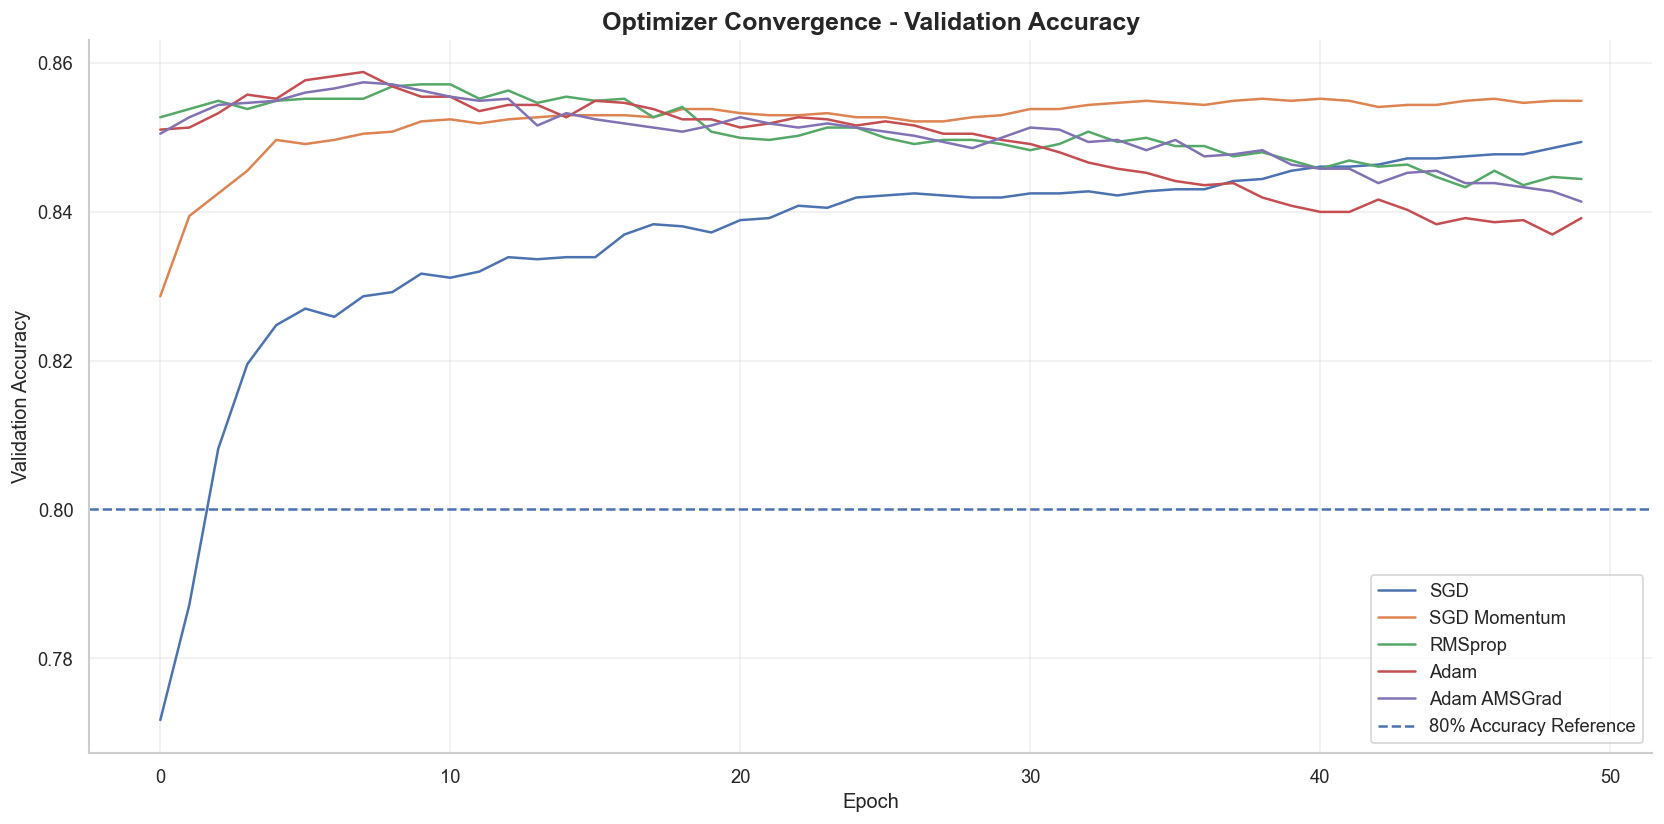

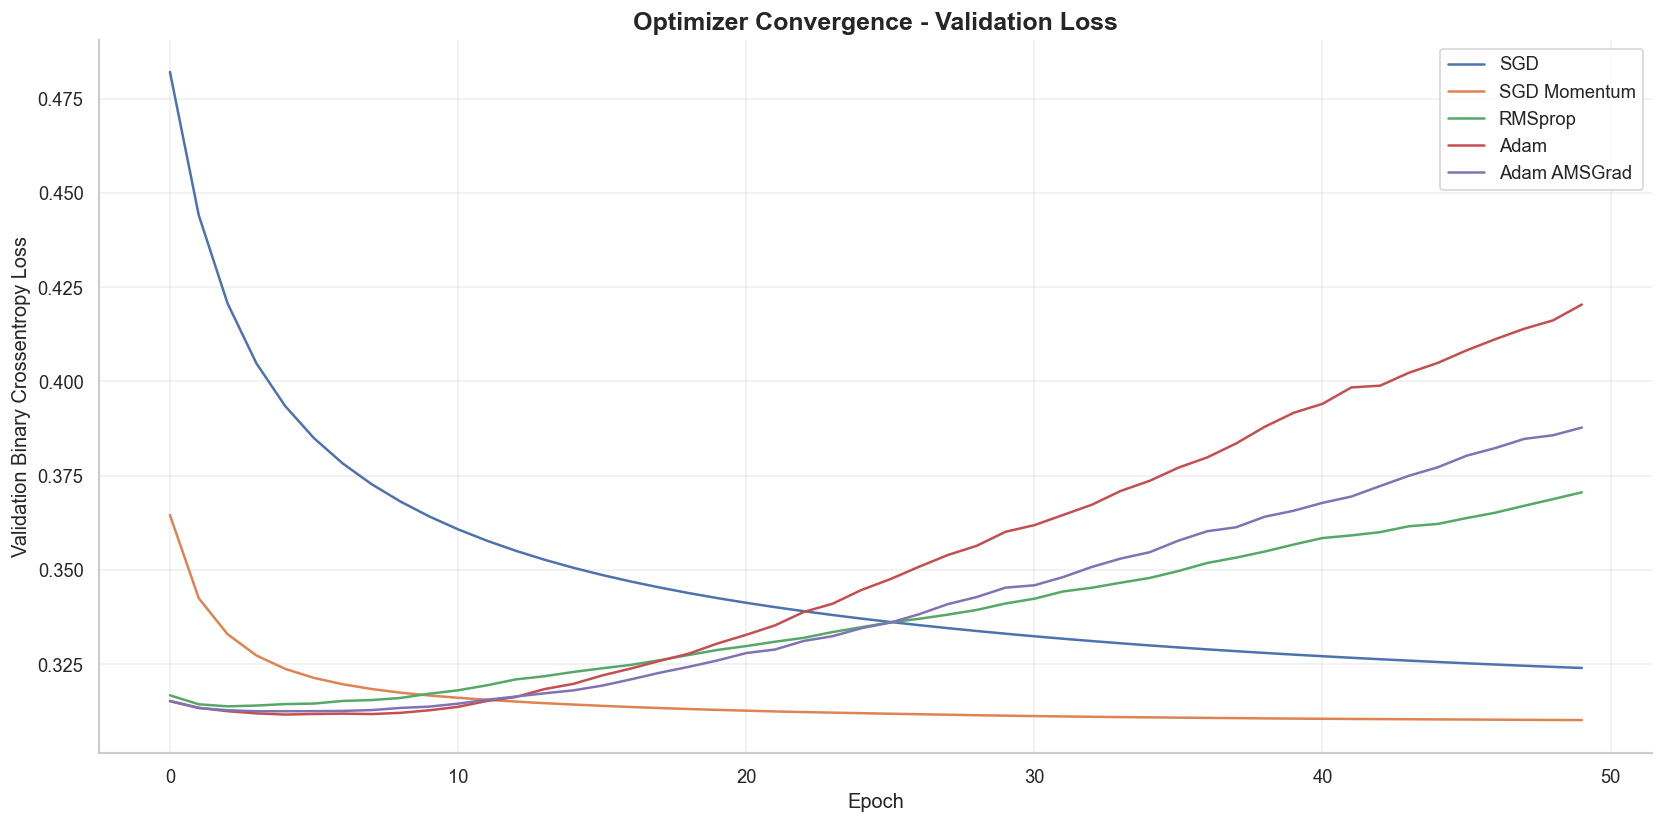


TASK 7.3: MATHEMATICAL UNDERSTANDING OF ADAM OPTIMIZER


1. STOCHASTIC GRADIENT DESCENT
   Updates model weights using the calculated gradient.

2. MOMENTUM
   Uses previous gradients to maintain an accumulated update direction.

3. FIRST MOMENT ESTIMATE
   m(t) = beta1 * m(t-1) + (1-beta1) * gradient

4. SECOND MOMENT ESTIMATE
   v(t) = beta2 * v(t-1) + (1-beta2) * gradient^2

5. BIAS CORRECTION
   Corrects the initialization bias in the moment estimates.

6. ADAPTIVE LEARNING RATE
   Adjusts the update magnitude according to the estimated
   first and second moments.

7. PARAMETER UPDATE
   theta(t+1) = theta(t) - learning_rate *
                corrected_first_moment /
                (sqrt(corrected_second_moment) + epsilon)

CONCLUSION:
Adam combines momentum and adaptive learning-rate mechanisms.
It often converges efficiently, but does not guarantee the
best validation or test generalization in every experiment.


TASK 7.4: LEARNING RATE SENSITIVITY ANALYSIS

Training: SGD_LR_0

,Optimizer,Learning_Rate,Final_Validation_Accuracy,Best_Validation_Accuracy,Final_Validation_Loss,Minimum_Validation_Loss,Validation_F1,Validation_ROC_AUC,Best_Loss_Epoch
0,SGD,0.0001,0.8093,0.8093,0.4208,0.4208,0.4453,0.8561,30
1,SGD,0.0010,0.8419,0.8425,0.3331,0.3331,0.6591,0.9001,30
2,SGD,0.0100,0.8535,0.8541,0.3115,0.3115,0.6736,0.9132,30
3,SGD,0.1000,0.8527,0.8546,0.3161,0.3127,0.6599,0.9129,14
4,Adam,0.0001,0.8535,0.8557,0.3116,0.3116,0.6815,0.9130,28
5,Adam,0.0010,0.8496,0.8588,0.3601,0.3116,0.6600,0.8985,5
6,Adam,0.0100,0.8400,0.8530,0.4072,0.3143,0.6243,0.8935,6


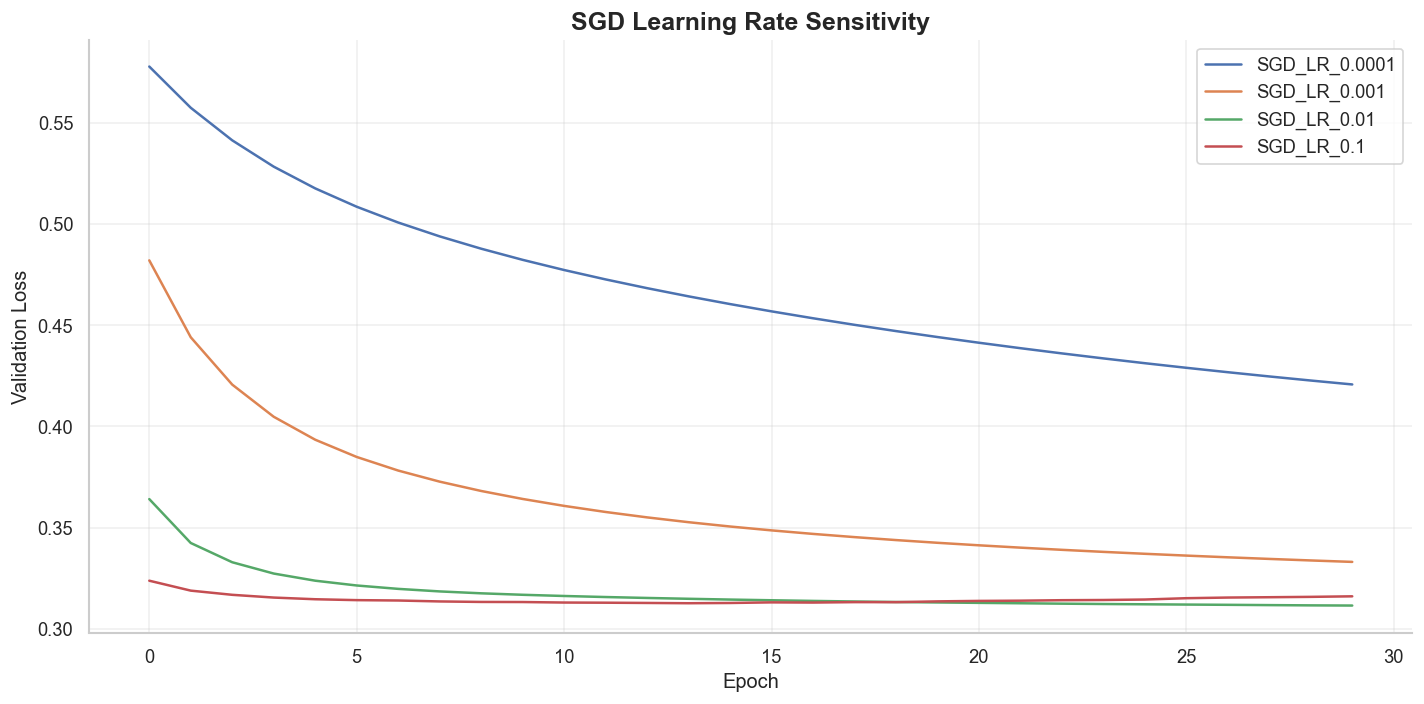

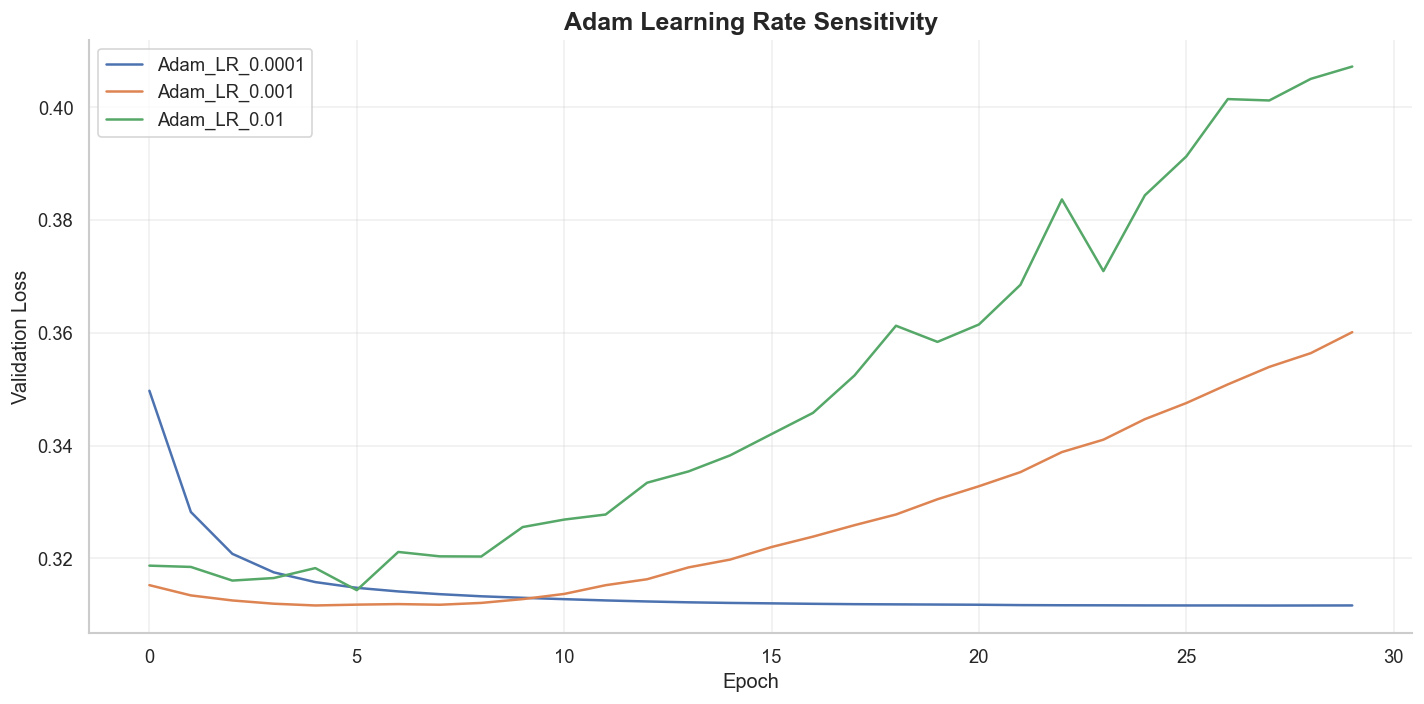


BEST LEARNING RATE CONFIGURATION


,Optimizer,Learning_Rate,Final_Validation_Accuracy,Best_Validation_Accuracy,Final_Validation_Loss,Minimum_Validation_Loss,Validation_F1,Validation_ROC_AUC,Best_Loss_Epoch
0,Adam,0.0001,0.8535,0.8557,0.3116,0.3116,0.6815,0.9130,28
1,SGD,0.0100,0.8535,0.8541,0.3115,0.3115,0.6736,0.9132,30
2,Adam,0.0010,0.8496,0.8588,0.3601,0.3116,0.6600,0.8985,5
3,SGD,0.1000,0.8527,0.8546,0.3161,0.3127,0.6599,0.9129,14
4,SGD,0.0010,0.8419,0.8425,0.3331,0.3331,0.6591,0.9001,30


Selected optimizer : Adam
Selected learning rate : 0.0001

TASK 7.5: FINAL OPTIMIZED ANN MODEL

FINAL MODEL ARCHITECTURE


Model: "Final_Adult_Income_ANN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                      │ (None, 128)                 │          10,368 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 18,689 (73.00 KB)

... (3 outputs left out)

,Validation_Accuracy,Validation_Precision,Validation_Recall,Validation_F1,Validation_ROC_AUC
0,0.8162,0.5903,0.845,0.6951,0.9111



FINAL MODEL TEST EVALUATION
--------------------------------------------------------------------------------


,Test_Accuracy,Test_Precision,Test_Recall,Test_F1,Test_ROC_AUC
0,0.8169,0.5938,0.8274,0.6914,0.9084



FINAL CLASSIFICATION REPORT
              precision    recall  f1-score   support

       <=50K       0.93      0.81      0.87      6803
        >50K       0.59      0.83      0.69      2242

    accuracy                           0.82      9045
   macro avg       0.76      0.82      0.78      9045
weighted avg       0.85      0.82      0.83      9045



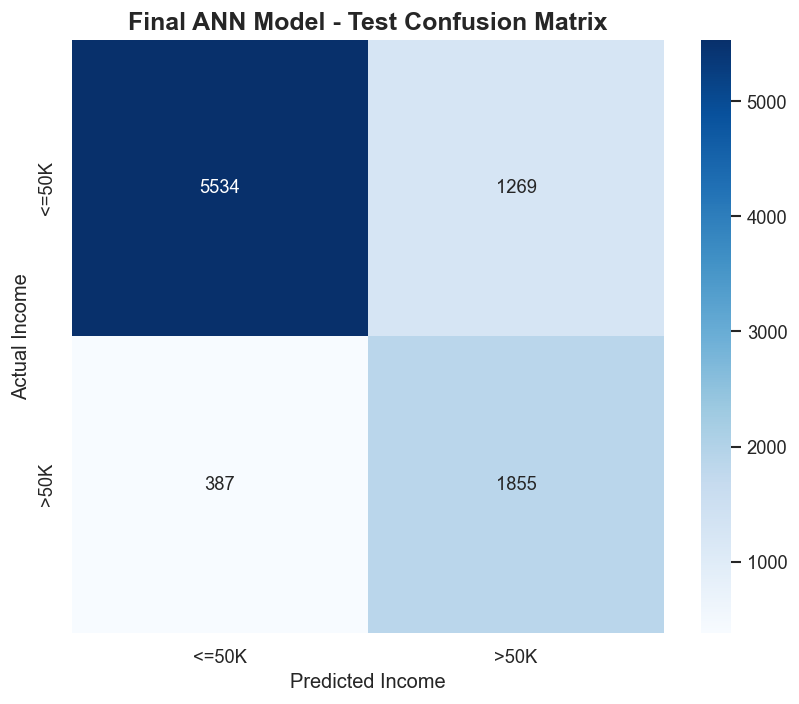

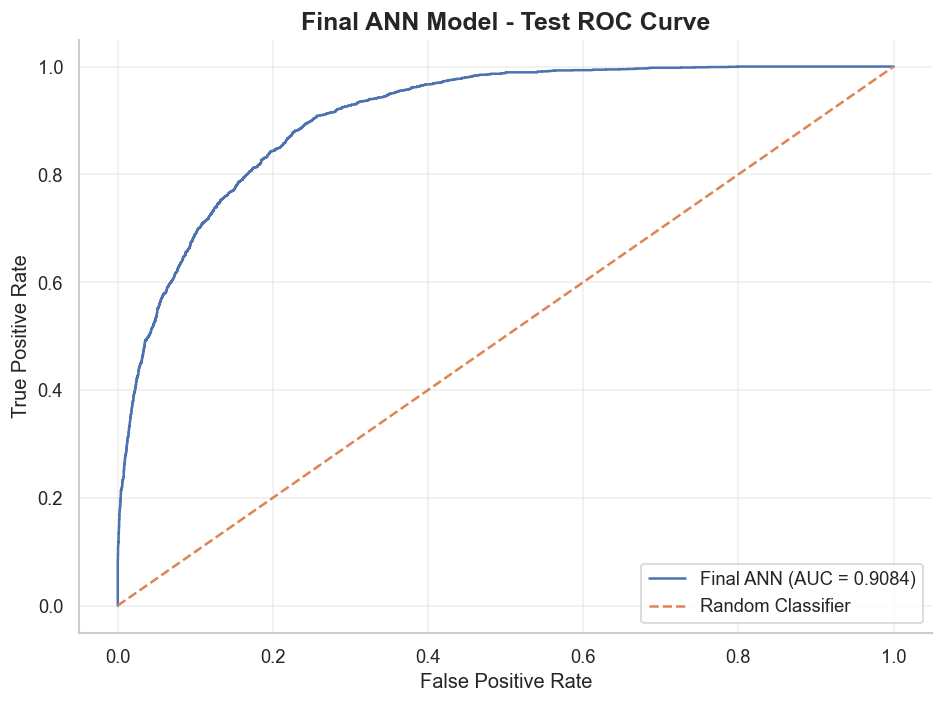


Final ANN model saved successfully.

TASK 7.6: FINAL PERFORMANCE COMPARISON

OVERALL MODEL PERFORMANCE


,Experiment,Evaluation,Accuracy,Precision,Recall,F1,ROC_AUC
0,Task 2 - Baseline ANN,Test,0.8304,0.6871,0.5798,0.6289,0.8789
1,Task 2 - Early Stopping,Test,0.8505,0.7636,0.5749,0.6560,0.9101
2,Task 3 - ELU,Validation,0.8521,0.7631,0.5853,0.6625,0.9059
3,Task 3 - Sigmoid,Validation,0.8541,0.7860,0.5652,0.6576,0.9144
4,Task 4 - He Uniform,Validation,0.8513,0.7568,0.5897,0.6629,0.9060
5,Task 5 - Focal Loss,Validation,0.8184,0.5968,0.8250,0.6926,0.9019
6,Task 6 - Without BN,Test,0.8381,0.7080,0.5905,0.6440,0.8877
7,Task 6 - With BN,Test,0.8163,0.6583,0.5379,0.5920,0.8581
8,Task 7 - Final Optimized ANN,Test,0.8169,0.5938,0.8274,0.6914,0.9084


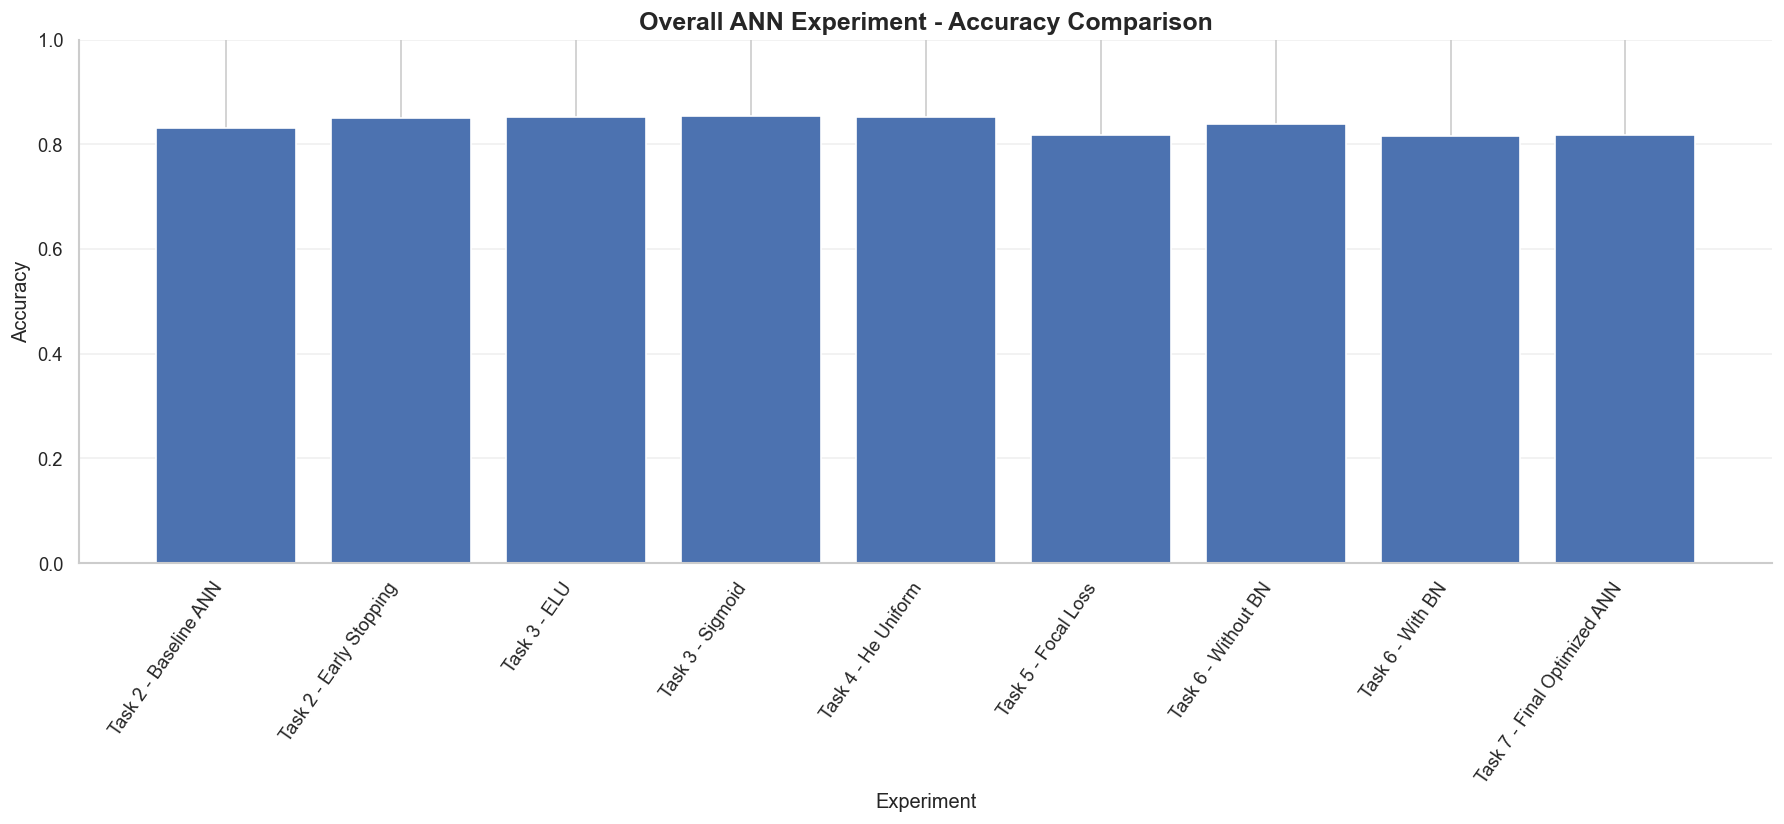

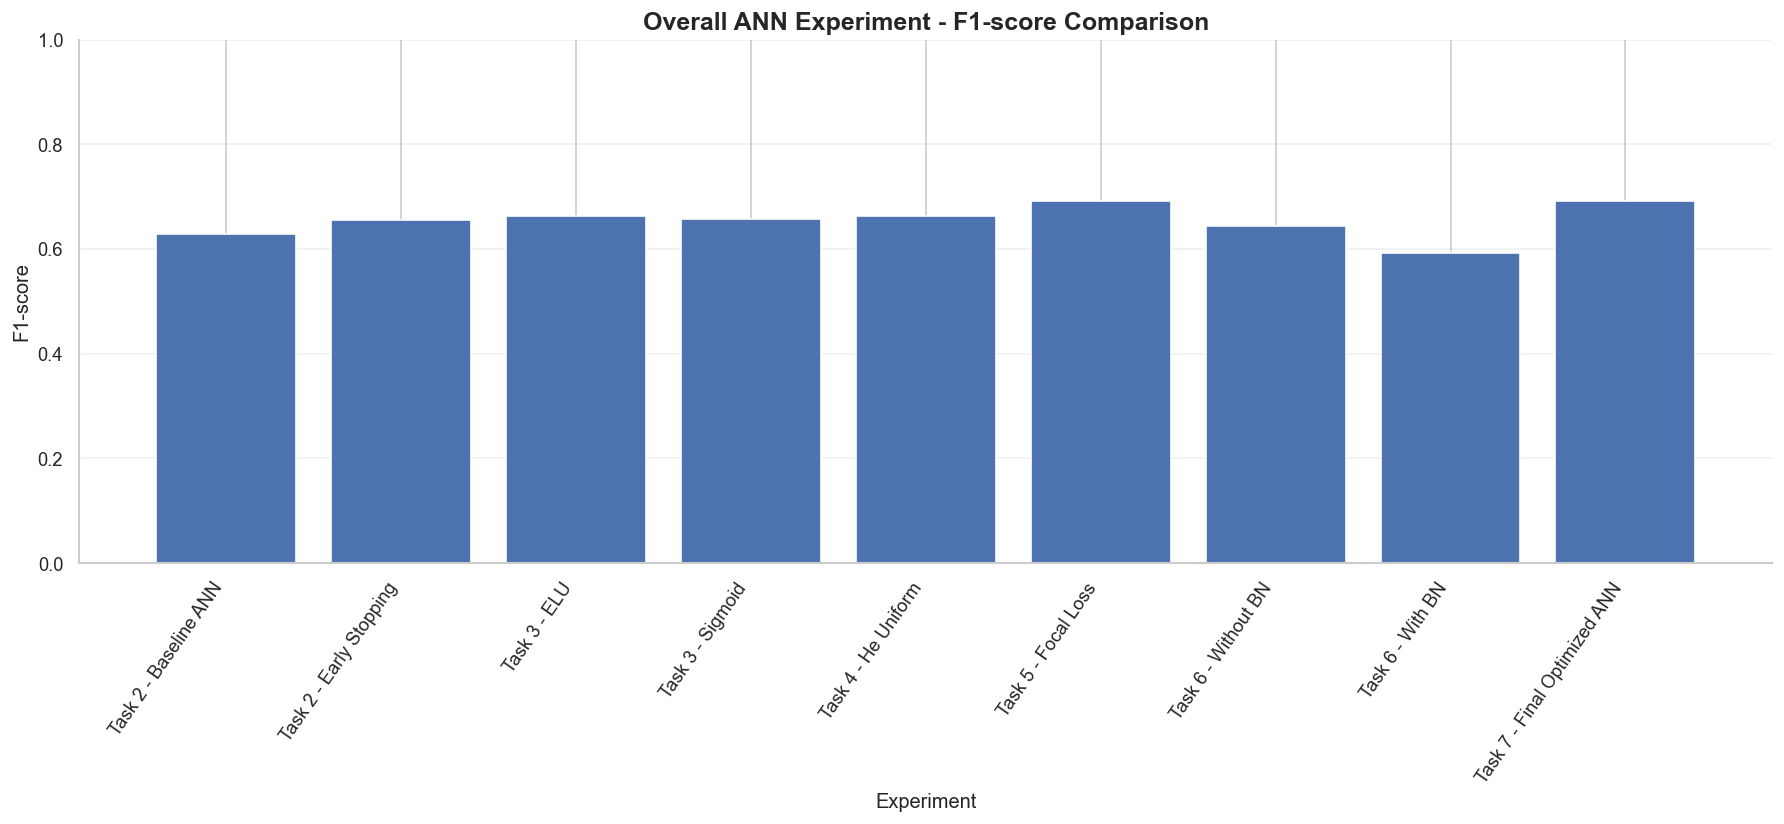


TASK 7: EXPORTING RESULTS

TASK 7 FINAL VERIFICATION
PASS: Five optimizer experiments completed.
PASS: Seven learning-rate experiments completed.
PASS: Final ANN trained and evaluated.
PASS: Final test metrics generated.
PASS: Historical comparison table created.
PASS: Metric range verification completed.

FINAL OPTIMIZER: SGD Momentum
FINAL LEARNING RATE: 0.0001

FINAL TEST ACCURACY: 0.8169
FINAL TEST F1-SCORE: 0.6914
FINAL TEST ROC-AUC: 0.9084

TASK 7: ALL EXPERIMENTS COMPLETED


In [26]:
# =============================================================================
# TASK 7: OPTIMIZERS - CONVERGENCE AND FINAL COMPARISON
# PROJECT: ADULT INCOME PREDICTION USING ARTIFICIAL NEURAL NETWORKS
# =============================================================================

print("\n" + "=" * 100)
print("TASK 7: OPTIMIZERS - CONVERGENCE AND FINAL COMPARISON")
print("=" * 100)

# =============================================================================
# 0. DATA VALIDATION AND CONFIGURATION
# =============================================================================

from pathlib import Path

required_variables = [
    "X_train_exp", "X_val_exp",
    "y_train_exp", "y_val_exp",
    "X_test", "y_test",
    "SEED", "PLOTS_DIR"
]

missing_variables = [
    variable for variable in required_variables
    if variable not in globals()
]

if missing_variables:
    raise NameError(
        f"Missing variables: {missing_variables}. "
        "Execute Tasks 1 and 2 first."
    )

Xtr = np.asarray(X_train_exp, dtype=np.float32)
Xval = np.asarray(X_val_exp, dtype=np.float32)
Xte = np.asarray(X_test, dtype=np.float32)

ytr = np.asarray(y_train_exp, dtype=np.float32).reshape(-1)
yval = np.asarray(y_val_exp, dtype=np.float32).reshape(-1)
yte = np.asarray(y_test, dtype=np.float32).reshape(-1)

assert Xtr.shape[1] == Xval.shape[1] == Xte.shape[1]
assert len(Xtr) == len(ytr)
assert len(Xval) == len(yval)
assert len(Xte) == len(yte)

assert np.isfinite(Xtr).all()
assert np.isfinite(Xval).all()
assert np.isfinite(Xte).all()

INPUT_DIM = Xtr.shape[1]

TASK7_DIR = Path.cwd()
TASK7_PLOTS = Path(PLOTS_DIR)
TASK7_PLOTS.mkdir(parents=True, exist_ok=True)

SEED = int(SEED)

print("\nDATASET CONFIGURATION")
print("-" * 80)
print("Training samples   :", len(Xtr))
print("Validation samples :", len(Xval))
print("Testing samples    :", len(Xte))
print("Input features     :", INPUT_DIM)
print("Training split and validation split verified.")

# =============================================================================
# 7.1 COMPARISON OF DIFFERENT OPTIMIZERS
# =============================================================================

print("\n" + "=" * 100)
print("TASK 7.1: COMPARISON OF DIFFERENT OPTIMIZERS")
print("=" * 100)

OPT_EPOCHS = 50
OPT_BATCH = 64
OPT_LR = 0.001

def create_optimizer_model(optimizer):

    model = Sequential([
        Input(shape=(INPUT_DIM,)),

        Dense(
            128,
            activation="relu",
            kernel_initializer="he_normal"
        ),

        Dense(
            64,
            activation="relu",
            kernel_initializer="he_normal"
        ),

        Dense(
            1,
            activation="sigmoid",
            kernel_initializer="glorot_uniform"
        )
    ])

    model.compile(
        optimizer=optimizer,
        loss=BinaryCrossentropy(),
        metrics=[
            keras.metrics.BinaryAccuracy(name="accuracy"),
            Precision(name="precision"),
            Recall(name="recall")
        ]
    )

    return model


optimizer_factories = {

    "SGD": lambda: SGD(
        learning_rate=OPT_LR
    ),

    "SGD Momentum": lambda: SGD(
        learning_rate=OPT_LR,
        momentum=0.9
    ),

    "RMSprop": lambda: RMSprop(
        learning_rate=OPT_LR,
        rho=0.9
    ),

    "Adam": lambda: Adam(
        learning_rate=OPT_LR
    ),

    "Adam AMSGrad": lambda: Adam(
        learning_rate=OPT_LR,
        beta_1=0.9,
        beta_2=0.999,
        epsilon=1e-7,
        amsgrad=True
    )
}

optimizer_models = {}
optimizer_histories = {}
optimizer_results = []

for index, (name, factory) in enumerate(
    optimizer_factories.items(), start=1
):

    print("\n" + "-" * 90)
    print(f"OPTIMIZER EXPERIMENT {index}: {name}")
    print("-" * 90)

    tf.keras.backend.clear_session()

    random.seed(SEED)
    np.random.seed(SEED)
    tf.random.set_seed(SEED)

    model = create_optimizer_model(factory())

    history = model.fit(
        Xtr,
        ytr,
        validation_data=(Xval, yval),
        epochs=OPT_EPOCHS,
        batch_size=OPT_BATCH,
        shuffle=True,
        verbose=1
    )

    optimizer_models[name] = model
    optimizer_histories[name] = pd.DataFrame(history.history)

    probabilities = model.predict(Xval, verbose=0).ravel()
    predictions = (probabilities >= 0.5).astype(int)

    hist = history.history

    result = {
        "Optimizer": name,
        "Final_Training_Accuracy": hist["accuracy"][-1],
        "Final_Validation_Accuracy": hist["val_accuracy"][-1],
        "Best_Validation_Accuracy": max(hist["val_accuracy"]),
        "Final_Training_Loss": hist["loss"][-1],
        "Final_Validation_Loss": hist["val_loss"][-1],
        "Minimum_Validation_Loss": min(hist["val_loss"]),
        "Validation_Precision": precision_score(
            yval, predictions, zero_division=0
        ),
        "Validation_Recall": recall_score(
            yval, predictions, zero_division=0
        ),
        "Validation_F1": f1_score(
            yval, predictions, zero_division=0
        ),
        "Validation_ROC_AUC": roc_auc_score(
            yval, probabilities
        ),
        "Best_Accuracy_Epoch": int(
            np.argmax(hist["val_accuracy"]) + 1
        ),
        "Best_Loss_Epoch": int(
            np.argmin(hist["val_loss"]) + 1
        )
    }

    reached_80 = np.where(
        np.asarray(hist["val_accuracy"]) >= 0.80
    )[0]

    result["First_Epoch_80_Accuracy"] = (
        int(reached_80[0] + 1)
        if len(reached_80) else np.nan
    )

    optimizer_results.append(result)

optimizer_comparison_df = pd.DataFrame(optimizer_results)

optimizer_comparison_df = optimizer_comparison_df.sort_values(
    ["Validation_F1", "Validation_ROC_AUC"],
    ascending=[False, False]
).reset_index(drop=True)

print("\nOPTIMIZER COMPARISON")
display(optimizer_comparison_df.round(4))

best_optimizer_name = optimizer_comparison_df.iloc[0]["Optimizer"]

print("\nBest optimizer based on validation F1:", best_optimizer_name)


# =============================================================================
# 7.2 OPTIMIZER CONVERGENCE ANALYSIS
# =============================================================================

print("\n" + "=" * 100)
print("TASK 7.2: OPTIMIZER CONVERGENCE ANALYSIS")
print("=" * 100)

# Training and validation accuracy

plt.figure(figsize=(14, 7))

for name, history_df in optimizer_histories.items():

    plt.plot(
        history_df["val_accuracy"],
        label=name
    )

plt.axhline(
    0.80,
    linestyle="--",
    label="80% Accuracy Reference"
)

plt.title("Optimizer Convergence - Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    TASK7_PLOTS / "32_optimizer_convergence_accuracy.png",
    dpi=300
)

plt.show()


# Training and validation loss

plt.figure(figsize=(14, 7))

for name, history_df in optimizer_histories.items():

    plt.plot(
        history_df["val_loss"],
        label=name
    )

plt.title("Optimizer Convergence - Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Validation Binary Crossentropy Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    TASK7_PLOTS / "33_optimizer_convergence_loss.png",
    dpi=300
)

plt.show()


# =============================================================================
# 7.3 UNDERSTANDING ADAM OPTIMIZATION
# =============================================================================

print("\n" + "=" * 100)
print("TASK 7.3: MATHEMATICAL UNDERSTANDING OF ADAM OPTIMIZER")
print("=" * 100)

adam_theory = """

1. STOCHASTIC GRADIENT DESCENT
   Updates model weights using the calculated gradient.

2. MOMENTUM
   Uses previous gradients to maintain an accumulated update direction.

3. FIRST MOMENT ESTIMATE
   m(t) = beta1 * m(t-1) + (1-beta1) * gradient

4. SECOND MOMENT ESTIMATE
   v(t) = beta2 * v(t-1) + (1-beta2) * gradient^2

5. BIAS CORRECTION
   Corrects the initialization bias in the moment estimates.

6. ADAPTIVE LEARNING RATE
   Adjusts the update magnitude according to the estimated
   first and second moments.

7. PARAMETER UPDATE
   theta(t+1) = theta(t) - learning_rate *
                corrected_first_moment /
                (sqrt(corrected_second_moment) + epsilon)

CONCLUSION:
Adam combines momentum and adaptive learning-rate mechanisms.
It often converges efficiently, but does not guarantee the
best validation or test generalization in every experiment.
"""

print(adam_theory)

with open(
    TASK7_DIR / "task7_adam_theoretical_explanation.txt",
    "w",
    encoding="utf-8"
) as file:

    file.write(adam_theory)


# =============================================================================
# 7.4 LEARNING RATE SENSITIVITY ANALYSIS
# =============================================================================

print("\n" + "=" * 100)
print("TASK 7.4: LEARNING RATE SENSITIVITY ANALYSIS")
print("=" * 100)

learning_rate_configs = {

    "SGD": {
        0.0001: lambda lr: SGD(learning_rate=lr),
        0.001: lambda lr: SGD(learning_rate=lr),
        0.01: lambda lr: SGD(learning_rate=lr),
        0.1: lambda lr: SGD(learning_rate=lr)
    },

    "Adam": {
        0.0001: lambda lr: Adam(learning_rate=lr),
        0.001: lambda lr: Adam(learning_rate=lr),
        0.01: lambda lr: Adam(learning_rate=lr)
    }
}

LR_EPOCHS = 30

lr_histories = {}
lr_results = []

for optimizer_type, configurations in learning_rate_configs.items():

    for learning_rate, factory in configurations.items():

        experiment_name = f"{optimizer_type}_LR_{learning_rate}"

        print("\nTraining:", experiment_name)

        tf.keras.backend.clear_session()

        random.seed(SEED)
        np.random.seed(SEED)
        tf.random.set_seed(SEED)

        model = create_optimizer_model(
            factory(learning_rate)
        )

        history = model.fit(
            Xtr,
            ytr,
            validation_data=(Xval, yval),
            epochs=LR_EPOCHS,
            batch_size=OPT_BATCH,
            shuffle=True,
            verbose=0
        )

        lr_histories[experiment_name] = pd.DataFrame(
            history.history
        )

        probabilities = model.predict(
            Xval,
            verbose=0
        ).ravel()

        predictions = (
            probabilities >= 0.5
        ).astype(int)

        lr_results.append({

            "Optimizer": optimizer_type,
            "Learning_Rate": learning_rate,

            "Final_Validation_Accuracy":
                history.history["val_accuracy"][-1],

            "Best_Validation_Accuracy":
                max(history.history["val_accuracy"]),

            "Final_Validation_Loss":
                history.history["val_loss"][-1],

            "Minimum_Validation_Loss":
                min(history.history["val_loss"]),

            "Validation_F1":
                f1_score(
                    yval, predictions, zero_division=0
                ),

            "Validation_ROC_AUC":
                roc_auc_score(
                    yval, probabilities
                ),

            "Best_Loss_Epoch":
                int(
                    np.argmin(
                        history.history["val_loss"]
                    ) + 1
                )
        })


lr_comparison_df = pd.DataFrame(lr_results)

print("\nLEARNING RATE COMPARISON")
display(lr_comparison_df.round(4))


# Plot SGD learning-rate sensitivity

plt.figure(figsize=(12, 6))

for name, history_df in lr_histories.items():

    if name.startswith("SGD_"):

        plt.plot(
            history_df["val_loss"],
            label=name
        )

plt.title("SGD Learning Rate Sensitivity")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    TASK7_PLOTS / "34_sgd_learning_rate_comparison.png",
    dpi=300
)

plt.show()


# Plot Adam learning-rate sensitivity

plt.figure(figsize=(12, 6))

for name, history_df in lr_histories.items():

    if name.startswith("Adam_"):

        plt.plot(
            history_df["val_loss"],
            label=name
        )

plt.title("Adam Learning Rate Sensitivity")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    TASK7_PLOTS / "35_adam_learning_rate_comparison.png",
    dpi=300
)

plt.show()


# Select optimizer and learning rate using validation F1,
# followed by ROC-AUC and validation loss.

combined_lr_ranking = lr_comparison_df.sort_values(
    ["Validation_F1", "Validation_ROC_AUC", "Minimum_Validation_Loss"],
    ascending=[False, False, True]
).reset_index(drop=True)

best_lr_row = combined_lr_ranking.iloc[0]

BEST_FINAL_OPTIMIZER = best_lr_row["Optimizer"]
BEST_FINAL_LR = float(best_lr_row["Learning_Rate"])

print("\nBEST LEARNING RATE CONFIGURATION")
display(combined_lr_ranking.head(5).round(4))

print("Selected optimizer :", BEST_FINAL_OPTIMIZER)
print("Selected learning rate :", BEST_FINAL_LR)


# =============================================================================
# 7.5 FINAL OPTIMIZED ANN MODEL
# =============================================================================

print("\n" + "=" * 100)
print("TASK 7.5: FINAL OPTIMIZED ANN MODEL")
print("=" * 100)

# Use the best findings from Tasks 3, 4 and 5.
# Task 6 showed that Batch Normalization reduced test performance.
# Therefore, the final architecture does not include Batch Normalization.

FINAL_ACTIVATION = "elu"
FINAL_INITIALIZER = "he_uniform"
FINAL_FOCAL_ALPHA = 0.7521729782855738
FINAL_FOCAL_GAMMA = 2.0

@keras.utils.register_keras_serializable(
    package="AdultIncome"
)
class FinalFocalLoss(keras.losses.Loss):

    def __init__(
        self,
        alpha=FINAL_FOCAL_ALPHA,
        gamma=FINAL_FOCAL_GAMMA,
        name="final_focal_loss",
        **kwargs
    ):

        super().__init__(name=name, **kwargs)

        self.alpha = alpha
        self.gamma = gamma

    def call(self, y_true, y_pred):

        y_true = tf.cast(
            tf.reshape(y_true, (-1, 1)),
            tf.float32
        )

        y_pred = tf.cast(y_pred, tf.float32)

        epsilon = keras.backend.epsilon()

        y_pred = tf.clip_by_value(
            y_pred,
            epsilon,
            1.0 - epsilon
        )

        cross_entropy = -(
            y_true * tf.math.log(y_pred)
            +
            (1.0 - y_true) * tf.math.log(1.0 - y_pred)
        )

        p_t = (
            y_true * y_pred
            +
            (1.0 - y_true) * (1.0 - y_pred)
        )

        alpha_t = (
            y_true * self.alpha
            +
            (1.0 - y_true) * (1.0 - self.alpha)
        )

        focal_factor = tf.pow(
            1.0 - p_t,
            self.gamma
        )

        return tf.reduce_mean(
            alpha_t * focal_factor * cross_entropy
        )

    def get_config(self):

        config = super().get_config()

        config.update({
            "alpha": self.alpha,
            "gamma": self.gamma
        })

        return config


# Create final optimizer using selected learning rate.

if BEST_FINAL_OPTIMIZER == "SGD":

    final_optimizer = SGD(
        learning_rate=BEST_FINAL_LR
    )

elif BEST_FINAL_OPTIMIZER == "Adam":

    final_optimizer = Adam(
        learning_rate=BEST_FINAL_LR
    )

final_model = Sequential(
    name="Final_Adult_Income_ANN"
)

final_model.add(
    Input(shape=(INPUT_DIM,))
)

final_model.add(
    Dense(
        128,
        activation=FINAL_ACTIVATION,
        kernel_initializer=FINAL_INITIALIZER
    )
)

final_model.add(
    Dense(
        64,
        activation=FINAL_ACTIVATION,
        kernel_initializer=FINAL_INITIALIZER
    )
)

final_model.add(
    Dense(
        1,
        activation="sigmoid",
        kernel_initializer="glorot_uniform"
    )
)

final_model.compile(
    optimizer=final_optimizer,
    loss=FinalFocalLoss(),
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        Precision(name="precision"),
        Recall(name="recall")
    ]
)

print("\nFINAL MODEL ARCHITECTURE")
final_model.summary()

print("\nFINAL MODEL CONFIGURATION")
print("Activation Function :", FINAL_ACTIVATION)
print("Weight Initializer  :", FINAL_INITIALIZER)
print("Loss Function       : Focal Loss")
print("Optimizer           :", BEST_FINAL_OPTIMIZER)
print("Learning Rate       :", BEST_FINAL_LR)
print("Batch Normalization : Disabled")
print("Epochs              : 80")
print("Batch Size          : 64")


# Train final model with early stopping.

final_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    min_delta=0.001,
    restore_best_weights=True,
    verbose=1
)

final_history = final_model.fit(
    Xtr,
    ytr,
    validation_data=(Xval, yval),
    epochs=80,
    batch_size=64,
    shuffle=True,
    callbacks=[final_early_stopping],
    verbose=1
)


# Validation evaluation

final_val_probabilities = final_model.predict(
    Xval,
    verbose=0
).ravel()

final_val_predictions = (
    final_val_probabilities >= 0.5
).astype(int)

final_validation_results = {

    "Validation_Accuracy": accuracy_score(
        yval, final_val_predictions
    ),

    "Validation_Precision": precision_score(
        yval, final_val_predictions, zero_division=0
    ),

    "Validation_Recall": recall_score(
        yval, final_val_predictions, zero_division=0
    ),

    "Validation_F1": f1_score(
        yval, final_val_predictions, zero_division=0
    ),

    "Validation_ROC_AUC": roc_auc_score(
        yval, final_val_probabilities
    )
}

print("\nFINAL MODEL VALIDATION RESULTS")
display(
    pd.DataFrame(
        [final_validation_results]
    ).round(4)
)


# =============================================================================
# FINAL TEST EVALUATION - EXECUTED ONLY AFTER MODEL SELECTION
# =============================================================================

print("\nFINAL MODEL TEST EVALUATION")
print("-" * 80)

test_probabilities = final_model.predict(
    Xte,
    verbose=0
).ravel()

test_predictions = (
    test_probabilities >= 0.5
).astype(int)

final_test_results = {

    "Test_Accuracy": accuracy_score(
        yte, test_predictions
    ),

    "Test_Precision": precision_score(
        yte, test_predictions, zero_division=0
    ),

    "Test_Recall": recall_score(
        yte, test_predictions, zero_division=0
    ),

    "Test_F1": f1_score(
        yte, test_predictions, zero_division=0
    ),

    "Test_ROC_AUC": roc_auc_score(
        yte, test_probabilities
    )
}

display(
    pd.DataFrame(
        [final_test_results]
    ).round(4)
)

print("\nFINAL CLASSIFICATION REPORT")

print(
    classification_report(
        yte,
        test_predictions,
        target_names=["<=50K", ">50K"],
        zero_division=0
    )
)


# Confusion matrix

final_cm = confusion_matrix(
    yte,
    test_predictions
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    final_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["<=50K", ">50K"],
    yticklabels=["<=50K", ">50K"]
)

plt.title("Final ANN Model - Test Confusion Matrix")
plt.xlabel("Predicted Income")
plt.ylabel("Actual Income")
plt.tight_layout()

plt.savefig(
    TASK7_PLOTS / "36_final_model_confusion_matrix.png",
    dpi=300
)

plt.show()


# Final ROC curve

final_fpr, final_tpr, _ = roc_curve(
    yte,
    test_probabilities
)

plt.figure(figsize=(8, 6))

plt.plot(
    final_fpr,
    final_tpr,
    label=f"Final ANN (AUC = {final_test_results['Test_ROC_AUC']:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("Final ANN Model - Test ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    TASK7_PLOTS / "37_final_model_roc_curve.png",
    dpi=300
)

plt.show()


# Save final model.

final_model.save(
    TASK7_DIR / "task7_final_optimized_ann.keras"
)

print("\nFinal ANN model saved successfully.")


# =============================================================================
# 7.6 FINAL PERFORMANCE COMPARISON
# =============================================================================

print("\n" + "=" * 100)
print("TASK 7.6: FINAL PERFORMANCE COMPARISON")
print("=" * 100)

# Historical values below are the previously recorded results.
# N/A is used where the corresponding metric was not recorded.
# Do not treat different experiment stages as perfectly controlled comparisons.

historical_results = [

    {
        "Experiment": "Task 2 - Baseline ANN",
        "Evaluation": "Test",
        "Accuracy": 0.8304,
        "Precision": 0.6871,
        "Recall": 0.5798,
        "F1": 0.6289,
        "ROC_AUC": 0.8789
    },

    {
        "Experiment": "Task 2 - Early Stopping",
        "Evaluation": "Test",
        "Accuracy": 0.8505,
        "Precision": 0.7636,
        "Recall": 0.5749,
        "F1": 0.6560,
        "ROC_AUC": 0.9101
    },

    {
        "Experiment": "Task 3 - ELU",
        "Evaluation": "Validation",
        "Accuracy": 0.8521,
        "Precision": 0.7631,
        "Recall": 0.5853,
        "F1": 0.6625,
        "ROC_AUC": 0.9059
    },

    {
        "Experiment": "Task 3 - Sigmoid",
        "Evaluation": "Validation",
        "Accuracy": 0.8541,
        "Precision": 0.7860,
        "Recall": 0.5652,
        "F1": 0.6576,
        "ROC_AUC": 0.9144
    },

    {
        "Experiment": "Task 4 - He Uniform",
        "Evaluation": "Validation",
        "Accuracy": 0.8513,
        "Precision": 0.7568,
        "Recall": 0.5897,
        "F1": 0.6629,
        "ROC_AUC": 0.9060
    },

    {
        "Experiment": "Task 5 - Focal Loss",
        "Evaluation": "Validation",
        "Accuracy": 0.8184,
        "Precision": 0.5968,
        "Recall": 0.8250,
        "F1": 0.6926,
        "ROC_AUC": 0.9019
    },

    {
        "Experiment": "Task 6 - Without BN",
        "Evaluation": "Test",
        "Accuracy": 0.8381,
        "Precision": 0.7080,
        "Recall": 0.5905,
        "F1": 0.6440,
        "ROC_AUC": 0.8877
    },

    {
        "Experiment": "Task 6 - With BN",
        "Evaluation": "Test",
        "Accuracy": 0.8163,
        "Precision": 0.6583,
        "Recall": 0.5379,
        "F1": 0.5920,
        "ROC_AUC": 0.8581
    },

    {
        "Experiment": "Task 7 - Final Optimized ANN",
        "Evaluation": "Test",
        "Accuracy": final_test_results["Test_Accuracy"],
        "Precision": final_test_results["Test_Precision"],
        "Recall": final_test_results["Test_Recall"],
        "F1": final_test_results["Test_F1"],
        "ROC_AUC": final_test_results["Test_ROC_AUC"]
    }
]

final_comparison_df = pd.DataFrame(
    historical_results
)

print("\nOVERALL MODEL PERFORMANCE")
display(
    final_comparison_df.round(4)
)


# Final model comparison chart

plt.figure(figsize=(15, 7))

plot_df = final_comparison_df.dropna(
    subset=["Accuracy"]
)

plt.bar(
    plot_df["Experiment"],
    plot_df["Accuracy"]
)

plt.title("Overall ANN Experiment - Accuracy Comparison")
plt.xlabel("Experiment")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

plt.xticks(
    rotation=55,
    ha="right"
)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    TASK7_PLOTS / "38_overall_accuracy_comparison.png",
    dpi=300
)

plt.show()


# F1-score comparison

plt.figure(figsize=(15, 7))

plt.bar(
    final_comparison_df["Experiment"],
    final_comparison_df["F1"]
)

plt.title("Overall ANN Experiment - F1-score Comparison")
plt.xlabel("Experiment")
plt.ylabel("F1-score")
plt.ylim(0, 1)

plt.xticks(
    rotation=55,
    ha="right"
)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    TASK7_PLOTS / "39_overall_f1_comparison.png",
    dpi=300
)

plt.show()


# =============================================================================
# 7.7 EXPORT ALL TASK 7 RESULTS
# =============================================================================

print("\n" + "=" * 100)
print("TASK 7: EXPORTING RESULTS")
print("=" * 100)

optimizer_comparison_df.to_csv(
    TASK7_DIR / "task7_optimizer_comparison.csv",
    index=False
)

lr_comparison_df.to_csv(
    TASK7_DIR / "task7_learning_rate_comparison.csv",
    index=False
)

final_comparison_df.to_csv(
    TASK7_DIR / "task7_final_performance_comparison.csv",
    index=False
)

pd.DataFrame(
    [final_validation_results]
).to_csv(
    TASK7_DIR / "task7_final_validation_metrics.csv",
    index=False
)

pd.DataFrame(
    [final_test_results]
).to_csv(
    TASK7_DIR / "task7_final_test_metrics.csv",
    index=False
)

for name, history_df in optimizer_histories.items():

    safe_name = name.lower().replace(" ", "_")

    history_df.to_csv(
        TASK7_DIR / f"task7_{safe_name}_history.csv",
        index=False
    )

for name, history_df in lr_histories.items():

    safe_name = name.lower().replace(" ", "_")

    history_df.to_csv(
        TASK7_DIR / f"task7_{safe_name}_history.csv",
        index=False
    )

pd.DataFrame(
    final_history.history
).to_csv(
    TASK7_DIR / "task7_final_model_training_history.csv",
    index=False
)


# =============================================================================
# 7.8 FINAL VERIFICATION
# =============================================================================

print("\n" + "=" * 100)
print("TASK 7 FINAL VERIFICATION")
print("=" * 100)

assert len(optimizer_comparison_df) == 5
assert len(lr_comparison_df) == 7

assert final_comparison_df["Experiment"].is_unique

assert final_comparison_df["Accuracy"].between(
    0, 1
).all()

assert final_comparison_df["F1"].between(
    0, 1
).all()

assert np.isfinite(
    list(final_test_results.values())
).all()

print("PASS: Five optimizer experiments completed.")
print("PASS: Seven learning-rate experiments completed.")
print("PASS: Final ANN trained and evaluated.")
print("PASS: Final test metrics generated.")
print("PASS: Historical comparison table created.")
print("PASS: Metric range verification completed.")

print("\nFINAL OPTIMIZER:", best_optimizer_name)

print("FINAL LEARNING RATE:", BEST_FINAL_LR)

print("\nFINAL TEST ACCURACY:",
      f"{final_test_results['Test_Accuracy']:.4f}")

print("FINAL TEST F1-SCORE:",
      f"{final_test_results['Test_F1']:.4f}")

print("FINAL TEST ROC-AUC:",
      f"{final_test_results['Test_ROC_AUC']:.4f}")

print("\n" + "=" * 100)
print("TASK 7: ALL EXPERIMENTS COMPLETED")
print("=" * 100)
